<h1 align="center">SentinelAPI</h1>
<h3 align="center">AI-Driven OpenAPI Contract Tester &amp; Security Fuzzer</h3>
<h3 align="center">Data Preprocessing, Exploratory Data Analysis &amp; Visualisation</h3>

<p align="center"><b>Vellore Institute of Technology</b><br>Software Metrics</p>

<div align="center">

| Register Number | Student Name |
|:---|:---|
| 23mis0166 | Gondu Divitha |
| 23mis0158 | Devarla Sowmya Rai |
| 23mis0185 | K Meghana |
| 23mis0057 | Thatavarthi V S S M M Nagasri Kavya |

</div>

---

## 1. Introduction

### 1.1 The Project

**SentinelAPI** is an automated quality-assurance and security-fuzzing framework for REST APIs.

It works in five stages:

| Stage | What happens |
|:--|:--|
| **1. Parse** | Read the API's OpenAPI / Swagger specification and map every endpoint, method, parameter and validation rule |
| **2. Generate** | Create hostile test inputs using boundary-value heuristics **plus** LLM-generated context-aware payloads |
| **3. Attack** | Fire the payloads concurrently at the live API using an asynchronous HTTP client |
| **4. Observe** | Capture server responses and record code coverage on the target system |
| **5. Report** | Classify failures — schema violations, business-logic bypasses, SQL Injection, XSS, Path Traversal |

### 1.2 Why This Dataset

The **first thing SentinelAPI ever reads is an OpenAPI specification.** Everything the tool
does afterwards is decided by what it finds inside that document.

So the natural question for this analysis is:

> **What does the attack surface of real-world REST APIs actually look like?**

To answer it we use the **APIs.guru OpenAPI Directory** — an open, community-maintained
collection of machine-readable specifications for real, publicly deployed APIs
(Stripe, Slack, GitHub, Azure, Google, Twilio and hundreds more).

This is *exactly* the input format SentinelAPI consumes. No analogy or substitution is
needed to justify its relevance.

### 1.3 How the Dataset Was Constructed

The raw directory is a repository of **4,138 YAML specification files** — not a table.
A parser (`build_dataset.py`, included in this folder) was written to flatten it:

```
4,138 OpenAPI specifications
        |
        v   parse each spec, walk every path and method
154,145 endpoint records  ->  raw_api_endpoints.csv
```

**One row = one API endpoint** (one URL path combined with one HTTP method,
e.g. `POST /v1/customers`).

The directory stores several released versions of some APIs, so the raw extract contains
repeated endpoints. Section 4.2 removes these, leaving roughly **103,000 unique
endpoints** for the analysis.

The columns measure the properties SentinelAPI cares about: how many parameters an
endpoint exposes, how many of them carry validation rules, whether authentication is
enforced, and which error responses are declared.

### 1.4 Objectives

1. Clean and prepare the endpoint data (**Data Preprocessing**)
2. Understand the structure and weaknesses of real API contracts (**EDA**)
3. Communicate the findings graphically (**Visualisation**)
4. Derive evidence that justifies why an automated fuzzer like SentinelAPI is needed

---

## 2. Environment Setup

Importing the libraries and fixing a consistent visual style so that every chart in this
notebook looks the same.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings("ignore")

# ---- display options -------------------------------------------------------
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# ---- consistent chart styling ---------------------------------------------
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.dpi":        110,
    "savefig.dpi":       150,
    "savefig.bbox":      "tight",
    "figure.facecolor":  "white",
    "axes.facecolor":    "white",
    "axes.titlesize":    13,
    "axes.titleweight":  "bold",
    "axes.labelsize":    11,
    "axes.edgecolor":    "#cccccc",
    "grid.color":        "#e8e8e8",
    "font.size":         10,
    "legend.frameon":    False,
})

# project colour palette
NAVY, TEAL, AMBER, RED, GREY = "#1f3b73", "#2a9d8f", "#e9c46a", "#d62828", "#8d99ae"
RISK_COLORS = {"Low": TEAL, "Medium": AMBER, "High": RED}
SEQ = [NAVY, TEAL, AMBER, "#e76f51", GREY, "#457b9d", "#a8dadc", "#f4a261"]

# folder for exported chart images
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)


def save_fig(fig, name):
    # Save a figure into the figures/ folder so it can be reused in the report.
    path = os.path.join(FIG_DIR, f"{name}.png")
    fig.savefig(path)
    print(f"saved -> {path}")


print("Libraries loaded successfully.")
print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)

Libraries loaded successfully.
pandas 3.0.2 | numpy 2.4.4 | seaborn 0.13.2


## 3. Loading the Dataset

---

In [2]:
df_raw = pd.read_csv("data/raw_api_endpoints.csv.gz", low_memory=False)

print(f"Rows (API endpoints) : {df_raw.shape[0]:,}")
print(f"Columns (features)   : {df_raw.shape[1]}")
print(f"Memory usage         : {df_raw.memory_usage(deep=True).sum()/1024**2:,.1f} MB")
print(f"API providers        : {df_raw['api_provider'].nunique():,}")
print(f"Business categories  : {df_raw['category'].nunique()}")

Rows (API endpoints) : 154,145
Columns (features)   : 36
Memory usage         : 111.8 MB
API providers        : 685
Business categories  : 35


### 3.1 First look at the records

In [3]:
df_raw.head(8)

,api_provider,api_title,api_version,spec_version,category,path,http_method,path_depth,path_length_chars,has_description,is_deprecated,is_state_changing,num_path_params,num_query_params,num_header_params,num_cookie_params,total_params,num_required_params,num_optional_params,num_constrained_params,num_unconstrained_params,num_string_params,num_unconstrained_string_params,num_enum_params,num_pattern_params,num_length_bounded_params,num_numeric_range_params,has_request_body,body_required,num_response_codes,num_2xx_responses,num_4xx_responses,num_5xx_responses,has_default_response,requires_auth,num_security_schemes
0,1forge.com,1Forge Finance APIs,0.0.1,Swagger 2.0,financial,/quotes,GET,1,7,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0
1,1forge.com,1Forge Finance APIs,0.0.1,Swagger 2.0,financial,/symbols,GET,1,8,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0
2,1password.com,Events API,1.2.0,OpenAPI 3.x,security,/api/auth/introspect,GET,3,20,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,4,1,1,1,1,1,1
3,1password.com,Events API,1.2.0,OpenAPI 3.x,security,/api/v1/auditevents,POST,3,19,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,4,1,1,1,1,1,1
4,1password.com,Events API,1.2.0,OpenAPI 3.x,security,/api/v1/itemusages,POST,3,18,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,4,1,1,1,1,1,1
5,1password.com,Events API,1.2.0,OpenAPI 3.x,security,/api/v1/signinattempts,POST,3,22,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,4,1,1,1,1,1,1
6,1password.com,Events API,1.2.0,OpenAPI 3.x,security,/api/v2/auth/introspect,GET,4,23,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,4,1,1,1,1,1,1
7,1password.local,1Password Connect,1.5.7,OpenAPI 3.x,security,/activity,GET,1,9,1,0,0,0,2,0,0,2,0,2,0,2,0,0,0,0,0,0,0,0,2,1,1,0,0,1,1


### 3.2 What each column means

In [4]:
data_dictionary = pd.DataFrame([
    ("api_provider",  "Identity", "Domain that publishes the API (e.g. stripe.com)"),
    ("api_title",     "Identity", "Human-readable name of the API"),
    ("api_version",   "Identity", "Version string declared in the spec"),
    ("spec_version",  "Identity", "Swagger 2.0 or OpenAPI 3.x"),
    ("category",      "Identity", "Business category assigned by APIs.guru"),
    ("path",          "Identity", "URL path of the endpoint, e.g. /v1/customers/{id}"),
    ("http_method",   "Identity", "GET / POST / PUT / PATCH / DELETE / ..."),

    ("path_depth",         "Structure", "Number of segments in the URL path"),
    ("path_length_chars",  "Structure", "Character length of the path"),
    ("has_description",    "Structure", "1 if the endpoint is documented"),
    ("is_deprecated",      "Structure", "1 if marked deprecated"),
    ("is_state_changing",  "Structure", "1 for POST/PUT/PATCH/DELETE (writes data)"),

    ("num_path_params",     "Parameters", "Parameters embedded in the URL path"),
    ("num_query_params",    "Parameters", "Parameters passed in the query string"),
    ("num_header_params",   "Parameters", "Parameters passed as HTTP headers"),
    ("num_cookie_params",   "Parameters", "Parameters passed as cookies"),
    ("total_params",        "Parameters", "Total input parameters on the endpoint"),
    ("num_required_params", "Parameters", "Parameters the API declares mandatory"),
    ("num_optional_params", "Parameters", "Parameters that are optional"),

    ("num_constrained_params",          "Validation", "Params with >=1 validation rule"),
    ("num_unconstrained_params",        "Validation", "Params with NO validation rule"),
    ("num_string_params",               "Validation", "Params typed as string"),
    ("num_unconstrained_string_params", "Validation", "String params with no rule (injection surface)"),
    ("num_enum_params",                 "Validation", "Params restricted to a fixed value list"),
    ("num_pattern_params",              "Validation", "Params restricted by a regex pattern"),
    ("num_length_bounded_params",       "Validation", "Params with min/max length limits"),
    ("num_numeric_range_params",        "Validation", "Params with min/max numeric limits"),

    ("has_request_body", "Body", "1 if the endpoint accepts a request body"),
    ("body_required",    "Body", "1 if that body is mandatory"),

    ("num_response_codes",   "Responses", "How many response codes are documented"),
    ("num_2xx_responses",    "Responses", "Documented success responses"),
    ("num_4xx_responses",    "Responses", "Documented client-error responses"),
    ("num_5xx_responses",    "Responses", "Documented server-error responses"),
    ("has_default_response", "Responses", "1 if a fallback response is declared"),

    ("requires_auth",        "Security", "1 if authentication is enforced"),
    ("num_security_schemes", "Security", "Number of auth schemes the API defines"),
], columns=["Column", "Group", "Meaning"])

data_dictionary

,Column,Group,Meaning
0,api_provider,Identity,Domain that publishes the API (e.g. stripe.com)
1,api_title,Identity,Human-readable name of the API
2,api_version,Identity,Version string declared in the spec
3,spec_version,Identity,Swagger 2.0 or OpenAPI 3.x
4,category,Identity,Business category assigned by APIs.guru
5,path,Identity,"URL path of the endpoint, e.g. /v1/customers/{id}"
6,http_method,Identity,GET / POST / PUT / PATCH / DELETE / ...
7,path_depth,Structure,Number of segments in the URL path
8,path_length_chars,Structure,Character length of the path
9,has_description,Structure,1 if the endpoint is documented


### 3.3 Data types and non-null counts

In [5]:
info = pd.DataFrame({
    "dtype":      df_raw.dtypes.astype(str),
    "non_null":   df_raw.notna().sum(),
    "nulls":      df_raw.isna().sum(),
    "null_%":     (df_raw.isna().mean() * 100).round(2),
    "unique":     df_raw.nunique(),
})
info

,dtype,non_null,nulls,null_%,unique
api_provider,str,154145,0,0.000,685
api_title,str,153783,362,0.230,2183
api_version,str,154128,17,0.010,884
spec_version,str,154145,0,0.000,2
category,str,154145,0,0.000,35
path,str,154145,0,0.000,71240
http_method,str,154145,0,0.000,8
path_depth,int64,154145,0,0.000,20
path_length_chars,int64,154145,0,0.000,324
has_description,int64,154145,0,0.000,2


### 3.4 Statistical summary of the numeric features

In [6]:
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
path_depth,"154,145.000",4.840,3.060,0.000,3.000,4.000,7.000,19.000
path_length_chars,"154,145.000",62.780,47.390,1.000,28.000,47.000,84.000,380.000
has_description,"154,145.000",0.950,0.210,0.000,1.000,1.000,1.000,1.000
is_deprecated,"154,145.000",0.010,0.120,0.000,0.000,0.000,0.000,1.000
is_state_changing,"154,145.000",0.520,0.500,0.000,0.000,1.000,1.000,1.000
num_path_params,"154,145.000",1.580,1.420,0.000,0.000,1.000,3.000,9.000
num_query_params,"154,145.000",2.490,5.620,0.000,0.000,1.000,2.000,582.000
num_header_params,"154,145.000",1.030,2.370,0.000,0.000,0.000,0.000,39.000
num_cookie_params,"154,145.000",0.000,0.000,0.000,0.000,0.000,0.000,0.000
total_params,"154,145.000",5.180,5.810,0.000,2.000,4.000,8.000,582.000


**Early observations from the summary above**

* `total_params` has a maximum of **582** on a single endpoint while the median is only
  **4** — a very long right tail that will need outlier treatment.
* `num_constrained_params` has a mean far below `total_params`, the first sign that most
  real API parameters carry **no validation rules at all**.
* Several columns are binary flags (min 0, max 1) and should be treated as categorical.

---

# 4. Data Preprocessing

Raw data is never analysis-ready. This section performs the standard preparation pipeline:

```
Missing values -> Duplicates -> Outliers -> Feature engineering
        -> Target variable -> Encoding -> Scaling -> Clean dataset
```

In [7]:
df = df_raw.copy()          # keep df_raw untouched for before/after comparisons
print(f"Working copy created: {df.shape[0]:,} rows x {df.shape[1]} columns")

Working copy created: 154,145 rows x 36 columns


## 4.1 Handling Missing Values

### Step 1 — Detect

In [8]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct":   (df.isna().mean() * 100).round(3),
})
missing = missing[missing.missing_count > 0].sort_values("missing_count", ascending=False)

if missing.empty:
    print("No missing values found.")
else:
    print(f"Columns containing missing values: {len(missing)}")
    print(f"Total missing cells: {int(df.isna().sum().sum()):,} "
          f"({df.isna().sum().sum()/df.size*100:.4f}% of all cells)")
display(missing)

Columns containing missing values: 2
Total missing cells: 379 (0.0068% of all cells)


,missing_count,missing_pct
api_title,362,0.235
api_version,17,0.011


### Step 2 — Visualise

saved -> figures/01_missing_values.png


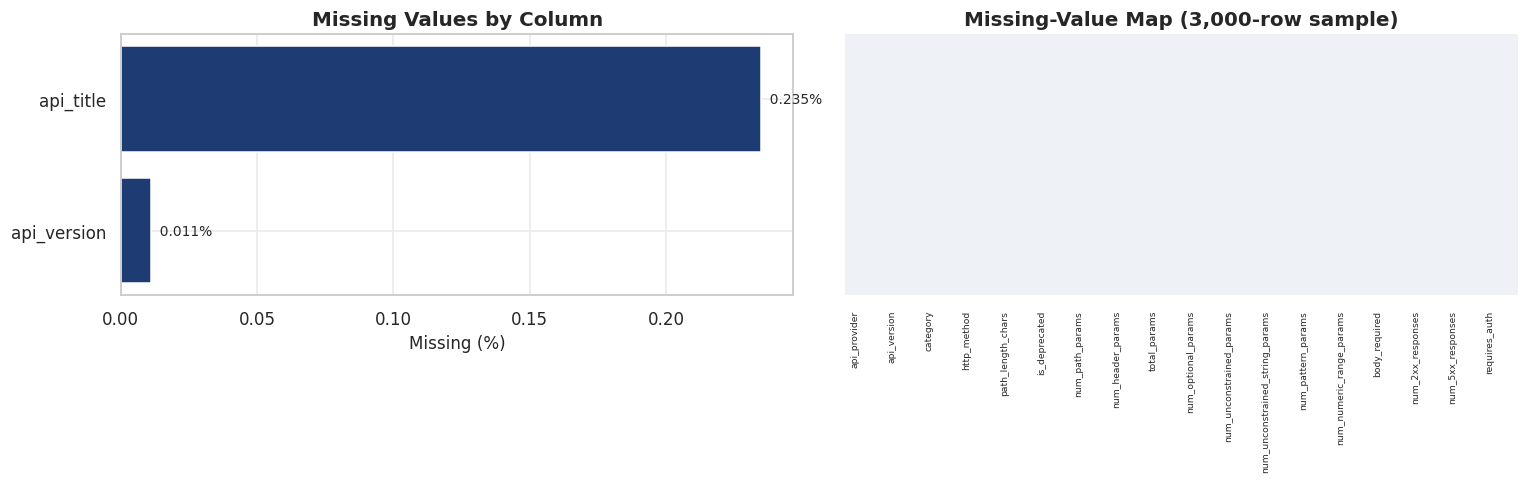

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# left: bar chart of missing percentage
axes[0].barh(missing.index, missing["missing_pct"], color=NAVY)
axes[0].set_xlabel("Missing (%)")
axes[0].set_title("Missing Values by Column")
axes[0].invert_yaxis()
for i, v in enumerate(missing["missing_pct"]):
    axes[0].text(v, i, f"  {v:.3f}%", va="center", fontsize=9)

# right: heatmap of a sample, showing where the gaps sit
sample = df.sample(n=min(3000, len(df)), random_state=42)
sns.heatmap(sample.isna(), cbar=False, yticklabels=False,
            cmap=["#eef2f7", RED], ax=axes[1])
axes[1].set_title("Missing-Value Map (3,000-row sample)")
axes[1].tick_params(axis="x", rotation=90, labelsize=6)

plt.tight_layout()
save_fig(fig, "01_missing_values")
plt.show()

### Step 3 — Treat

The missing values sit only in two **descriptive text** columns, `api_title` and
`api_version`, and affect well under 1% of rows. A handful of specifications simply
omit these fields.

**Decision:** do not drop the rows. Losing 362 valid endpoints because a publisher
forgot to write a title would throw away good measurement data. Instead we impute with
an explicit marker so the gap stays visible and honest.

*(Deleting rows would be the wrong choice here — the missingness is in metadata, not
in any of the metrics we actually analyse.)*

In [10]:
before = int(df.isna().sum().sum())

df["api_title"]   = df["api_title"].fillna("Unknown API")
df["api_version"] = df["api_version"].fillna("unspecified")

after = int(df.isna().sum().sum())
print(f"Missing cells before : {before:,}")
print(f"Missing cells after  : {after:,}")
print(f"Rows retained        : {len(df):,} (none dropped)")

Missing cells before : 379
Missing cells after  : 0
Rows retained        : 154,145 (none dropped)


## 4.2 Removing Duplicate Records

An endpoint is uniquely identified by **provider + path + method**. The directory stores
multiple versions of some APIs, so the same endpoint can appear more than once. Keeping
duplicates would silently over-weight large, frequently-versioned APIs such as Azure.

In [11]:
full_dupes = df.duplicated().sum()
key = ["api_provider", "path", "http_method"]
key_dupes = df.duplicated(subset=key).sum()

print(f"Fully identical rows            : {full_dupes:,}")
print(f"Duplicate provider+path+method  : {key_dupes:,} "
      f"({key_dupes/len(df)*100:.2f}%)")

rows_before = len(df)
df = df.drop_duplicates(subset=key, keep="first").reset_index(drop=True)

print(f"\nRows before : {rows_before:,}")
print(f"Rows after  : {len(df):,}")
print(f"Removed     : {rows_before - len(df):,}")

Fully identical rows            : 23,046
Duplicate provider+path+method  : 50,766 (32.93%)

Rows before : 154,145
Rows after  : 103,379
Removed     : 50,766


## 4.3 Feature Engineering

Raw counts are hard to compare: an endpoint with 2 validated parameters out of 2 is far
safer than one with 2 validated out of 40. We therefore derive **ratio features** that
are independent of endpoint size.

| New feature | Formula | What it tells us |
|:--|:--|:--|
| `validation_coverage` | constrained ÷ total params | fraction of inputs that are actually validated |
| `unvalidated_ratio` | 1 − validation_coverage | the fuzzing surface |
| `required_ratio` | required ÷ total params | how strict the contract is |
| `string_ratio` | string ÷ total params | share of free-text inputs (injection carriers) |
| `error_documentation` | 1 if any 4xx declared | does the API document failure at all |
| `has_no_error_spec` | 1 if no 4xx **and** no 5xx | completely undocumented failure behaviour |
| `param_density` | total params ÷ path depth | inputs per URL segment |

In [12]:
# guard against division by zero for endpoints with no parameters
safe_params = df["total_params"].replace(0, np.nan)

df["validation_coverage"] = (df["num_constrained_params"] / safe_params).fillna(1.0)
df["unvalidated_ratio"]   = 1 - df["validation_coverage"]
df["required_ratio"]      = (df["num_required_params"] / safe_params).fillna(0.0)
df["string_ratio"]        = (df["num_string_params"] / safe_params).fillna(0.0)
df["unconstrained_string_ratio"] = (
    df["num_unconstrained_string_params"] / safe_params).fillna(0.0)

df["error_documentation"] = (df["num_4xx_responses"] > 0).astype(int)
df["has_no_error_spec"]   = ((df["num_4xx_responses"] == 0) &
                             (df["num_5xx_responses"] == 0)).astype(int)
df["param_density"]       = df["total_params"] / df["path_depth"].replace(0, 1)
df["has_params"]          = (df["total_params"] > 0).astype(int)

new_cols = ["validation_coverage", "unvalidated_ratio", "required_ratio",
            "string_ratio", "unconstrained_string_ratio", "error_documentation",
            "has_no_error_spec", "param_density", "has_params"]

print(f"{len(new_cols)} engineered features added. Dataset now {df.shape[1]} columns.\n")
df[new_cols].describe().T.round(3)

9 engineered features added. Dataset now 45 columns.



,count,mean,std,min,25%,50%,75%,max
validation_coverage,"103,379.000",0.270,0.348,0.000,0.000,0.125,0.500,1.000
unvalidated_ratio,"103,379.000",0.730,0.348,0.000,0.500,0.875,1.000,1.000
required_ratio,"103,379.000",0.511,0.414,0.000,0.100,0.500,1.000,1.000
string_ratio,"103,379.000",0.755,0.353,0.000,0.588,1.000,1.000,1.000
unconstrained_string_ratio,"103,379.000",0.643,0.373,0.000,0.333,0.769,1.000,1.000
error_documentation,"103,379.000",0.607,0.489,0.000,0.000,1.000,1.000,1.000
has_no_error_spec,"103,379.000",0.389,0.488,0.000,0.000,0.000,1.000,1.000
param_density,"103,379.000",2.186,4.647,0.000,0.400,0.667,2.500,582.000
has_params,"103,379.000",0.925,0.264,0.000,1.000,1.000,1.000,1.000


## 4.4 Outlier Detection and Treatment

A few endpoints declare an extreme number of parameters (up to **582**). These are real,
not data errors — usually giant search or reporting endpoints. But left untreated they
would distort every average and squash every chart axis.

**Method:** the IQR rule. Values outside `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]` are flagged.

**Decision:** *capping (winsorisation)*, not deletion. Extreme endpoints are exactly the
ones a fuzzer must handle, so removing them would bias the analysis. Capping keeps every
row while limiting the influence of the tail.

In [13]:
def iqr_bounds(series, k=1.5):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


outlier_cols = ["total_params", "num_query_params", "num_required_params",
                "num_response_codes", "path_depth", "param_density"]

report = []
for col in outlier_cols:
    lo, hi = iqr_bounds(df[col])
    n_out = int(((df[col] < lo) | (df[col] > hi)).sum())
    report.append({
        "feature": col, "Q1": df[col].quantile(0.25), "Q3": df[col].quantile(0.75),
        "lower_bound": round(lo, 2), "upper_bound": round(hi, 2),
        "outliers": n_out, "outlier_%": round(n_out / len(df) * 100, 2),
        "max_value": df[col].max(),
    })

outlier_report = pd.DataFrame(report)
outlier_report

,feature,Q1,Q3,lower_bound,upper_bound,outliers,outlier_%,max_value
0,total_params,2.000,8.000,-7.000,17.000,1251,1.210,582.000
1,num_query_params,0.000,2.000,-3.000,5.000,16987,16.430,582.000
2,num_required_params,1.000,3.000,-2.000,6.000,838,0.810,31.000
3,num_response_codes,1.000,3.000,-2.000,6.000,6775,6.550,67.000
4,path_depth,2.000,6.000,-4.000,12.000,1276,1.230,19.000
5,param_density,0.400,2.500,-2.750,5.650,13381,12.940,582.000


saved -> figures/02_outliers_before.png


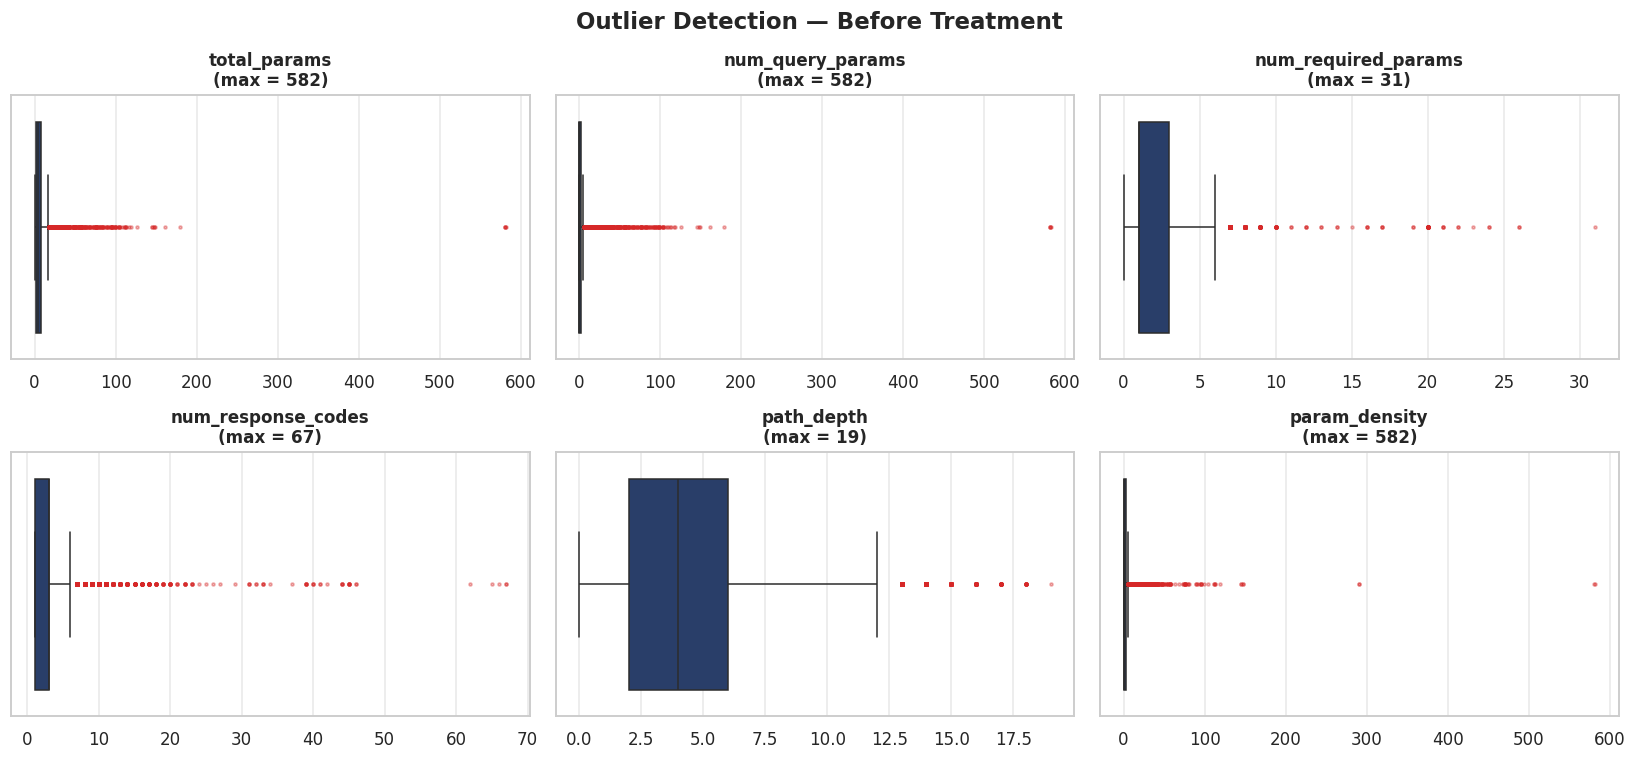

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))

for ax, col in zip(axes.ravel(), outlier_cols):
    sns.boxplot(x=df[col], ax=ax, color=NAVY, fliersize=2,
                flierprops={"markerfacecolor": RED, "markeredgecolor": RED,
                            "alpha": 0.35})
    ax.set_title(f"{col}\n(max = {df[col].max():,.0f})", fontsize=11)
    ax.set_xlabel("")

fig.suptitle("Outlier Detection — Before Treatment", fontsize=15, fontweight="bold")
plt.tight_layout()
save_fig(fig, "02_outliers_before")
plt.show()

In [15]:
df_capped = df.copy()
capped_summary = []

for col in outlier_cols:
    lo, hi = iqr_bounds(df[col])
    lo = max(lo, 0)                       # counts can never be negative
    n_changed = int(((df[col] < lo) | (df[col] > hi)).sum())
    df_capped[col] = df[col].clip(lower=lo, upper=hi)
    capped_summary.append({
        "feature": col,
        "values_capped": n_changed,
        "max_before": df[col].max(),
        "max_after": df_capped[col].max(),
        "mean_before": round(df[col].mean(), 2),
        "mean_after": round(df_capped[col].mean(), 2),
    })

df = df_capped
pd.DataFrame(capped_summary)

,feature,values_capped,max_before,max_after,mean_before,mean_after
0,total_params,1251,582.000,17.000,5.270,5.100
1,num_query_params,16987,582.000,5.000,2.540,1.460
2,num_required_params,838,31.000,6.000,1.790,1.770
3,num_response_codes,6775,67.000,6.000,2.940,2.780
4,path_depth,1276,19.000,12.000,4.260,4.240
5,param_density,13381,582.000,5.650,2.190,1.700


saved -> figures/03_outliers_after.png


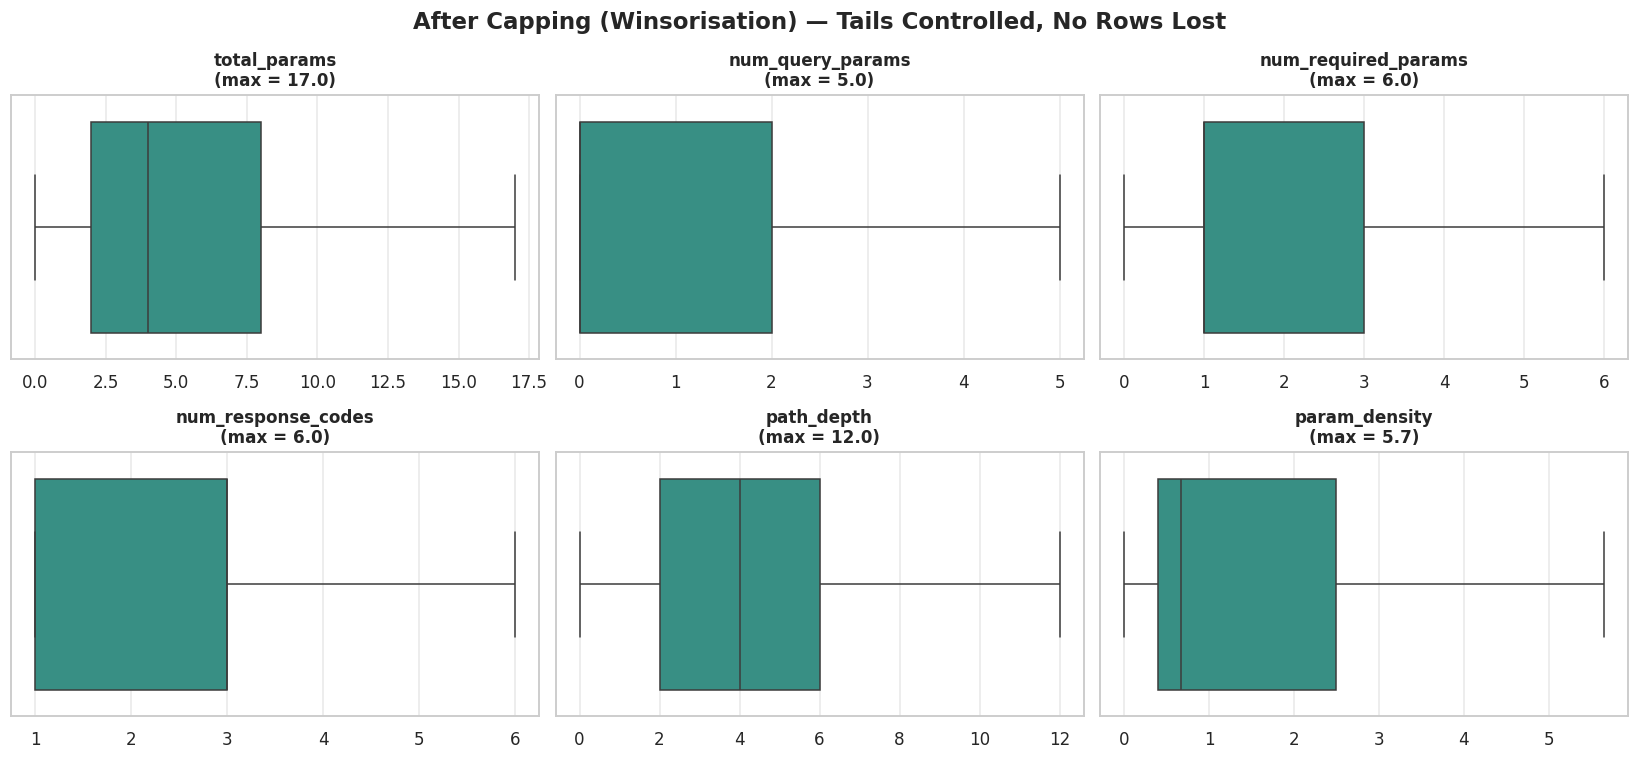

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))

for ax, col in zip(axes.ravel(), outlier_cols):
    sns.boxplot(x=df[col], ax=ax, color=TEAL, fliersize=2)
    ax.set_title(f"{col}\n(max = {df[col].max():,.1f})", fontsize=11)
    ax.set_xlabel("")

fig.suptitle("After Capping (Winsorisation) — Tails Controlled, No Rows Lost",
             fontsize=15, fontweight="bold")
plt.tight_layout()
save_fig(fig, "03_outliers_after")
plt.show()

## 4.5 Creating the Target Variable — `FUZZ_RISK`

The raw specifications carry no label, so we construct one. `FUZZ_RISK` is a
**rule-based composite index** that scores how much attention SentinelAPI should give an
endpoint. It is built the same way established software-metric indices are built: known
risk factors, each given a weight, summed and normalised.

| Risk factor | Why it raises risk | Weight |
|:--|:--|:--:|
| Unvalidated parameter ratio | Inputs with no rules accept anything a fuzzer sends | **2.5** |
| Unconstrained string ratio | Free-text fields carry SQLi / XSS / path-traversal payloads | **2.0** |
| No authentication | The endpoint is reachable by anyone | **2.0** |
| State-changing method | POST/PUT/PATCH/DELETE modify data — failures are destructive | **1.5** |
| No 4xx documented | Error behaviour is undefined, so bad input is unhandled | **1.5** |
| Accepts a request body | A larger, more complex payload to attack | **1.0** |
| High parameter load | More inputs means more combinations to break | **1.0** |

Total possible weight = **11.5**, rescaled to a **0–100** score, then banded:

* **Low** — score < 35
* **Medium** — 35 ≤ score < 60
* **High** — score ≥ 60

> **Note on interpretation.** `FUZZ_RISK` is a *derived index*, not an observed outcome.
> It summarises the specification's own weaknesses, so relationships between the score
> and its input features are descriptive by construction. Its value is as a
> **prioritisation metric**: it tells SentinelAPI which of 154,000 endpoints to fuzz
> first. It is not a prediction of confirmed vulnerabilities.

In [17]:
W = {
    "unvalidated":     2.5,
    "unconstr_string": 2.0,
    "no_auth":         2.0,
    "state_changing":  1.5,
    "no_4xx":          1.5,
    "request_body":    1.0,
    "param_load":      1.0,
}
MAX_SCORE = sum(W.values())

# parameter load is normalised against the 90th percentile so it saturates sensibly
p90 = df["total_params"].quantile(0.90)
param_load = (df["total_params"] / p90).clip(0, 1)

raw_score = (
    W["unvalidated"]     * df["unvalidated_ratio"]
  + W["unconstr_string"] * df["unconstrained_string_ratio"]
  + W["no_auth"]         * (1 - df["requires_auth"])
  + W["state_changing"]  * df["is_state_changing"]
  + W["no_4xx"]          * (df["num_4xx_responses"] == 0).astype(int)
  + W["request_body"]    * df["has_request_body"]
  + W["param_load"]      * param_load
)

df["fuzz_risk_score"] = (raw_score / MAX_SCORE * 100).round(2)

df["FUZZ_RISK"] = pd.cut(
    df["fuzz_risk_score"],
    bins=[-0.01, 35, 60, 100],
    labels=["Low", "Medium", "High"],
)
df["IS_HIGH_RISK"] = (df["FUZZ_RISK"] == "High").astype(int)

print("Risk score summary")
print(df["fuzz_risk_score"].describe().round(2).to_string())

print("\nClass distribution")
dist = df["FUZZ_RISK"].value_counts().reindex(["Low", "Medium", "High"])
for lvl, n in dist.items():
    print(f"  {lvl:<7} {n:>8,}  ({n/len(df)*100:5.2f}%)")

Risk score summary
count   103,379.000
mean         53.410
std          19.330
min           0.000
25%          39.860
50%          54.890
75%          70.290
max          96.810

Class distribution
  Low       18,532  (17.93%)
  Medium    42,218  (40.84%)
  High      42,629  (41.24%)


saved -> figures/04_target_variable.png


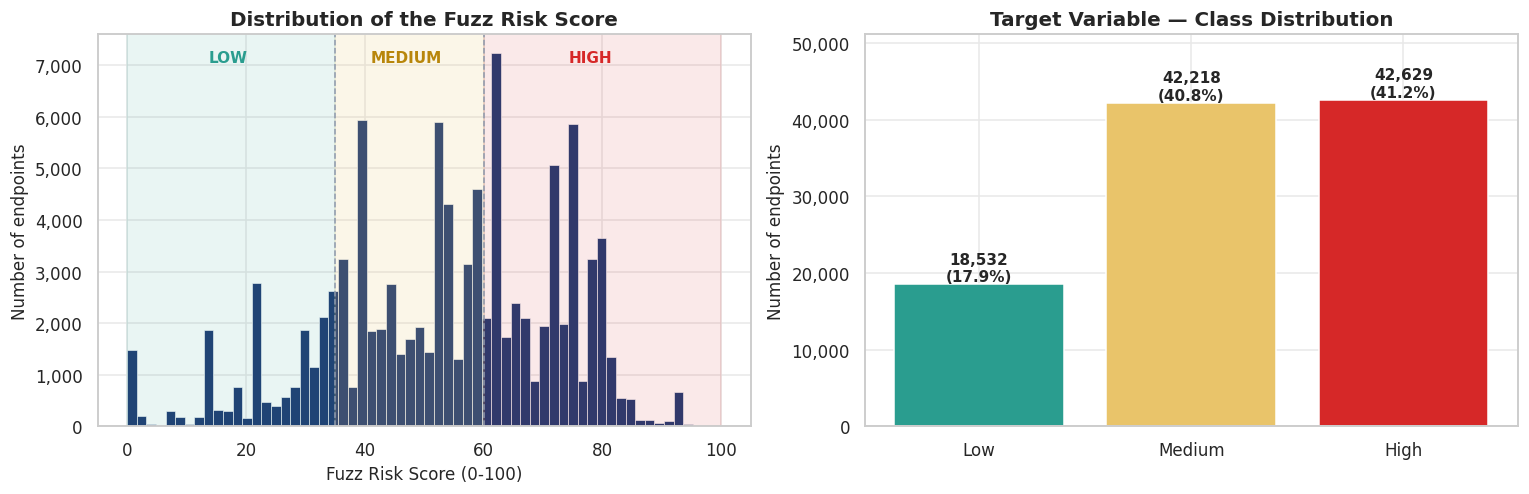

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

# distribution of the continuous score, shaded by band
axes[0].hist(df["fuzz_risk_score"], bins=60, color=NAVY, edgecolor="white", linewidth=.4)
axes[0].axvspan(0, 35, color=TEAL, alpha=.10)
axes[0].axvspan(35, 60, color=AMBER, alpha=.15)
axes[0].axvspan(60, 100, color=RED, alpha=.10)
axes[0].axvline(35, color=GREY, ls="--", lw=1)
axes[0].axvline(60, color=GREY, ls="--", lw=1)
axes[0].text(17, axes[0].get_ylim()[1]*.93, "LOW", ha="center", color=TEAL, fontweight="bold")
axes[0].text(47, axes[0].get_ylim()[1]*.93, "MEDIUM", ha="center", color="#b8860b", fontweight="bold")
axes[0].text(78, axes[0].get_ylim()[1]*.93, "HIGH", ha="center", color=RED, fontweight="bold")
axes[0].set_xlabel("Fuzz Risk Score (0-100)")
axes[0].set_ylabel("Number of endpoints")
axes[0].set_title("Distribution of the Fuzz Risk Score")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:,.0f}"))

# class balance
order = ["Low", "Medium", "High"]
counts = df["FUZZ_RISK"].value_counts().reindex(order)
bars = axes[1].bar(order, counts.values, color=[RISK_COLORS[o] for o in order],
                   edgecolor="white")
for b, v in zip(bars, counts.values):
    axes[1].text(b.get_x()+b.get_width()/2, v, f"{v:,}\n({v/len(df)*100:.1f}%)",
                 ha="center", va="bottom", fontweight="bold", fontsize=10)
axes[1].set_ylabel("Number of endpoints")
axes[1].set_title("Target Variable — Class Distribution")
axes[1].set_ylim(0, counts.max()*1.20)
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:,.0f}"))

plt.tight_layout()
save_fig(fig, "04_target_variable")
plt.show()

## 4.6 Encoding Categorical Variables

Machine-learning models need numbers, not text. Two techniques are applied:

* **Label / ordinal encoding** for `FUZZ_RISK`, because Low < Medium < High has a real
  order.
* **One-hot encoding** for `http_method`, because GET and POST have no natural ordering
  — treating them as 1 and 2 would invent a relationship that does not exist.

`api_provider` (685 values) and `path` are left as text: one-hot encoding them would
create hundreds of near-empty columns. They are identifiers, not features.

In [19]:
df_enc = df.copy()

# --- ordinal encoding (order matters) --------------------------------------
risk_map = {"Low": 0, "Medium": 1, "High": 2}
df_enc["FUZZ_RISK_ENCODED"] = df_enc["FUZZ_RISK"].map(risk_map).astype(int)

# --- one-hot encoding (no order) -------------------------------------------
method_dummies = pd.get_dummies(df_enc["http_method"], prefix="method").astype(int)
spec_dummies   = pd.get_dummies(df_enc["spec_version"], prefix="spec").astype(int)

df_enc = pd.concat([df_enc, method_dummies, spec_dummies], axis=1)

print(f"Ordinal encoding : FUZZ_RISK -> {risk_map}")
print(f"One-hot encoding : {len(method_dummies.columns)} method columns, "
      f"{len(spec_dummies.columns)} spec columns")
print(f"Columns: {df.shape[1]} -> {df_enc.shape[1]}\n")

df_enc[["http_method"] + list(method_dummies.columns) +
       ["FUZZ_RISK", "FUZZ_RISK_ENCODED"]].head(8)

Ordinal encoding : FUZZ_RISK -> {'Low': 0, 'Medium': 1, 'High': 2}
One-hot encoding : 8 method columns, 2 spec columns
Columns: 48 -> 59



,http_method,method_DELETE,method_GET,method_HEAD,method_OPTIONS,method_PATCH,method_POST,method_PUT,method_TRACE,FUZZ_RISK,FUZZ_RISK_ENCODED
0,GET,0,1,0,0,0,0,0,0,Low,0
1,GET,0,1,0,0,0,0,0,0,Low,0
2,GET,0,1,0,0,0,0,0,0,Low,0
3,POST,0,0,0,0,0,1,0,0,Low,0
4,POST,0,0,0,0,0,1,0,0,Low,0
5,POST,0,0,0,0,0,1,0,0,Low,0
6,GET,0,1,0,0,0,0,0,0,Low,0
7,GET,0,1,0,0,0,0,0,0,Low,0


## 4.7 Feature Scaling

The numeric features live on completely different ranges — `path_depth` runs 1–8 while
`fuzz_risk_score` runs 0–100. Distance-based algorithms would let the large-range
features dominate. **Min-Max normalisation** rescales everything to `[0, 1]`:

$$x_{scaled} = \frac{x - x_{min}}{x_{max} - x_{min}}$$

In [20]:
scale_cols = [
    "path_depth", "path_length_chars", "num_path_params", "num_query_params",
    "num_header_params", "total_params", "num_required_params",
    "num_constrained_params", "num_unconstrained_params", "num_string_params",
    "num_unconstrained_string_params", "num_enum_params", "num_pattern_params",
    "num_response_codes", "num_2xx_responses", "num_4xx_responses",
    "num_5xx_responses", "num_security_schemes", "param_density",
]

df_scaled = df_enc.copy()
for col in scale_cols:
    lo, hi = df_scaled[col].min(), df_scaled[col].max()
    df_scaled[col] = 0.0 if hi == lo else (df_scaled[col] - lo) / (hi - lo)

comparison = pd.DataFrame({
    "min_before":  df_enc[scale_cols].min(),
    "max_before":  df_enc[scale_cols].max(),
    "mean_before": df_enc[scale_cols].mean().round(3),
    "min_after":   df_scaled[scale_cols].min().round(3),
    "max_after":   df_scaled[scale_cols].max().round(3),
    "mean_after":  df_scaled[scale_cols].mean().round(3),
})
print(f"{len(scale_cols)} numeric features normalised to the range [0, 1].\n")
comparison

19 numeric features normalised to the range [0, 1].



,min_before,max_before,mean_before,min_after,max_after,mean_after
path_depth,0.000,12.000,4.241,0.000,1.000,0.353
path_length_chars,1.000,295.000,54.715,0.000,1.000,0.183
num_path_params,0.000,9.000,1.284,0.000,1.000,0.143
num_query_params,0.000,5.000,1.463,0.000,1.000,0.293
num_header_params,0.000,39.000,1.368,0.000,1.000,0.035
total_params,0.000,17.000,5.100,0.000,1.000,0.300
num_required_params,0.000,6.000,1.772,0.000,1.000,0.295
num_constrained_params,0.000,201.000,1.153,0.000,1.000,0.006
num_unconstrained_params,0.000,381.000,4.117,0.000,1.000,0.011
num_string_params,0.000,574.000,4.364,0.000,1.000,0.008


saved -> figures/05_scaling_effect.png


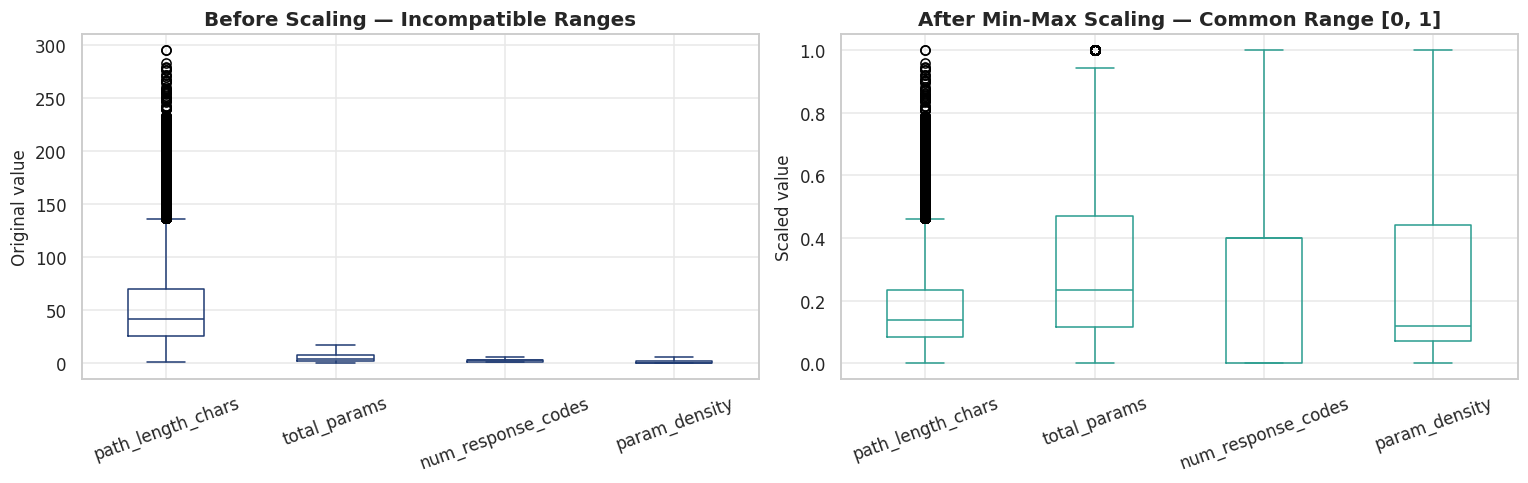

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
show = ["path_length_chars", "total_params", "num_response_codes", "param_density"]

df_enc[show].plot(kind="box", ax=axes[0], color=NAVY, patch_artist=False)
axes[0].set_title("Before Scaling — Incompatible Ranges")
axes[0].set_ylabel("Original value")
axes[0].tick_params(axis="x", rotation=20)

df_scaled[show].plot(kind="box", ax=axes[1], color=TEAL, patch_artist=False)
axes[1].set_title("After Min-Max Scaling — Common Range [0, 1]")
axes[1].set_ylabel("Scaled value")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
save_fig(fig, "05_scaling_effect")
plt.show()

## 4.8 Saving the Cleaned Datasets

Two files are exported:

* **`cleaned_api_endpoints.csv`** — **the main deliverable.** Real units, human-readable,
  103,379 rows x 48 columns. This is the file every chart below is drawn from, and the one
  to hand to the rest of the team for the next stage of the project.
* `cleaned_api_endpoints.zip` — the identical file, zipped. **Share this one** — it is
  ~1.5 MB instead of 25 MB and unzips to a normal CSV on any machine.
* `cleaned_api_endpoints.csv.gz` — the same data again, gzipped, read by this notebook
* `model_ready_api_endpoints.csv.gz` — encoded and scaled, ready for machine learning

They are saved as gzipped CSV (`.csv.gz`). `pandas.read_csv()` opens these directly with
no extra step, and the compression keeps the folder small.

In [22]:
os.makedirs("data", exist_ok=True)

# three copies of the same cleaned data:
#   .csv      plain, for anyone who wants to open it directly
#   .zip      the same plain CSV zipped - this is the one to share with the team
#   .csv.gz   used by this notebook, keeps the folder small
df.to_csv("data/cleaned_api_endpoints.csv", index=False, float_format="%.4f")
df.to_csv("data/cleaned_api_endpoints.csv.gz", index=False, float_format="%.4f")
df.to_csv("data/cleaned_api_endpoints.zip", index=False, float_format="%.4f",
          compression={"method": "zip",
                       "archive_name": "cleaned_api_endpoints.csv"})

model_cols = (
    scale_cols
    + ["has_description", "is_deprecated", "is_state_changing", "has_request_body",
       "body_required", "has_default_response", "requires_auth", "has_params",
       "validation_coverage", "unvalidated_ratio", "required_ratio", "string_ratio",
       "unconstrained_string_ratio", "error_documentation", "has_no_error_spec"]
    + list(method_dummies.columns) + list(spec_dummies.columns)
    + ["fuzz_risk_score", "FUZZ_RISK_ENCODED", "IS_HIGH_RISK"]
)
# round the scaled floats - 5 significant figures is far more precision than any
# model needs, and it keeps the exported file compact
df_scaled[model_cols].to_csv("data/model_ready_api_endpoints.csv.gz",
                             index=False, float_format="%.5g")

print("Files written:")
for f in ["data/raw_api_endpoints.csv.gz",
          "data/cleaned_api_endpoints.csv",
          "data/cleaned_api_endpoints.zip",
          "data/cleaned_api_endpoints.csv.gz",
          "data/model_ready_api_endpoints.csv.gz"]:
    print(f"  {f:<45} {os.path.getsize(f)/1024**2:7.2f} MB")

print(f"\nPreprocessing complete.")
print(f"  Analysis dataset  : {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"  Model-ready set   : {df_scaled[model_cols].shape[0]:,} rows x "
      f"{len(model_cols)} columns")

Files written:
  data/raw_api_endpoints.csv.gz                    1.56 MB
  data/cleaned_api_endpoints.csv                  24.86 MB
  data/cleaned_api_endpoints.zip                   1.56 MB
  data/cleaned_api_endpoints.csv.gz                1.46 MB
  data/model_ready_api_endpoints.csv.gz            0.87 MB

Preprocessing complete.
  Analysis dataset  : 103,379 rows x 48 columns
  Model-ready set   : 103,379 rows x 47 columns


### Preprocessing summary

| Step | Action taken | Result |
|:--|:--|:--|
| Missing values | Imputed 2 metadata columns with explicit markers | 0 missing, 0 rows lost |
| Duplicates | Dropped repeats of provider + path + method | unique endpoints only |
| Outliers | IQR detection, then capping (not deletion) | tails controlled, all rows kept |
| Feature engineering | 9 ratio and flag features derived | size-independent comparisons |
| Target variable | Weighted `FUZZ_RISK` index, 3 bands | analysable label created |
| Encoding | Ordinal for risk, one-hot for method and spec | fully numeric |
| Scaling | Min-Max to [0, 1] | comparable feature ranges |

---

# 5. Exploratory Data Analysis

Now that the data is clean, we explore it. Each subsection asks a question that matters
to SentinelAPI and answers it with evidence.

## 5.1 What does the dataset look like overall?

In [23]:
summary = pd.DataFrame({
    "Metric": [
        "API endpoints analysed", "Distinct API providers", "Business categories",
        "OpenAPI 3.x endpoints", "Swagger 2.0 endpoints",
        "Endpoints that change data", "Endpoints requiring authentication",
        "Endpoints accepting a request body", "Median parameters per endpoint",
        "Mean validation coverage (endpoints with params)",
        "Endpoints with zero validated parameters",
        "Endpoints with no 4xx documented",
    ],
    "Value": [
        f"{len(df):,}",
        f"{df['api_provider'].nunique():,}",
        f"{df['category'].nunique()}",
        f"{(df['spec_version']=='OpenAPI 3.x').sum():,}",
        f"{(df['spec_version']=='Swagger 2.0').sum():,}",
        f"{df['is_state_changing'].sum():,} ({df['is_state_changing'].mean()*100:.1f}%)",
        f"{df['requires_auth'].sum():,} ({df['requires_auth'].mean()*100:.1f}%)",
        f"{df['has_request_body'].sum():,} ({df['has_request_body'].mean()*100:.1f}%)",
        f"{df['total_params'].median():.0f}",
        f"{df[df['total_params']>0]['validation_coverage'].mean()*100:.1f}%",
        f"{(df['num_constrained_params']==0).sum():,} "
        f"({(df['num_constrained_params']==0).mean()*100:.1f}%)",
        f"{(df['num_4xx_responses']==0).sum():,} "
        f"({(df['num_4xx_responses']==0).mean()*100:.1f}%)",
    ],
})
summary

,Metric,Value
0,API endpoints analysed,"103,379"
1,Distinct API providers,685
2,Business categories,35
3,OpenAPI 3.x endpoints,"83,630"
4,Swagger 2.0 endpoints,"19,749"
5,Endpoints that change data,"54,367 (52.6%)"
6,Endpoints requiring authentication,"58,982 (57.1%)"
7,Endpoints accepting a request body,"39,941 (38.6%)"
8,Median parameters per endpoint,4
9,Mean validation coverage (endpoints with params),21.1%


saved -> figures/06_dataset_overview.png


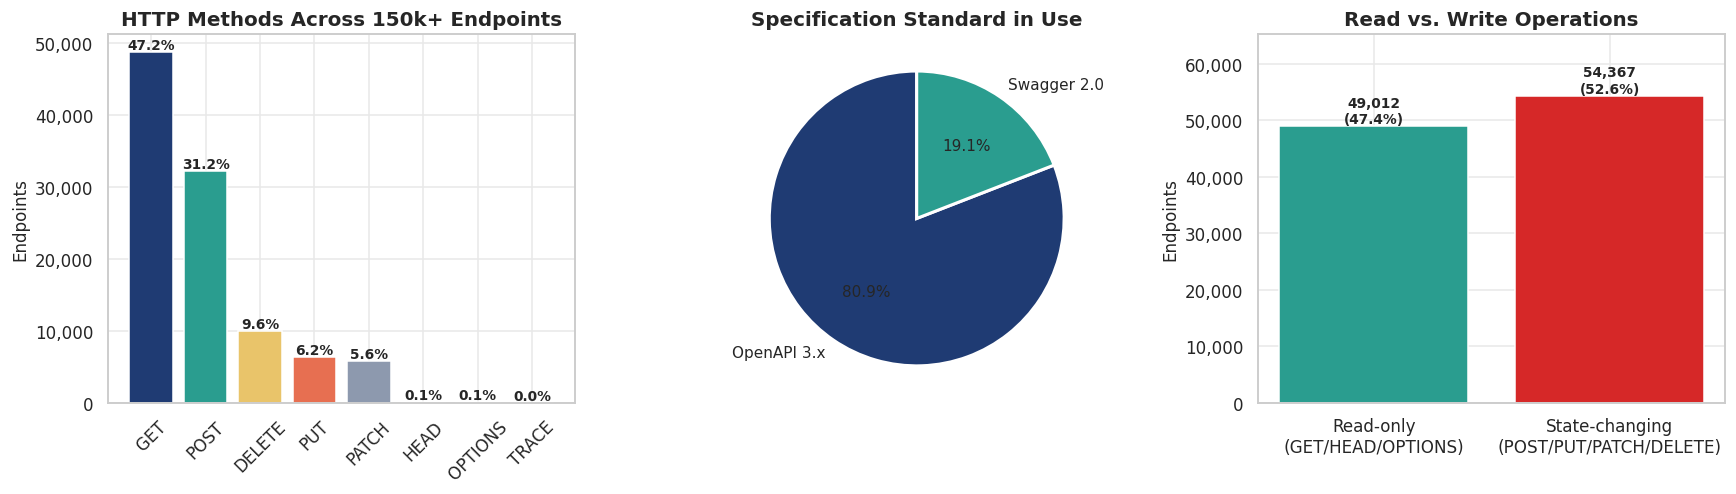

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

# --- HTTP methods ----------------------------------------------------------
mc = df["http_method"].value_counts()
bars = axes[0].bar(mc.index, mc.values, color=SEQ[:len(mc)], edgecolor="white")
for b, v in zip(bars, mc.values):
    axes[0].text(b.get_x()+b.get_width()/2, v, f"{v/len(df)*100:.1f}%",
                 ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[0].set_title("HTTP Methods Across 150k+ Endpoints")
axes[0].set_ylabel("Endpoints")
axes[0].tick_params(axis="x", rotation=45)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:,.0f}"))

# --- spec version ----------------------------------------------------------
sv = df["spec_version"].value_counts()
axes[1].pie(sv.values, labels=sv.index, autopct="%1.1f%%", startangle=90,
            colors=[NAVY, TEAL], wedgeprops={"edgecolor": "white", "linewidth": 2},
            textprops={"fontsize": 10})
axes[1].set_title("Specification Standard in Use")

# --- read vs write ---------------------------------------------------------
rw = pd.Series({
    "Read-only\n(GET/HEAD/OPTIONS)": (~df["is_state_changing"].astype(bool)).sum(),
    "State-changing\n(POST/PUT/PATCH/DELETE)": df["is_state_changing"].sum(),
})
bars = axes[2].bar(rw.index, rw.values, color=[TEAL, RED], edgecolor="white")
for b, v in zip(bars, rw.values):
    axes[2].text(b.get_x()+b.get_width()/2, v, f"{v:,}\n({v/len(df)*100:.1f}%)",
                 ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[2].set_title("Read vs. Write Operations")
axes[2].set_ylabel("Endpoints")
axes[2].set_ylim(0, rw.max()*1.20)
axes[2].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:,.0f}"))

plt.tight_layout()
save_fig(fig, "06_dataset_overview")
plt.show()

## 5.2 Which industries publish these APIs?

saved -> figures/07_categories_providers.png


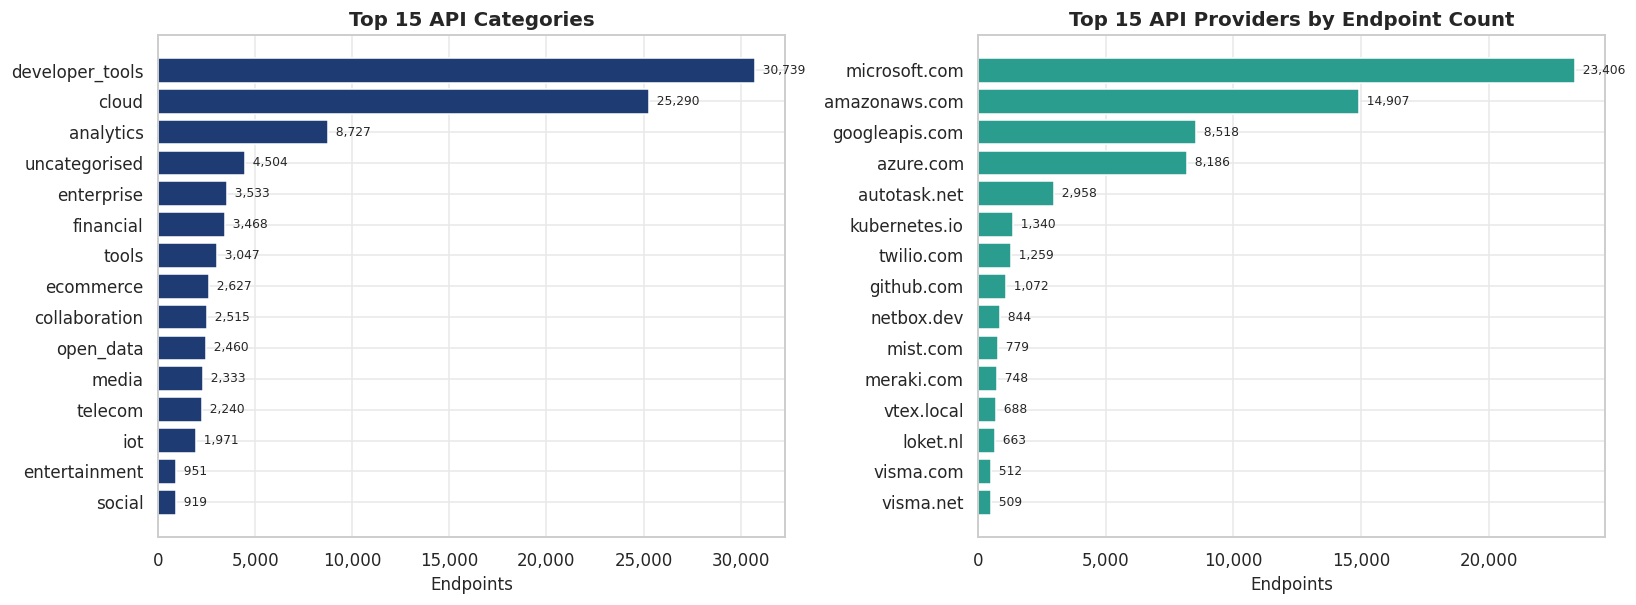

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))

cat = df["category"].value_counts().head(15)
axes[0].barh(cat.index[::-1], cat.values[::-1], color=NAVY)
axes[0].set_xlabel("Endpoints")
axes[0].set_title("Top 15 API Categories")
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:,.0f}"))
for i, v in enumerate(cat.values[::-1]):
    axes[0].text(v, i, f"  {v:,}", va="center", fontsize=8)

prov = df["api_provider"].value_counts().head(15)
axes[1].barh(prov.index[::-1], prov.values[::-1], color=TEAL)
axes[1].set_xlabel("Endpoints")
axes[1].set_title("Top 15 API Providers by Endpoint Count")
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:,.0f}"))
for i, v in enumerate(prov.values[::-1]):
    axes[1].text(v, i, f"  {v:,}", va="center", fontsize=8)

plt.tight_layout()
save_fig(fig, "07_categories_providers")
plt.show()

## 5.3 How large is the input surface of a typical endpoint?

Every parameter is a door a fuzzer can push on. This is the size of the attack surface.

saved -> figures/08_input_surface.png


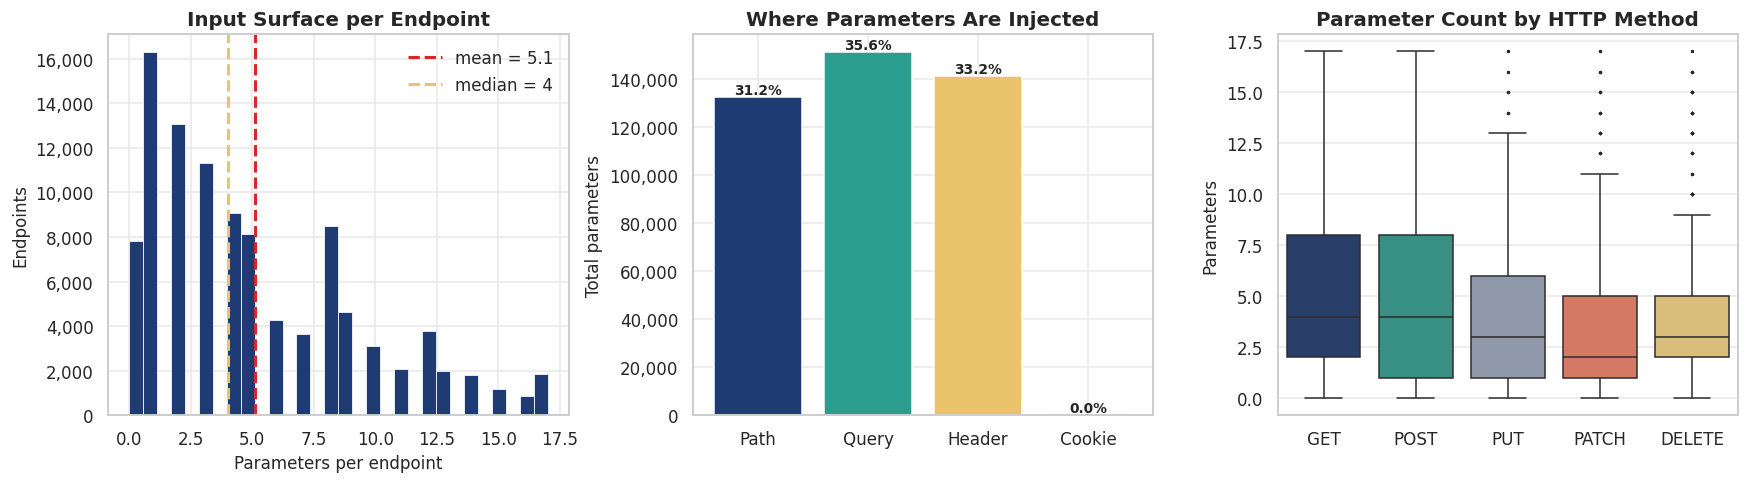

Total input parameters across the dataset: 527,254
Every one of these is a value SentinelAPI can fuzz.


In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].hist(df["total_params"], bins=30, color=NAVY, edgecolor="white", linewidth=.5)
axes[0].axvline(df["total_params"].mean(), color=RED, ls="--", lw=2,
                label=f"mean = {df['total_params'].mean():.1f}")
axes[0].axvline(df["total_params"].median(), color=AMBER, ls="--", lw=2,
                label=f"median = {df['total_params'].median():.0f}")
axes[0].set_xlabel("Parameters per endpoint")
axes[0].set_ylabel("Endpoints")
axes[0].set_title("Input Surface per Endpoint")
axes[0].legend()
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:,.0f}"))

loc = pd.Series({
    "Path": df["num_path_params"].sum(),
    "Query": df["num_query_params"].sum(),
    "Header": df["num_header_params"].sum(),
    "Cookie": df["num_cookie_params"].sum(),
})
bars = axes[1].bar(loc.index, loc.values, color=SEQ[:4], edgecolor="white")
for b, v in zip(bars, loc.values):
    axes[1].text(b.get_x()+b.get_width()/2, v, f"{v/loc.sum()*100:.1f}%",
                 ha="center", va="bottom", fontweight="bold", fontsize=9)
axes[1].set_title("Where Parameters Are Injected")
axes[1].set_ylabel("Total parameters")
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:,.0f}"))

sns.boxplot(data=df, x="http_method", y="total_params",
            order=["GET", "POST", "PUT", "PATCH", "DELETE"],
            hue="http_method", palette=SEQ[:5], legend=False, ax=axes[2], fliersize=1)
axes[2].set_title("Parameter Count by HTTP Method")
axes[2].set_xlabel("")
axes[2].set_ylabel("Parameters")

plt.tight_layout()
save_fig(fig, "08_input_surface")
plt.show()

print(f"Total input parameters across the dataset: {df['total_params'].sum():,}")
print(f"Every one of these is a value SentinelAPI can fuzz.")

## 5.4 The headline finding — how much of that surface is actually validated?

This is the single most important question for the project. A parameter with **no
validation rule** (no `maxLength`, no `pattern`, no `enum`, no numeric bounds) will accept
whatever is sent to it — including an SQL injection or XSS payload.

In [27]:
# endpoints with no parameters have nothing to validate, so they are excluded
# from the coverage average - otherwise they would count as "100% covered"
wp = df[df["total_params"] > 0]

mean_cov      = wp["validation_coverage"].mean() * 100
zero_val      = (wp["num_constrained_params"] == 0).mean() * 100
unval_strings = df["num_unconstrained_string_params"].sum()
total_params  = df["total_params"].sum()
unval_params  = df["num_unconstrained_params"].sum()

print("=" * 68)
print("VALIDATION COVERAGE - KEY RESULT")
print("=" * 68)
print(f"Endpoints that accept at least one parameter : {len(wp):>9,}")
print(f"Total input parameters in the dataset        : {total_params:>9,}")
print(f"Parameters carrying NO validation rule       : {unval_params:>9,} "
      f"({unval_params/total_params*100:.1f}%)")
print(f"Mean validation coverage per endpoint        : {mean_cov:>8.1f}%")
print(f"Endpoints with ZERO validated parameters     : {zero_val:>8.1f}%")
print(f"Unvalidated STRING parameters                : {unval_strings:>9,}")
print("=" * 68)
print("\nEvery unvalidated string parameter is a potential carrier for")
print("SQL Injection, Cross-Site Scripting or Path Traversal — precisely")
print("the vulnerability classes SentinelAPI is built to detect.")

VALIDATION COVERAGE - KEY RESULT
Endpoints that accept at least one parameter :    95,581
Total input parameters in the dataset        :   527,254
Parameters carrying NO validation rule       :   425,643 (80.7%)
Mean validation coverage per endpoint        :     21.1%
Endpoints with ZERO validated parameters     :     47.0%
Unvalidated STRING parameters                :   378,293

Every unvalidated string parameter is a potential carrier for
SQL Injection, Cross-Site Scripting or Path Traversal — precisely
the vulnerability classes SentinelAPI is built to detect.


saved -> figures/09_validation_coverage.png


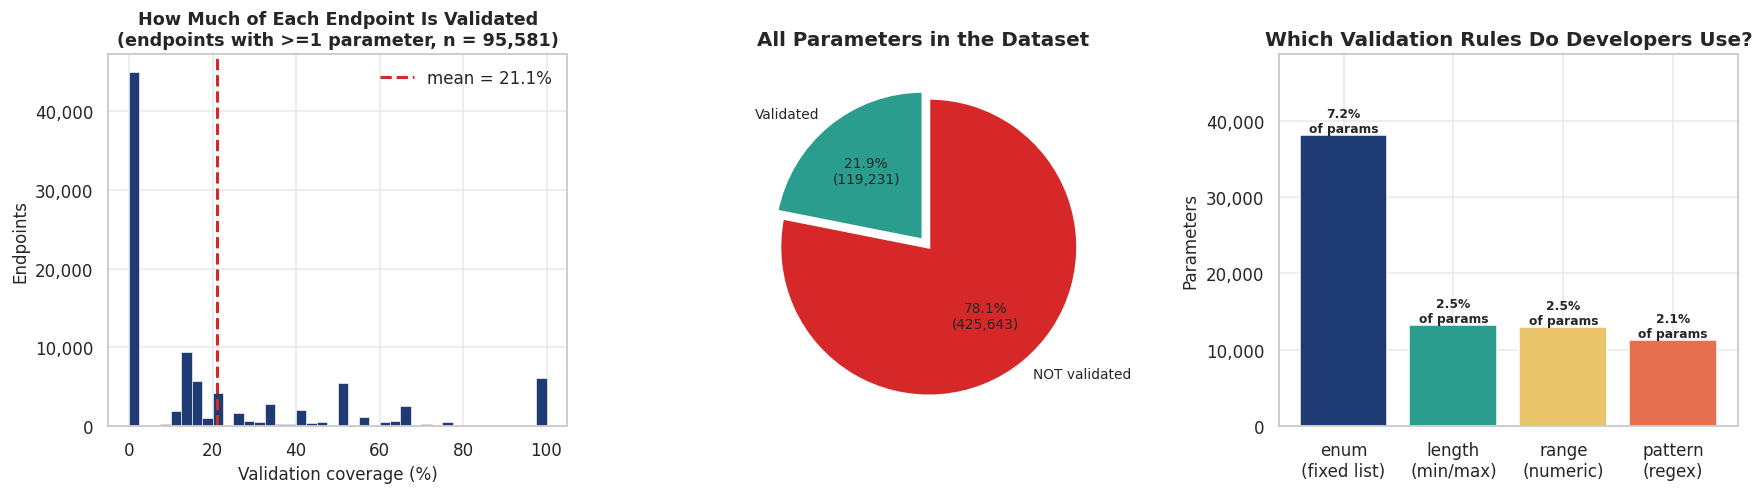

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

# --- distribution of coverage ----------------------------------------------
# only endpoints that actually have parameters; a parameterless endpoint has
# nothing to validate, so including it would inflate the coverage figure
with_params = df[df["total_params"] > 0]
cov_wp = with_params["validation_coverage"].mean() * 100

axes[0].hist(with_params["validation_coverage"]*100, bins=40, color=NAVY,
             edgecolor="white", linewidth=.4)
axes[0].axvline(cov_wp, color=RED, ls="--", lw=2, label=f"mean = {cov_wp:.1f}%")
axes[0].set_xlabel("Validation coverage (%)")
axes[0].set_ylabel("Endpoints")
axes[0].set_title("How Much of Each Endpoint Is Validated\n"
                  f"(endpoints with >=1 parameter, n = {len(with_params):,})",
                  fontsize=11.5)
axes[0].legend()
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:,.0f}"))

# --- validated vs not ------------------------------------------------------
tot_c = df["num_constrained_params"].sum()
tot_u = df["num_unconstrained_params"].sum()
axes[1].pie([tot_c, tot_u],
            labels=["Validated", "NOT validated"],
            autopct=lambda p: f"{p:.1f}%\n({p*(tot_c+tot_u)/100:,.0f})",
            startangle=90, colors=[TEAL, RED],
            explode=(0, 0.06),
            wedgeprops={"edgecolor": "white", "linewidth": 2},
            textprops={"fontsize": 9})
axes[1].set_title("All Parameters in the Dataset")

# --- which rules are used --------------------------------------------------
rules = pd.Series({
    "enum\n(fixed list)":     df["num_enum_params"].sum(),
    "pattern\n(regex)":       df["num_pattern_params"].sum(),
    "length\n(min/max)":      df["num_length_bounded_params"].sum(),
    "range\n(numeric)":       df["num_numeric_range_params"].sum(),
}).sort_values(ascending=False)
total_p = df["total_params"].sum()
bars = axes[2].bar(rules.index, rules.values, color=SEQ[:4], edgecolor="white")
for b, v in zip(bars, rules.values):
    axes[2].text(b.get_x()+b.get_width()/2, v, f"{v/total_p*100:.1f}%\nof params",
                 ha="center", va="bottom", fontsize=8, fontweight="bold")
axes[2].set_title("Which Validation Rules Do Developers Use?")
axes[2].set_ylabel("Parameters")
axes[2].set_ylim(0, rules.max()*1.28)
axes[2].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:,.0f}"))

plt.tight_layout()
save_fig(fig, "09_validation_coverage")
plt.show()

## 5.5 Is authentication enforced, and are errors documented?

Two more weaknesses SentinelAPI exploits: endpoints anyone can reach, and endpoints whose
failure behaviour was never specified.

saved -> figures/10_auth_and_errors.png


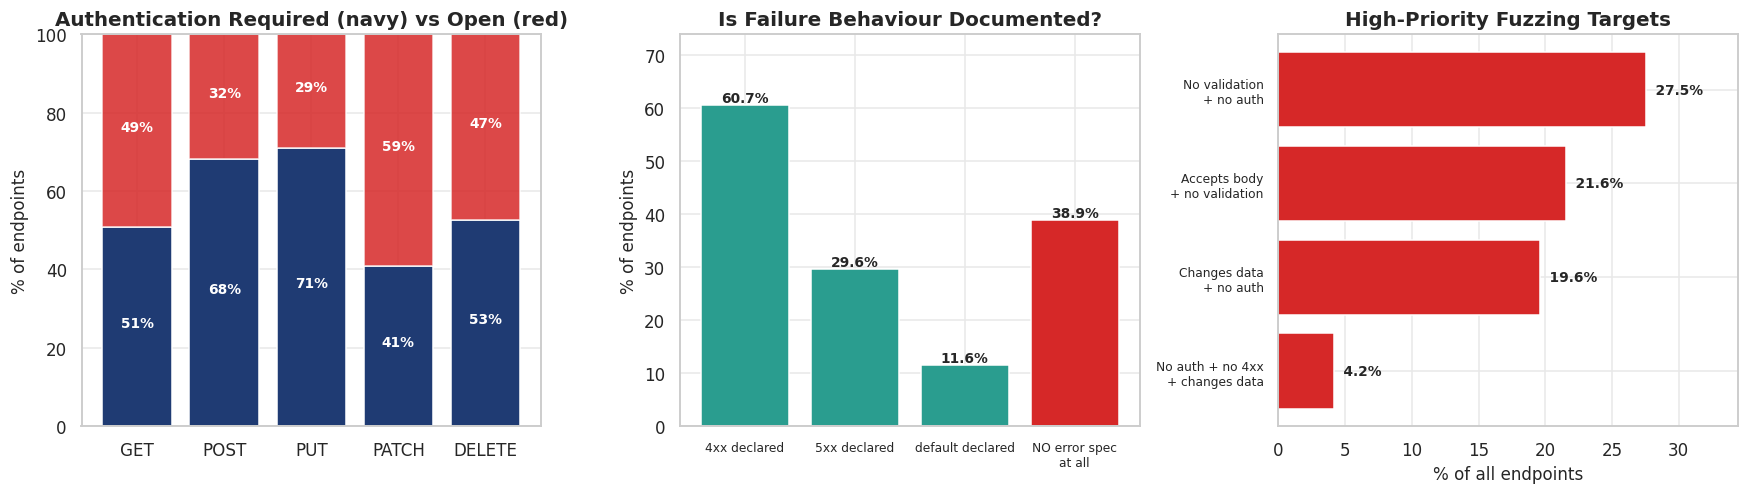

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

# --- auth by method --------------------------------------------------------
order = ["GET", "POST", "PUT", "PATCH", "DELETE"]
auth = (df[df["http_method"].isin(order)]
        .groupby("http_method", observed=True)["requires_auth"]
        .mean().reindex(order) * 100)
bars = axes[0].bar(auth.index, auth.values, color=NAVY, edgecolor="white")
axes[0].bar(auth.index, 100-auth.values, bottom=auth.values, color=RED,
            edgecolor="white", alpha=.85)
for b, v in zip(bars, auth.values):
    axes[0].text(b.get_x()+b.get_width()/2, v/2, f"{v:.0f}%",
                 ha="center", color="white", fontweight="bold", fontsize=9)
    axes[0].text(b.get_x()+b.get_width()/2, v+(100-v)/2, f"{100-v:.0f}%",
                 ha="center", color="white", fontweight="bold", fontsize=9)
axes[0].set_ylabel("% of endpoints")
axes[0].set_title("Authentication Required (navy) vs Open (red)")
axes[0].set_ylim(0, 100)

# --- error documentation ---------------------------------------------------
err = pd.Series({
    "4xx declared":     (df["num_4xx_responses"] > 0).mean()*100,
    "5xx declared":     (df["num_5xx_responses"] > 0).mean()*100,
    "default declared": (df["has_default_response"] > 0).mean()*100,
    "NO error spec\nat all": df["has_no_error_spec"].mean()*100,
})
colors = [TEAL, TEAL, TEAL, RED]
bars = axes[1].bar(err.index, err.values, color=colors, edgecolor="white")
for b, v in zip(bars, err.values):
    axes[1].text(b.get_x()+b.get_width()/2, v, f"{v:.1f}%",
                 ha="center", va="bottom", fontweight="bold", fontsize=9)
axes[1].set_ylabel("% of endpoints")
axes[1].set_title("Is Failure Behaviour Documented?")
axes[1].set_ylim(0, max(err.values)*1.22)
axes[1].tick_params(axis="x", labelsize=8)

# --- the dangerous combination ---------------------------------------------
danger = pd.Series({
    "Changes data\n+ no auth":
        ((df["is_state_changing"]==1) & (df["requires_auth"]==0)).mean()*100,
    "No validation\n+ no auth":
        ((df["num_constrained_params"]==0) & (df["requires_auth"]==0)).mean()*100,
    "Accepts body\n+ no validation":
        ((df["has_request_body"]==1) & (df["num_constrained_params"]==0)).mean()*100,
    "No auth + no 4xx\n+ changes data":
        ((df["requires_auth"]==0) & (df["num_4xx_responses"]==0) &
         (df["is_state_changing"]==1)).mean()*100,
}).sort_values(ascending=True)
bars = axes[2].barh(danger.index, danger.values, color=RED)
for i, v in enumerate(danger.values):
    axes[2].text(v, i, f"  {v:.1f}%", va="center", fontweight="bold", fontsize=9)
axes[2].set_xlabel("% of all endpoints")
axes[2].set_title("High-Priority Fuzzing Targets")
axes[2].set_xlim(0, danger.max()*1.25)
axes[2].tick_params(axis="y", labelsize=8)

plt.tight_layout()
save_fig(fig, "10_auth_and_errors")
plt.show()

## 5.6 How is fuzz risk distributed across methods and industries?

saved -> figures/11_risk_by_method_category.png


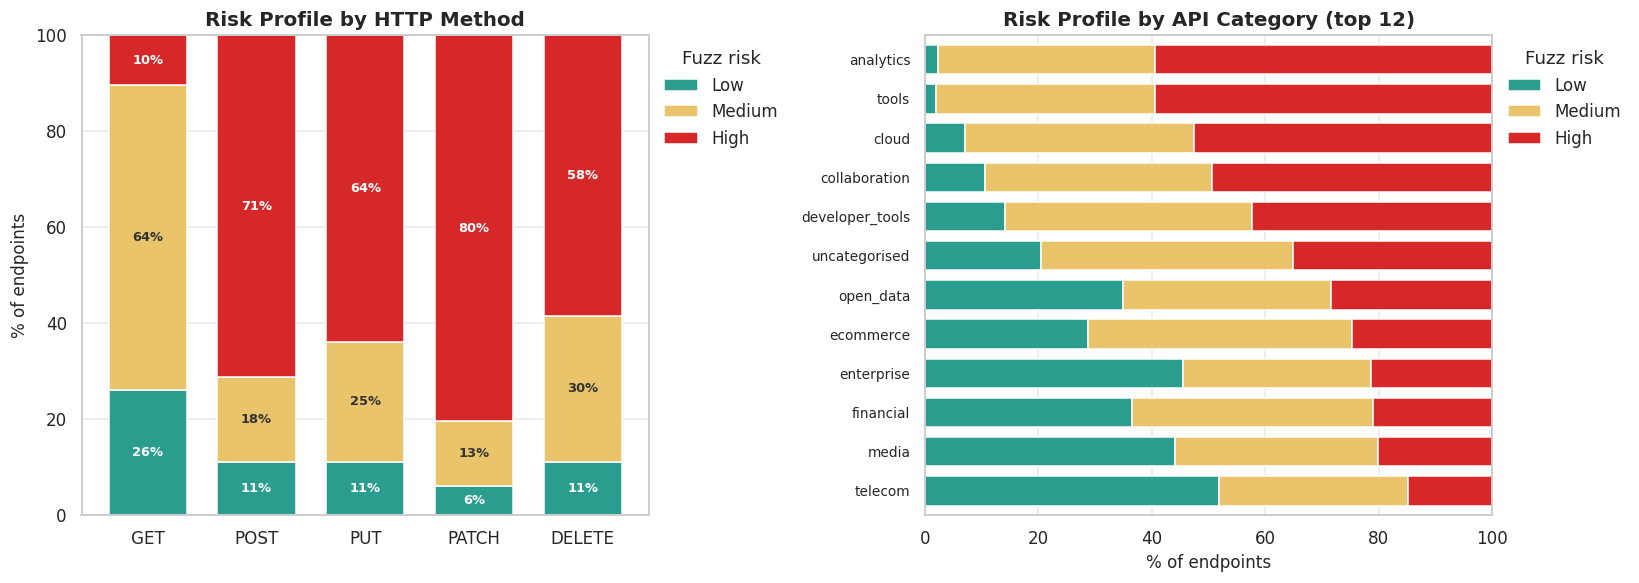

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))

order = ["GET", "POST", "PUT", "PATCH", "DELETE"]
ct = (pd.crosstab(df[df["http_method"].isin(order)]["http_method"],
                  df[df["http_method"].isin(order)]["FUZZ_RISK"],
                  normalize="index").reindex(order) * 100)[["Low", "Medium", "High"]]
ct.plot(kind="bar", stacked=True, ax=axes[0],
        color=[RISK_COLORS[c] for c in ct.columns], edgecolor="white", width=.72)
axes[0].set_ylabel("% of endpoints")
axes[0].set_xlabel("")
axes[0].set_title("Risk Profile by HTTP Method")
axes[0].legend(title="Fuzz risk", bbox_to_anchor=(1.0, 1.0))
axes[0].tick_params(axis="x", rotation=0)
axes[0].set_ylim(0, 100)

# label each segment with its percentage
for i, method in enumerate(ct.index):
    bottom = 0
    for c in ct.columns:
        v = ct.loc[method, c]
        if v > 6:
            axes[0].text(i, bottom + v/2, f"{v:.0f}%", ha="center", va="center",
                         fontsize=8.5, fontweight="bold",
                         color="white" if c != "Medium" else "#333")
        bottom += v

top_cats = df["category"].value_counts().head(12).index
sub = df[df["category"].isin(top_cats)]
cc = (pd.crosstab(sub["category"], sub["FUZZ_RISK"], normalize="index")*100)
cc = cc[["Low", "Medium", "High"]].sort_values("High", ascending=True)
cc.plot(kind="barh", stacked=True, ax=axes[1],
        color=[RISK_COLORS[c] for c in cc.columns], edgecolor="white", width=.75)
axes[1].set_xlabel("% of endpoints")
axes[1].set_ylabel("")
axes[1].set_title("Risk Profile by API Category (top 12)")
axes[1].legend(title="Fuzz risk", bbox_to_anchor=(1.0, 1.0))
axes[1].set_xlim(0, 100)
axes[1].tick_params(axis="y", labelsize=9)

plt.tight_layout()
save_fig(fig, "11_risk_by_method_category")
plt.show()

In [31]:
profile = (df.groupby("FUZZ_RISK", observed=True)
             .agg(endpoints=("path", "size"),
                  mean_params=("total_params", "mean"),
                  mean_validation_cov=("validation_coverage", "mean"),
                  pct_requiring_auth=("requires_auth", "mean"),
                  pct_state_changing=("is_state_changing", "mean"),
                  pct_with_body=("has_request_body", "mean"),
                  pct_no_error_spec=("has_no_error_spec", "mean"))
             .reindex(["Low", "Medium", "High"]))

for c in [c for c in profile.columns if c.startswith("pct_") or c.startswith("mean_valid")]:
    profile[c] = (profile[c]*100).round(1)
profile["mean_params"] = profile["mean_params"].round(2)
profile

,endpoints,mean_params,mean_validation_cov,pct_requiring_auth,pct_state_changing,pct_with_body,pct_no_error_spec
FUZZ_RISK,,,,,,,
Low,18532,2.920,78.800,77.700,31.100,23.000,32.700
Medium,42218,5.640,25.700,56.100,26.200,15.600,39.000
High,42629,5.510,5.900,49.000,88.000,68.300,41.600


The profile table shows a clean separation: as risk rises, validation coverage falls,
authentication drops away, and the share of data-modifying operations climbs. That is
the intended behaviour of the index.

## 5.7 Correlation analysis

Which features move together? This guides feature selection if the dataset is later used
for modelling — strongly correlated pairs carry redundant information.

saved -> figures/12_correlation_matrix.png


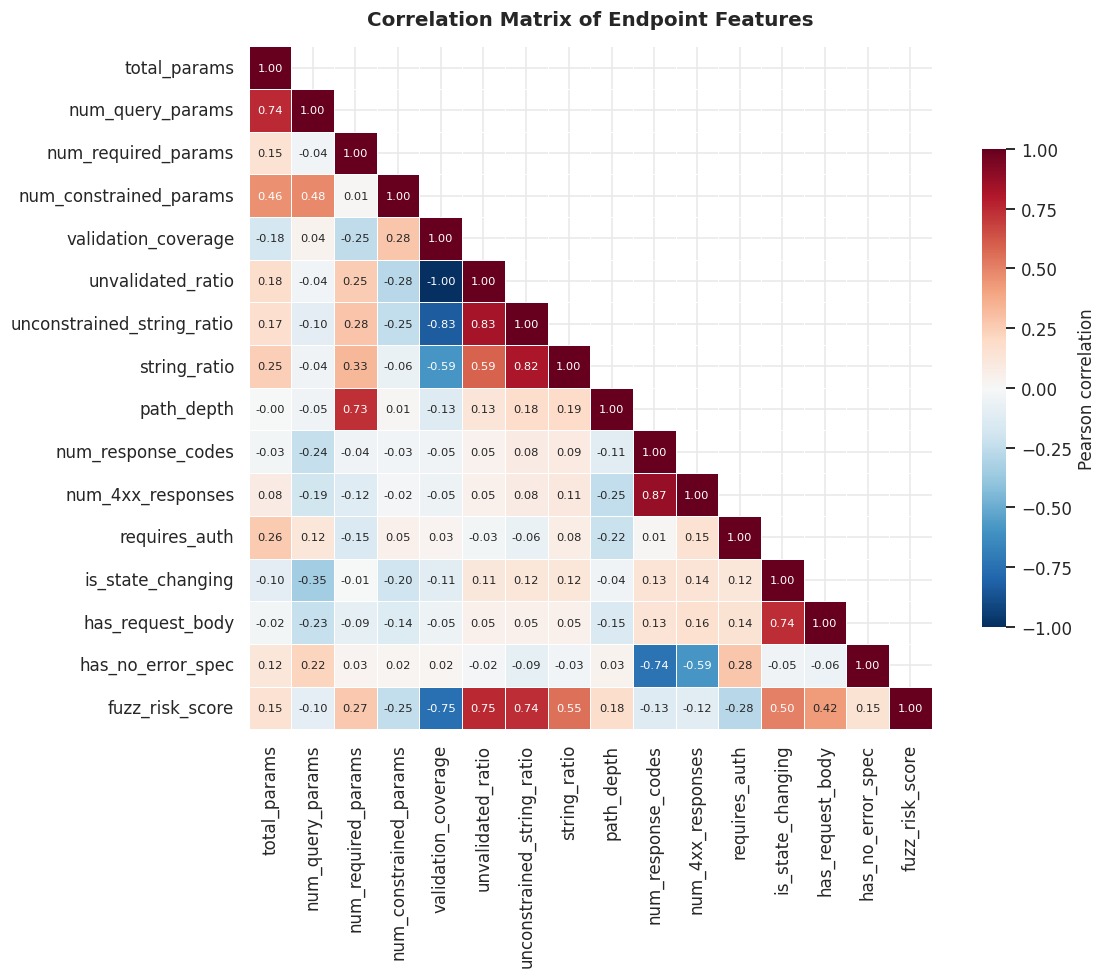

In [32]:
corr_cols = [
    "total_params", "num_query_params", "num_required_params",
    "num_constrained_params", "validation_coverage", "unvalidated_ratio",
    "unconstrained_string_ratio", "string_ratio", "path_depth",
    "num_response_codes", "num_4xx_responses", "requires_auth",
    "is_state_changing", "has_request_body", "has_no_error_spec",
    "fuzz_risk_score",
]
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(11.5, 9))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, linewidths=.6, linecolor="white",
            cbar_kws={"shrink": .7, "label": "Pearson correlation"},
            annot_kws={"size": 7.5}, ax=ax)
ax.set_title("Correlation Matrix of Endpoint Features", pad=14)
plt.tight_layout()
save_fig(fig, "12_correlation_matrix")
plt.show()

In [33]:
pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
             .stack().reset_index())
pairs.columns = ["feature_1", "feature_2", "correlation"]
pairs["abs"] = pairs["correlation"].abs()

print("Strongest relationships in the data\n")
top = pairs.sort_values("abs", ascending=False).head(12).drop(columns="abs")
top.reset_index(drop=True)

Strongest relationships in the data



,feature_1,feature_2,correlation
0,validation_coverage,unvalidated_ratio,-1.000
1,num_response_codes,num_4xx_responses,0.875
2,unvalidated_ratio,unconstrained_string_ratio,0.833
3,validation_coverage,unconstrained_string_ratio,-0.833
4,unconstrained_string_ratio,string_ratio,0.817
5,unvalidated_ratio,fuzz_risk_score,0.751
6,validation_coverage,fuzz_risk_score,-0.751
7,total_params,num_query_params,0.744
8,unconstrained_string_ratio,fuzz_risk_score,0.741
9,is_state_changing,has_request_body,0.741


## 5.8 Relationship between size and validation

saved -> figures/13_size_vs_validation.png


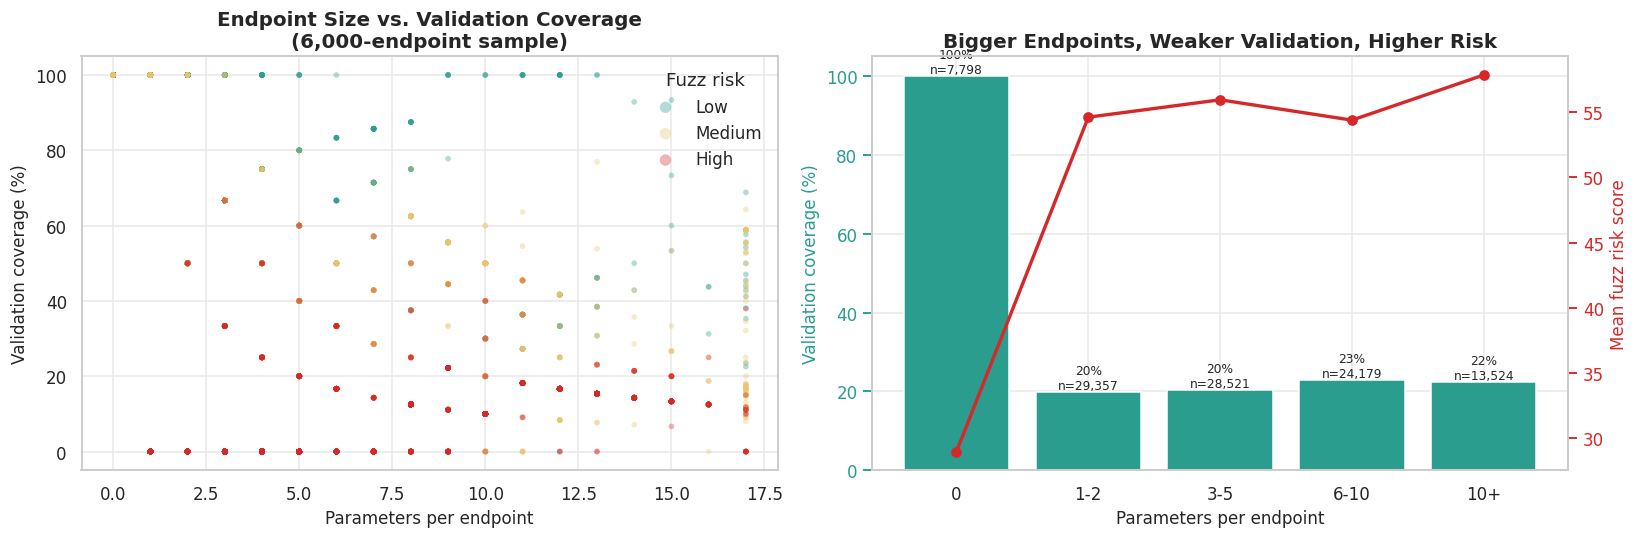

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sample = df.sample(n=min(6000, len(df)), random_state=42)
for lvl in ["Low", "Medium", "High"]:
    s = sample[sample["FUZZ_RISK"] == lvl]
    axes[0].scatter(s["total_params"], s["validation_coverage"]*100,
                    s=14, alpha=.35, color=RISK_COLORS[lvl], label=lvl,
                    edgecolors="none")
axes[0].set_xlabel("Parameters per endpoint")
axes[0].set_ylabel("Validation coverage (%)")
axes[0].set_title("Endpoint Size vs. Validation Coverage\n(6,000-endpoint sample)")
axes[0].legend(title="Fuzz risk", markerscale=2)

binned = df.copy()
binned["param_bin"] = pd.cut(binned["total_params"],
                             bins=[-.1, 0, 2, 5, 10, 100],
                             labels=["0", "1-2", "3-5", "6-10", "10+"])
g = (binned.groupby("param_bin", observed=True)
           .agg(coverage=("validation_coverage", "mean"),
                risk=("fuzz_risk_score", "mean"),
                n=("path", "size")))
ax2 = axes[1]
bars = ax2.bar(g.index.astype(str), g["coverage"]*100, color=TEAL,
               edgecolor="white", label="Validation coverage (%)")
for b, v, n in zip(bars, g["coverage"]*100, g["n"]):
    ax2.text(b.get_x()+b.get_width()/2, v, f"{v:.0f}%\nn={n:,}",
             ha="center", va="bottom", fontsize=8)
ax2b = ax2.twinx()
ax2b.plot(g.index.astype(str), g["risk"], color=RED, marker="o", lw=2.2,
          label="Mean fuzz risk score")
ax2b.set_ylabel("Mean fuzz risk score", color=RED)
ax2b.tick_params(axis="y", colors=RED)
ax2b.grid(False)
ax2.set_xlabel("Parameters per endpoint")
ax2.set_ylabel("Validation coverage (%)", color=TEAL)
ax2.tick_params(axis="y", colors=TEAL)
ax2.set_ylim(0, 105)
ax2.set_title("Bigger Endpoints, Weaker Validation, Higher Risk")

plt.tight_layout()
save_fig(fig, "13_size_vs_validation")
plt.show()

## 5.9 Which API providers should SentinelAPI test first?

In [35]:
prov = (df.groupby("api_provider")
          .agg(endpoints=("path", "size"),
               mean_risk=("fuzz_risk_score", "mean"),
               pct_high_risk=("IS_HIGH_RISK", "mean"),
               validation_cov=("validation_coverage", "mean"),
               pct_auth=("requires_auth", "mean"))
          .query("endpoints >= 50")
          .sort_values("mean_risk", ascending=False))

prov["pct_high_risk"]  = (prov["pct_high_risk"]*100).round(1)
prov["validation_cov"] = (prov["validation_cov"]*100).round(1)
prov["pct_auth"]       = (prov["pct_auth"]*100).round(1)
prov["mean_risk"]      = prov["mean_risk"].round(2)

print("Providers with at least 50 endpoints, ranked by mean fuzz risk\n")
prov.head(15)

Providers with at least 50 endpoints, ranked by mean fuzz risk



,endpoints,mean_risk,pct_high_risk,validation_cov,pct_auth
api_provider,,,,,
i-cue.solutions,64,81.740,89.100,7.600,0.000
envoice.in,61,78.250,68.900,12.300,0.000
influxdata.com,197,76.290,86.800,6.500,1.500
snyk.io,103,75.350,83.500,15.500,0.000
mandrillapp.com,90,74.640,100.000,0.000,0.000
osisoft.com,413,72.840,84.700,1.900,0.000
crucible.local,79,72.430,91.100,7.800,0.000
clearblade.com,220,72.290,75.900,0.900,0.000
hillbillysoftware.com,58,71.060,100.000,0.000,0.000


saved -> figures/14_top_risk_providers.png


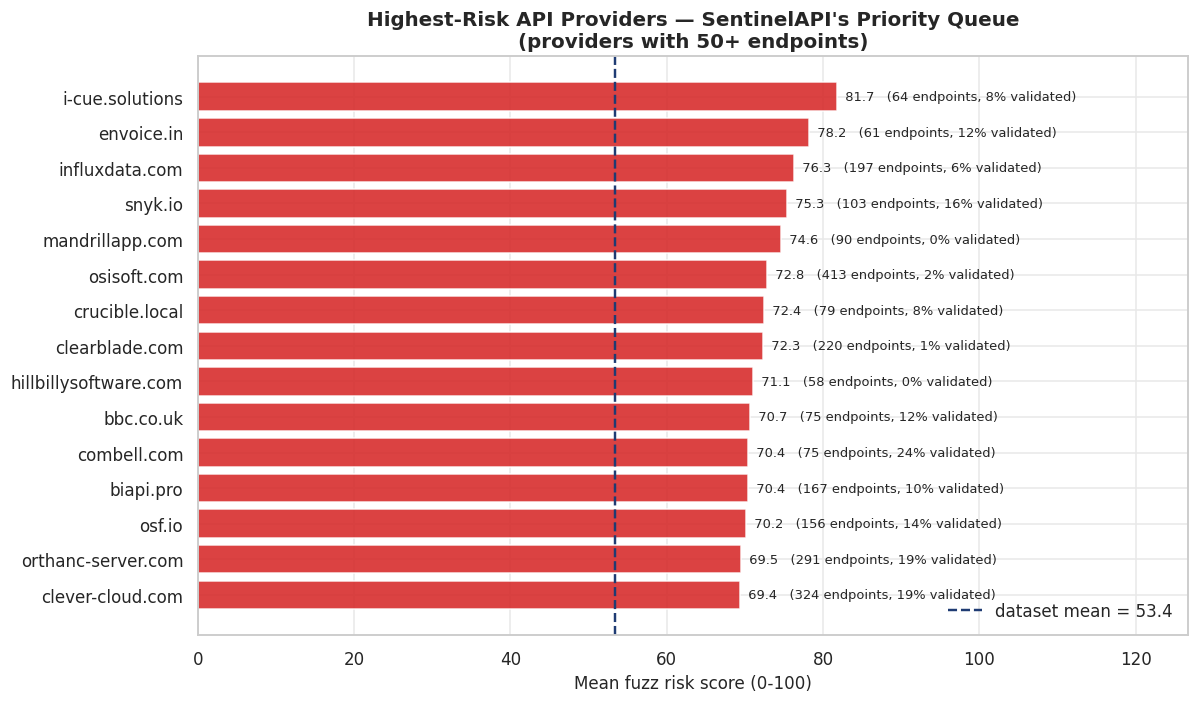

In [36]:
fig, ax = plt.subplots(figsize=(11, 6.5))

top15 = prov.head(15).sort_values("mean_risk")
bars = ax.barh(top15.index, top15["mean_risk"], color=RED, alpha=.88)
for i, (v, n, c) in enumerate(zip(top15["mean_risk"], top15["endpoints"],
                                  top15["validation_cov"])):
    ax.text(v, i, f"  {v:.1f}   ({n:,} endpoints, {c:.0f}% validated)",
            va="center", fontsize=8.5)

ax.axvline(df["fuzz_risk_score"].mean(), color=NAVY, ls="--", lw=1.6,
           label=f"dataset mean = {df['fuzz_risk_score'].mean():.1f}")
ax.set_xlabel("Mean fuzz risk score (0-100)")
ax.set_title("Highest-Risk API Providers — SentinelAPI's Priority Queue\n"
             "(providers with 50+ endpoints)")
ax.set_xlim(0, top15["mean_risk"].max()*1.55)
ax.legend(loc="lower right")

plt.tight_layout()
save_fig(fig, "14_top_risk_providers")
plt.show()

# 6. Correlation Analysis

Section 5.7 gave a first look. This section goes deeper: linear **and** rank correlation,
correlation against the target, hierarchical clustering of the correlation structure, and
a formal multicollinearity check.

## 6.1 Full Pearson correlation matrix

Pearson measures **linear** association between two variables, from −1 (perfect inverse)
through 0 (none) to +1 (perfect direct).

saved -> figures/16_correlation_full_pearson.png


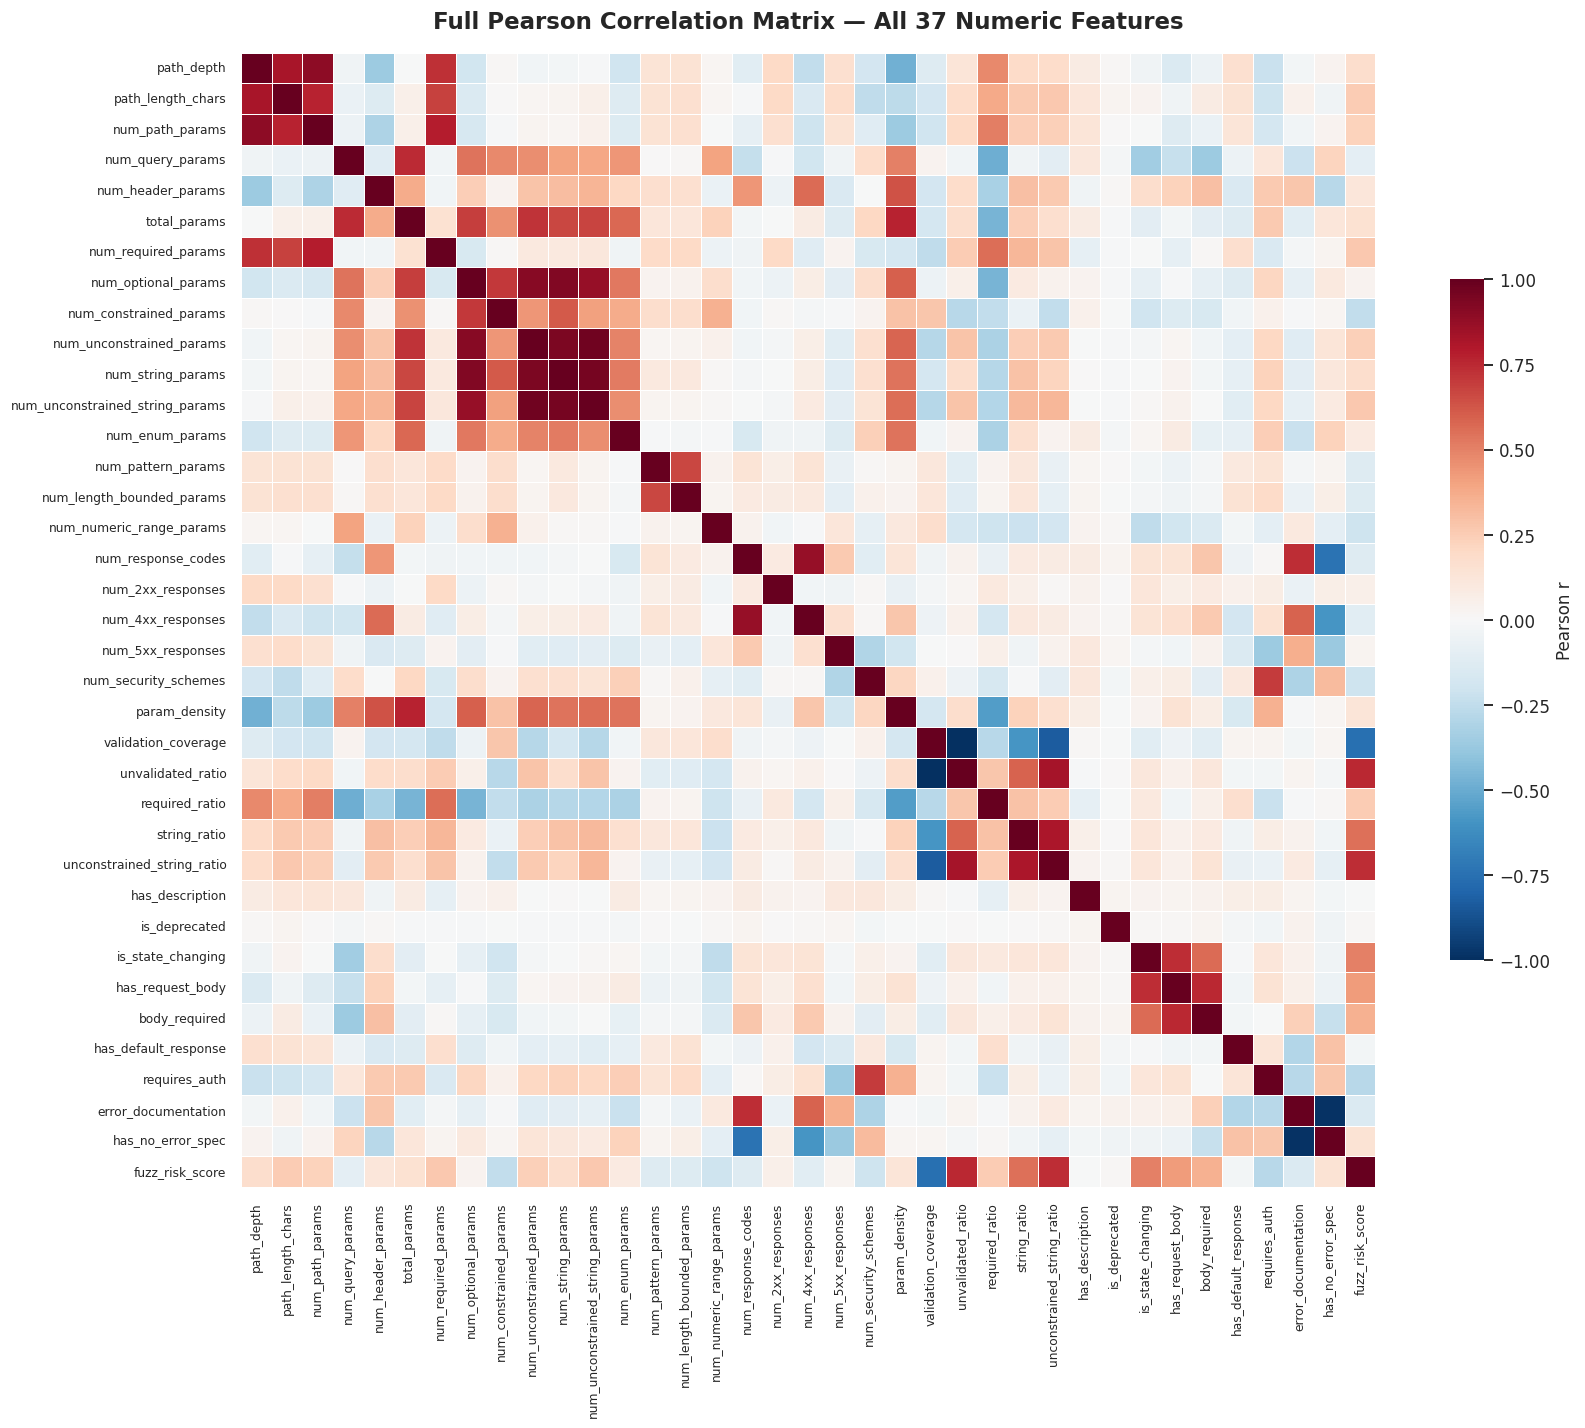

In [37]:
num_cols = [
    "path_depth", "path_length_chars", "num_path_params", "num_query_params",
    "num_header_params", "total_params", "num_required_params",
    "num_optional_params", "num_constrained_params", "num_unconstrained_params",
    "num_string_params", "num_unconstrained_string_params", "num_enum_params",
    "num_pattern_params", "num_length_bounded_params", "num_numeric_range_params",
    "num_response_codes", "num_2xx_responses", "num_4xx_responses",
    "num_5xx_responses", "num_security_schemes", "param_density",
    "validation_coverage", "unvalidated_ratio", "required_ratio", "string_ratio",
    "unconstrained_string_ratio", "has_description", "is_deprecated",
    "is_state_changing", "has_request_body", "body_required",
    "has_default_response", "requires_auth", "error_documentation",
    "has_no_error_spec", "fuzz_risk_score",
]

pearson = df[num_cols].corr(method="pearson")

fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(pearson, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
            linewidths=.4, linecolor="white",
            cbar_kws={"shrink": .6, "label": "Pearson r"}, ax=ax)
ax.set_title("Full Pearson Correlation Matrix — All 37 Numeric Features",
             fontsize=15, pad=16)
ax.tick_params(axis="x", labelsize=8, rotation=90)
ax.tick_params(axis="y", labelsize=8, rotation=0)
plt.tight_layout()
save_fig(fig, "16_correlation_full_pearson")
plt.show()

## 6.2 Pearson vs Spearman

**Spearman** correlates the *ranks* rather than the raw values, so it picks up monotonic
relationships that are not straight lines and is not distorted by skew. Comparing the two
tells us whether a relationship is genuinely linear.

saved -> figures/17_pearson_vs_spearman.png


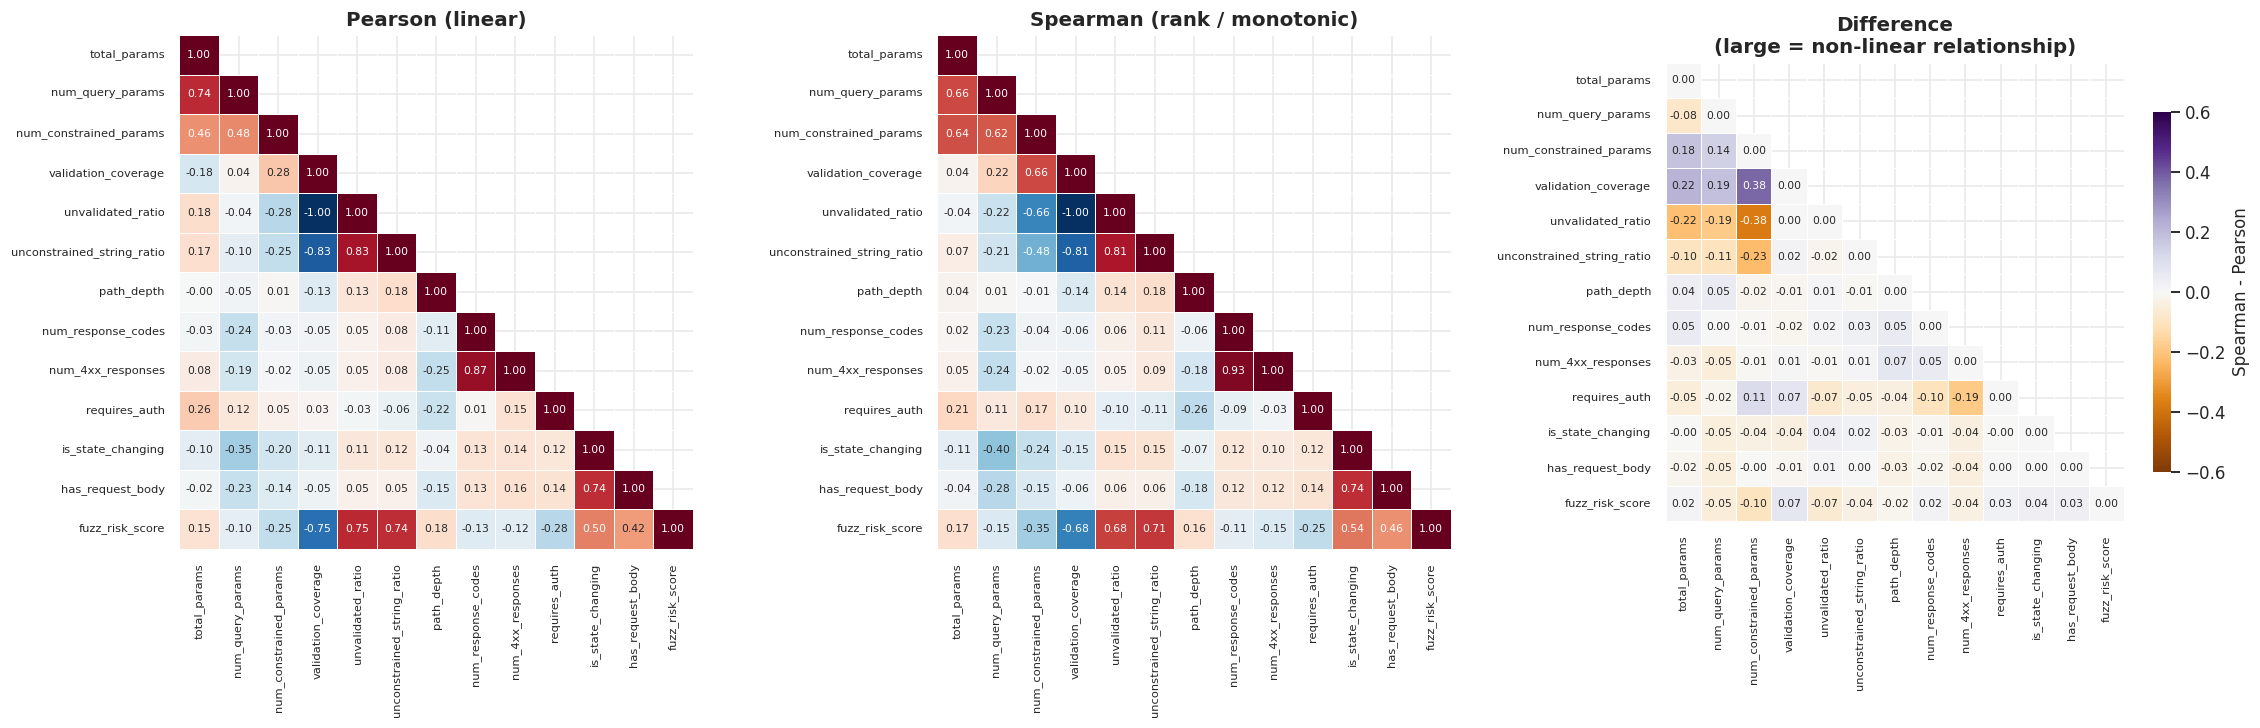

In [38]:
key_cols = [
    "total_params", "num_query_params", "num_constrained_params",
    "validation_coverage", "unvalidated_ratio", "unconstrained_string_ratio",
    "path_depth", "num_response_codes", "num_4xx_responses",
    "requires_auth", "is_state_changing", "has_request_body", "fuzz_risk_score",
]

p_corr = df[key_cols].corr(method="pearson")
s_corr = df[key_cols].corr(method="spearman")

fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
mask = np.triu(np.ones_like(p_corr, dtype=bool), k=1)

sns.heatmap(p_corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, linewidths=.5, linecolor="white",
            cbar=False, annot_kws={"size": 7}, ax=axes[0])
axes[0].set_title("Pearson (linear)")

sns.heatmap(s_corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, linewidths=.5, linecolor="white",
            cbar=False, annot_kws={"size": 7}, ax=axes[1])
axes[1].set_title("Spearman (rank / monotonic)")

diff = s_corr - p_corr
sns.heatmap(diff, mask=mask, annot=True, fmt=".2f", cmap="PuOr", center=0,
            vmin=-.6, vmax=.6, square=True, linewidths=.5, linecolor="white",
            cbar_kws={"shrink": .7, "label": "Spearman - Pearson"},
            annot_kws={"size": 7}, ax=axes[2])
axes[2].set_title("Difference\n(large = non-linear relationship)")

for ax in axes:
    ax.tick_params(axis="x", labelsize=7.5, rotation=90)
    ax.tick_params(axis="y", labelsize=7.5, rotation=0)

plt.tight_layout()
save_fig(fig, "17_pearson_vs_spearman")
plt.show()

## 6.3 What correlates with the target?

The single most useful correlation view: every feature ranked by its association with
`fuzz_risk_score`.

saved -> figures/18_target_correlation.png


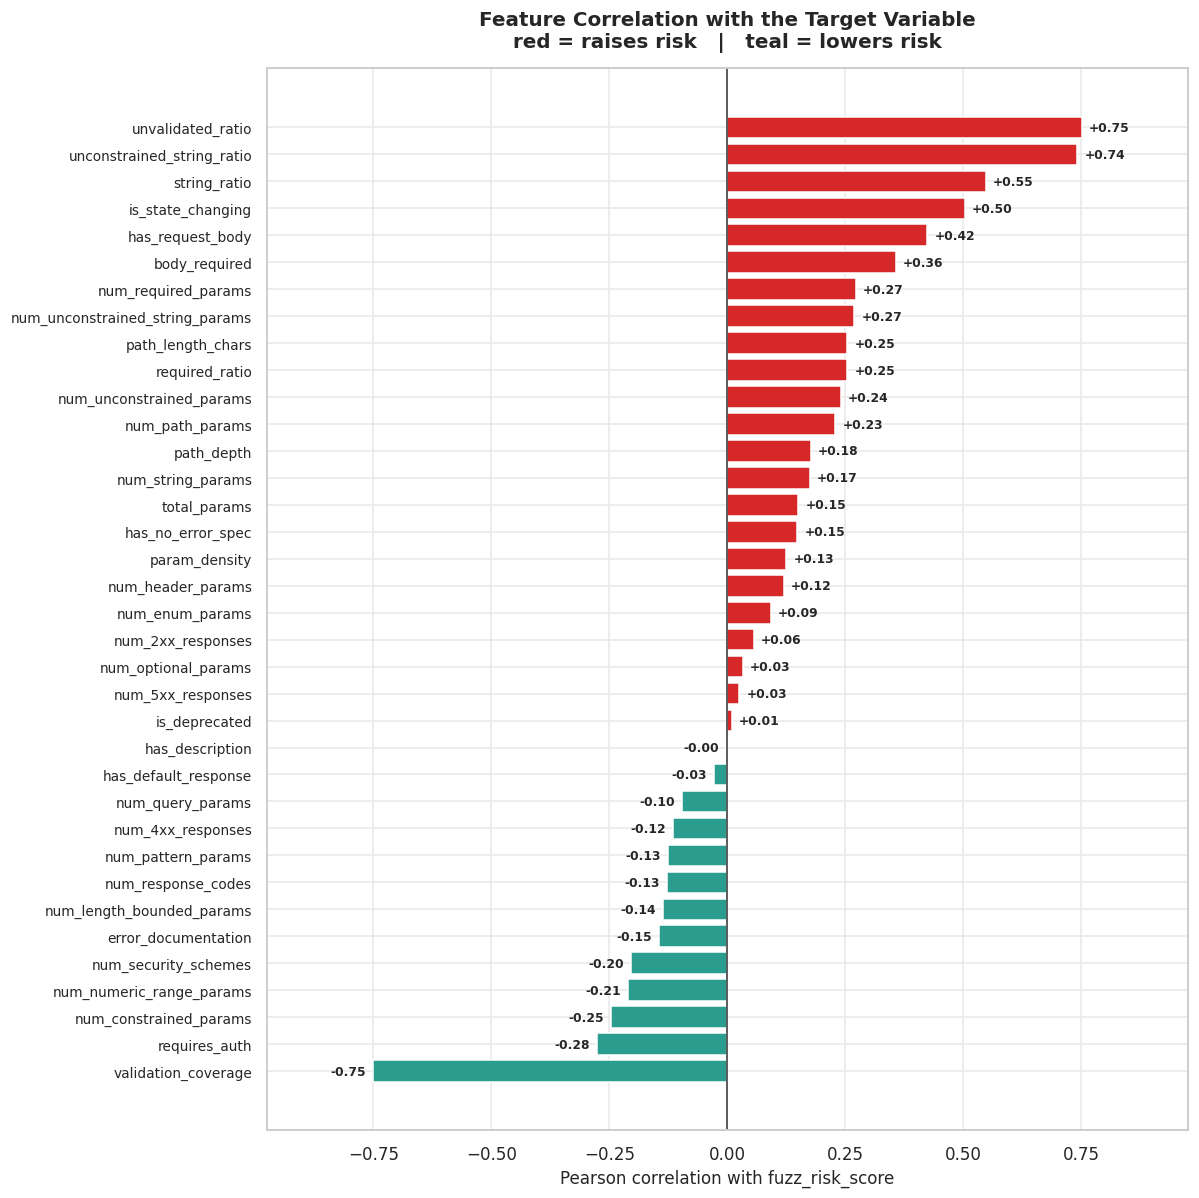

Strongest positive drivers of risk:
unvalidated_ratio            0.751
unconstrained_string_ratio   0.741
string_ratio                 0.548
is_state_changing            0.503
has_request_body             0.424

Strongest negative (protective) factors:
validation_coverage        -0.751
requires_auth              -0.277
num_constrained_params     -0.247
num_numeric_range_params   -0.211
num_security_schemes       -0.204


In [39]:
target_corr = (df[num_cols].corr()["fuzz_risk_score"]
                 .drop("fuzz_risk_score")
                 .sort_values())

fig, ax = plt.subplots(figsize=(11, 11))
colors = [RED if v > 0 else TEAL for v in target_corr.values]
ax.barh(target_corr.index, target_corr.values, color=colors, edgecolor="white")
ax.axvline(0, color="#333", lw=1)

for i, v in enumerate(target_corr.values):
    ax.text(v + (.015 if v >= 0 else -.015), i, f"{v:+.2f}",
            va="center", ha="left" if v >= 0 else "right",
            fontsize=8, fontweight="bold")

ax.set_xlabel("Pearson correlation with fuzz_risk_score")
ax.set_title("Feature Correlation with the Target Variable\n"
             "red = raises risk   |   teal = lowers risk", pad=14)
ax.set_xlim(target_corr.min()*1.30, target_corr.max()*1.30)
ax.tick_params(axis="y", labelsize=9)
plt.tight_layout()
save_fig(fig, "18_target_correlation")
plt.show()

print("Strongest positive drivers of risk:")
print(target_corr.tail(5).sort_values(ascending=False).round(3).to_string())
print("\nStrongest negative (protective) factors:")
print(target_corr.head(5).round(3).to_string())

## 6.4 Hierarchically clustered correlation

A **clustermap** reorders rows and columns so that features behaving alike sit together.
The dendrograms on the edges show the grouping. This reveals the natural "families" of
features in the data.

saved -> figures/19_correlation_clustermap.png


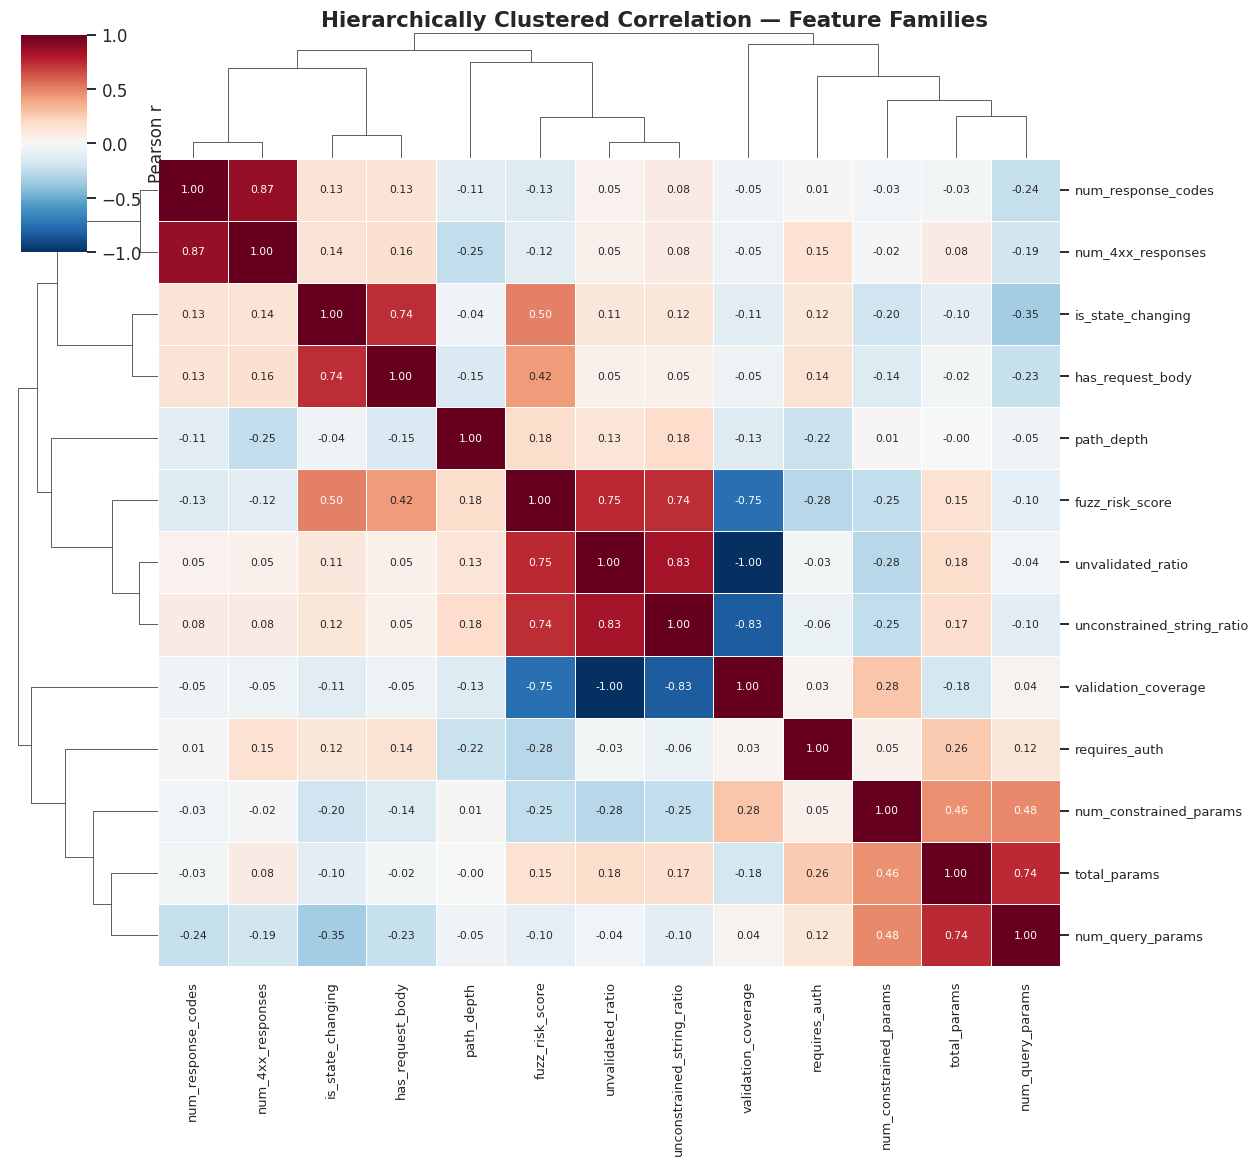

In [40]:
g = sns.clustermap(
    df[key_cols].corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1,
    annot=True, fmt=".2f", annot_kws={"size": 7},
    linewidths=.5, linecolor="white", figsize=(12, 11),
    cbar_kws={"label": "Pearson r"}, dendrogram_ratio=.14,
)
g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xticklabels(), rotation=90, fontsize=8.5)
g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_yticklabels(), rotation=0, fontsize=8.5)
g.figure.suptitle("Hierarchically Clustered Correlation — Feature Families",
                  fontsize=14, fontweight="bold", y=1.0)
save_fig(g.figure, "19_correlation_clustermap")
plt.show()

## 6.5 Multicollinearity check (VIF)

When features are near-duplicates of each other, a model cannot tell their effects apart.
The **Variance Inflation Factor** quantifies this. It is read off the diagonal of the
inverted correlation matrix.

* VIF < 5 — fine
* 5 ≤ VIF < 10 — moderate concern
* VIF ≥ 10 — severe; drop one of the pair

saved -> figures/20_vif_multicollinearity.png


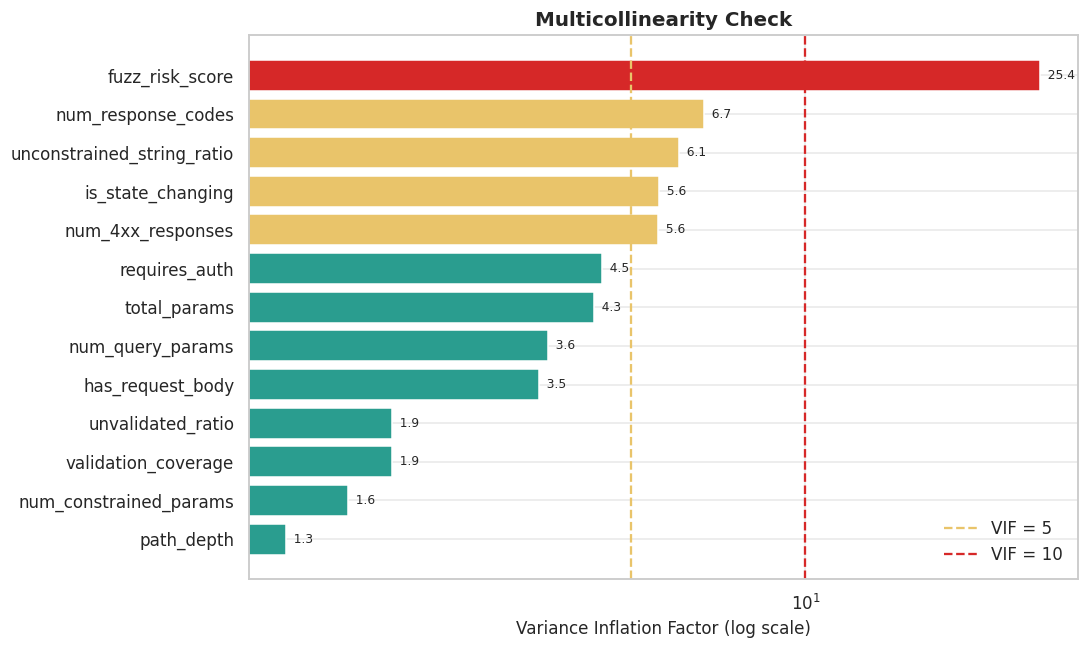

,feature,VIF,verdict
0,fuzz_risk_score,25.440,severe
1,num_response_codes,6.680,moderate
2,unconstrained_string_ratio,6.060,moderate
3,is_state_changing,5.580,moderate
4,num_4xx_responses,5.570,moderate
5,requires_auth,4.460,OK
6,total_params,4.320,OK
7,num_query_params,3.590,OK
8,has_request_body,3.460,OK
9,validation_coverage,1.930,OK


In [41]:
vif_cols = [c for c in key_cols if df[c].std() > 0]
C = df[vif_cols].corr().values

# VIF_i is the i-th diagonal element of the inverse correlation matrix
vif_vals = np.diag(np.linalg.pinv(C))

vif = (pd.DataFrame({"feature": vif_cols, "VIF": vif_vals.round(2)})
         .sort_values("VIF", ascending=False)
         .reset_index(drop=True))
vif["verdict"] = pd.cut(vif["VIF"], bins=[-np.inf, 5, 10, np.inf],
                        labels=["OK", "moderate", "severe"])

fig, ax = plt.subplots(figsize=(10, 6))
cmap = {"OK": TEAL, "moderate": AMBER, "severe": RED}
sub = vif.sort_values("VIF")
ax.barh(sub["feature"], sub["VIF"], color=[cmap[v] for v in sub["verdict"]])
ax.axvline(5, color=AMBER, ls="--", lw=1.5, label="VIF = 5")
ax.axvline(10, color=RED, ls="--", lw=1.5, label="VIF = 10")
for i, v in enumerate(sub["VIF"]):
    ax.text(v, i, f"  {v:.1f}", va="center", fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("Variance Inflation Factor (log scale)")
ax.set_title("Multicollinearity Check")
ax.legend()
plt.tight_layout()
save_fig(fig, "20_vif_multicollinearity")
plt.show()

vif

The high-VIF pairs are the ones we built ourselves — `validation_coverage` and
`unvalidated_ratio` are `1 − x` of each other by definition, so they are perfectly
redundant. For modelling, keep one of each such pair.

## 6.6 Pair plot of the key features

A pair plot draws every pairwise scatter plus each feature's own distribution on the
diagonal, split by risk band.

saved -> figures/21_pairplot.png


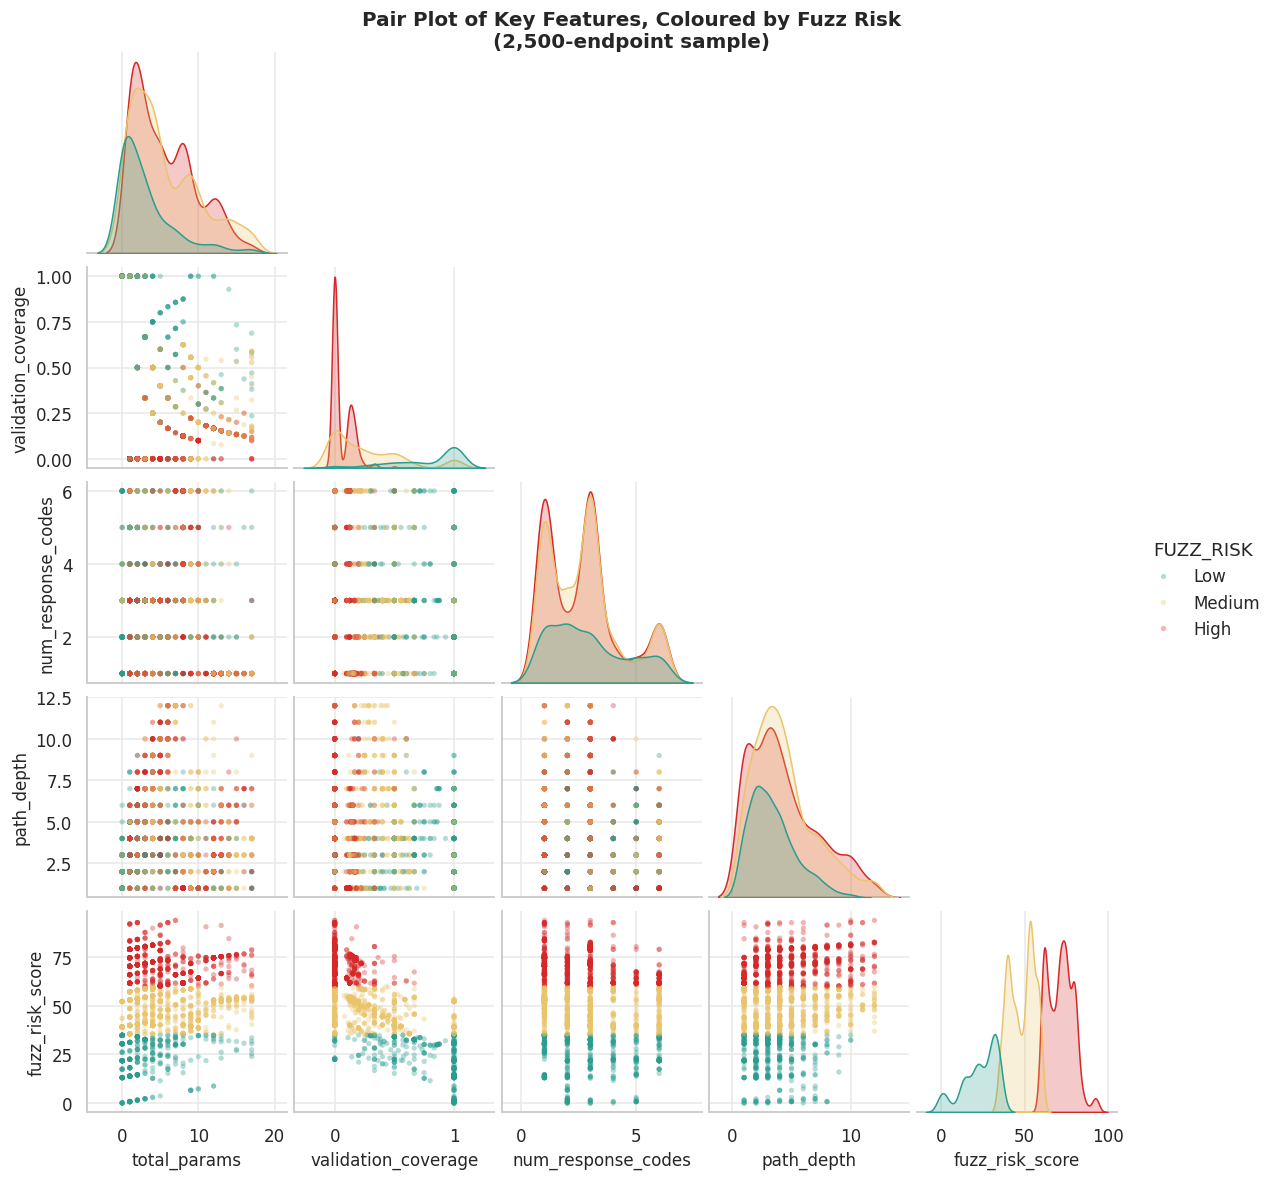

In [42]:
pair_cols = ["total_params", "validation_coverage", "num_response_codes",
             "path_depth", "fuzz_risk_score"]

pair_sample = df.sample(n=min(2500, len(df)), random_state=42)

g = sns.pairplot(pair_sample[pair_cols + ["FUZZ_RISK"]], hue="FUZZ_RISK",
                 palette=RISK_COLORS, hue_order=["Low", "Medium", "High"],
                 corner=True, diag_kind="kde",
                 plot_kws={"s": 12, "alpha": .35, "edgecolor": "none"},
                 height=2.1)
g.figure.suptitle("Pair Plot of Key Features, Coloured by Fuzz Risk\n"
                  "(2,500-endpoint sample)", y=1.02, fontsize=13, fontweight="bold")
save_fig(g.figure, "21_pairplot")
plt.show()

# 7. Complete Visualisation Gallery

This section works through the full range of standard chart types, grouped by what each
one is *for*. Every chart answers a real question about the data — none are decoration.

| Purpose | Charts used |
|:--|:--|
| Show a distribution | histogram, KDE, violin, boxen, ECDF, ridge |
| Compare categories | count, donut, treemap, lollipop, Pareto |
| Show a relationship | hexbin, joint, bubble, regression |
| Show composition | stacked area, 100% stacked bar, grouped bar |
| Show a matrix | pivot heatmap, annotated matrix |
| Show many variables at once | radar, parallel coordinates, facet grid |

## 7.1 Distribution shapes — KDE, violin, boxen, ECDF

saved -> figures/22_distribution_shapes.png


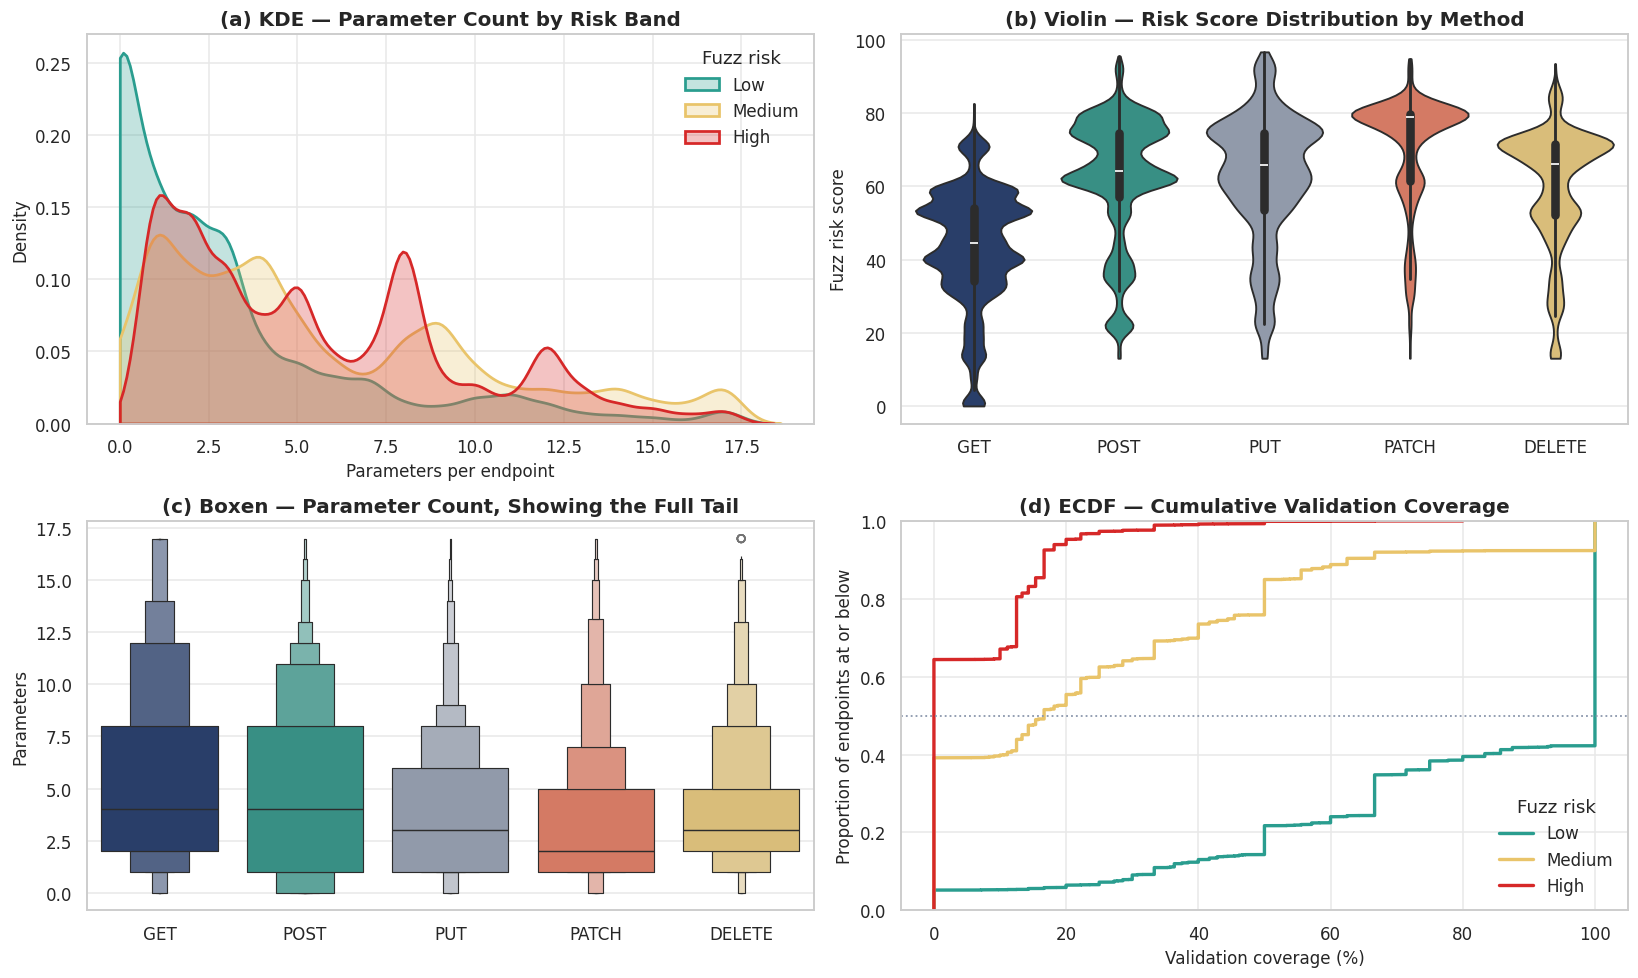

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# (a) KDE - smoothed density by risk band
for lvl in ["Low", "Medium", "High"]:
    sns.kdeplot(df[df["FUZZ_RISK"] == lvl]["total_params"], ax=axes[0, 0],
                fill=True, alpha=.28, linewidth=1.8,
                color=RISK_COLORS[lvl], label=lvl, clip=(0, None))
axes[0, 0].set_title("(a) KDE — Parameter Count by Risk Band")
axes[0, 0].set_xlabel("Parameters per endpoint")
axes[0, 0].legend(title="Fuzz risk")

# (b) violin - distribution shape + median
order = ["GET", "POST", "PUT", "PATCH", "DELETE"]
sns.violinplot(data=df[df["http_method"].isin(order)], x="http_method",
               y="fuzz_risk_score", order=order, hue="http_method",
               palette=SEQ[:5], legend=False, cut=0, ax=axes[0, 1])
axes[0, 1].set_title("(b) Violin — Risk Score Distribution by Method")
axes[0, 1].set_xlabel(""); axes[0, 1].set_ylabel("Fuzz risk score")

# (c) boxen (letter-value) - better than a box plot for big data
sns.boxenplot(data=df[df["http_method"].isin(order)], x="http_method",
              y="total_params", order=order, hue="http_method",
              palette=SEQ[:5], legend=False, ax=axes[1, 0])
axes[1, 0].set_title("(c) Boxen — Parameter Count, Showing the Full Tail")
axes[1, 0].set_xlabel(""); axes[1, 0].set_ylabel("Parameters")

# (d) ECDF - "what fraction of endpoints are below x?"
for lvl in ["Low", "Medium", "High"]:
    sns.ecdfplot(df[df["FUZZ_RISK"] == lvl]["validation_coverage"]*100,
                 ax=axes[1, 1], color=RISK_COLORS[lvl], lw=2.2, label=lvl)
axes[1, 1].axhline(.5, color=GREY, ls=":", lw=1.2)
axes[1, 1].set_title("(d) ECDF — Cumulative Validation Coverage")
axes[1, 1].set_xlabel("Validation coverage (%)")
axes[1, 1].set_ylabel("Proportion of endpoints at or below")
axes[1, 1].legend(title="Fuzz risk")

plt.tight_layout()
save_fig(fig, "22_distribution_shapes")
plt.show()

## 7.2 Ridge plot — one distribution stacked per category

saved -> figures/23_ridge_plot.png


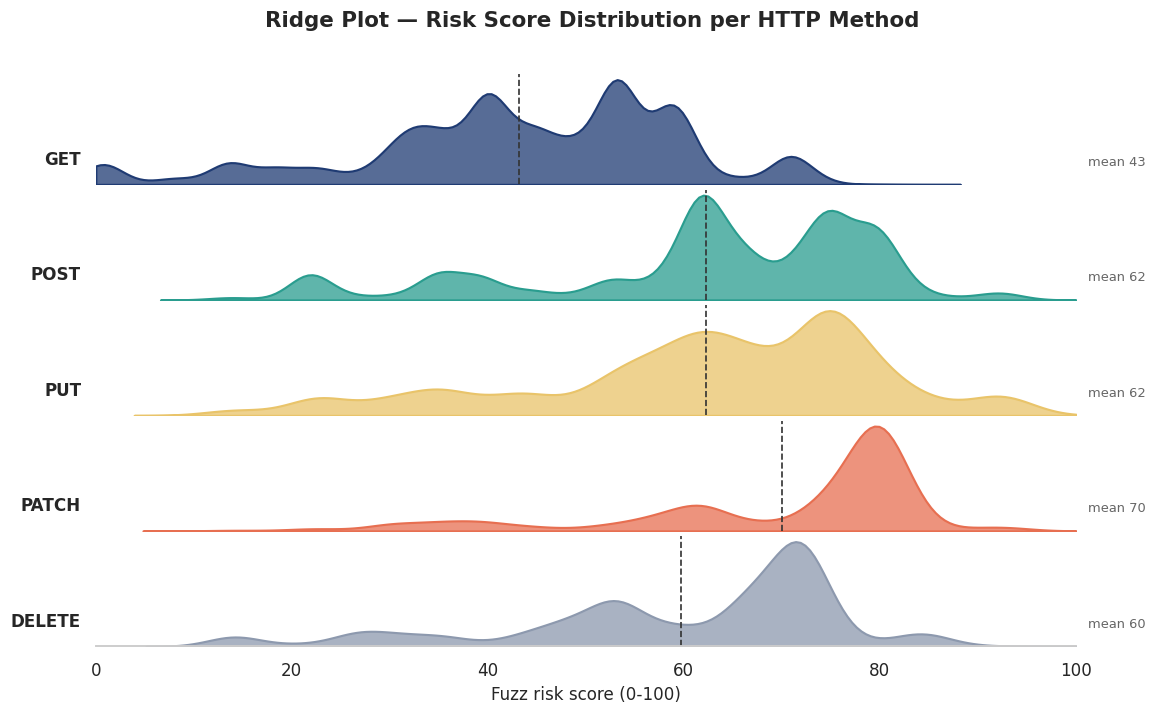

In [44]:
order = ["GET", "POST", "PUT", "PATCH", "DELETE"]
fig, axes = plt.subplots(len(order), 1, figsize=(11, 6.5), sharex=True)

for i, (ax, m) in enumerate(zip(axes, order)):
    vals = df[df["http_method"] == m]["fuzz_risk_score"]
    sns.kdeplot(vals, ax=ax, fill=True, alpha=.75, linewidth=1.4,
                color=SEQ[i], clip=(0, 100))
    ax.axvline(vals.mean(), color="#333", ls="--", lw=1.1)
    ax.set_xlim(0, 100)
    ax.set_ylabel("")
    ax.set_yticks([])
    # labels placed in axes coordinates so they cannot stretch the figure
    ax.text(-0.015, .15, m, transform=ax.transAxes, ha="right", va="bottom",
            fontweight="bold", fontsize=11)
    ax.text(1.012, .15, f"mean {vals.mean():.0f}", transform=ax.transAxes,
            ha="left", va="bottom", fontsize=8.5, color="#666")
    for s in ["left", "right", "top"]:
        ax.spines[s].set_visible(False)
    ax.grid(False)
    if i < len(order)-1:
        ax.spines["bottom"].set_visible(False)

axes[-1].set_xlabel("Fuzz risk score (0-100)")
fig.suptitle("Ridge Plot — Risk Score Distribution per HTTP Method",
             fontsize=14, fontweight="bold", y=.99)
fig.subplots_adjust(left=.09, right=.90, top=.90, bottom=.10, hspace=.05)
save_fig(fig, "23_ridge_plot")
plt.show()

## 7.3 Comparing categories — count, donut, treemap, lollipop, Pareto

saved -> figures/24_category_comparisons.png


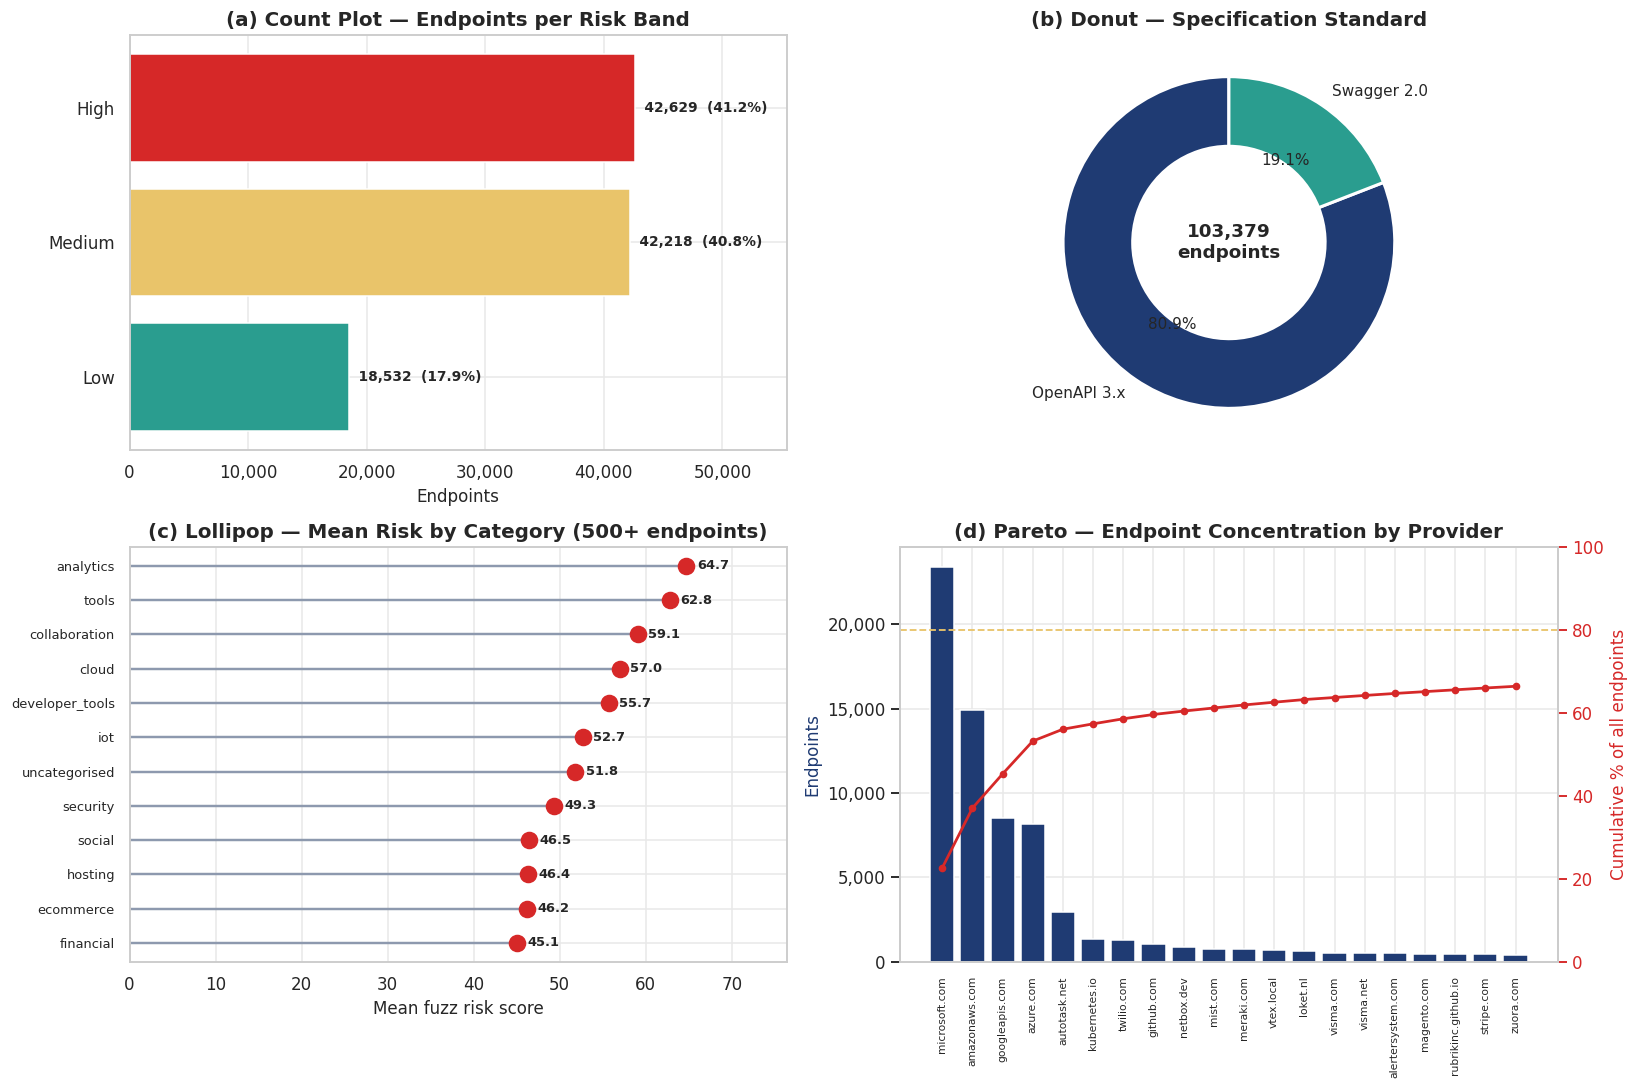

In [45]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# (a) count plot
cnt = df["FUZZ_RISK"].value_counts().reindex(["High", "Medium", "Low"])
axes[0, 0].barh(cnt.index.astype(str), cnt.values,
                color=[RISK_COLORS[i] for i in cnt.index], edgecolor="white")
axes[0, 0].invert_yaxis()
for i, v in enumerate(cnt.values):
    axes[0, 0].text(v, i, f"  {v:,}  ({v/len(df)*100:.1f}%)", va="center",
                    fontsize=9, fontweight="bold")
axes[0, 0].set_xlim(0, cnt.max()*1.30)
axes[0, 0].set_title("(a) Count Plot — Endpoints per Risk Band")
axes[0, 0].set_xlabel("Endpoints"); axes[0, 0].set_ylabel("")
axes[0, 0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:,.0f}"))

# (b) donut chart
spec = df["spec_version"].value_counts()
w, t, a = axes[0, 1].pie(spec.values, labels=spec.index, autopct="%1.1f%%",
                         startangle=90, colors=[NAVY, TEAL],
                         wedgeprops={"width": .42, "edgecolor": "white",
                                     "linewidth": 2},
                         textprops={"fontsize": 10})
axes[0, 1].text(0, 0, f"{len(df):,}\nendpoints", ha="center", va="center",
                fontsize=12, fontweight="bold")
axes[0, 1].set_title("(b) Donut — Specification Standard")

# (c) lollipop chart
cat_risk = (df.groupby("category")
              .agg(n=("path", "size"), risk=("fuzz_risk_score", "mean"))
              .query("n >= 500").sort_values("risk").tail(12))
axes[1, 0].hlines(y=cat_risk.index, xmin=0, xmax=cat_risk["risk"],
                  color=GREY, lw=1.6)
axes[1, 0].scatter(cat_risk["risk"], cat_risk.index, s=110, color=RED, zorder=3)
for y, v in zip(cat_risk.index, cat_risk["risk"]):
    axes[1, 0].text(v + 1.2, y, f"{v:.1f}", va="center", fontsize=8.5,
                    fontweight="bold")
axes[1, 0].set_xlim(0, cat_risk["risk"].max()*1.18)
axes[1, 0].set_xlabel("Mean fuzz risk score")
axes[1, 0].set_title("(c) Lollipop — Mean Risk by Category (500+ endpoints)")
axes[1, 0].tick_params(axis="y", labelsize=8.5)

# (d) Pareto chart - which providers account for most endpoints
prov_n = df["api_provider"].value_counts().head(20)
cum = prov_n.cumsum() / df["api_provider"].value_counts().sum() * 100
axes[1, 1].bar(range(len(prov_n)), prov_n.values, color=NAVY, edgecolor="white")
ax2 = axes[1, 1].twinx()
ax2.plot(range(len(prov_n)), cum.values, color=RED, marker="o", ms=4, lw=1.8)
ax2.set_ylabel("Cumulative % of all endpoints", color=RED)
ax2.tick_params(axis="y", colors=RED)
ax2.set_ylim(0, 100); ax2.grid(False)
ax2.axhline(80, color=AMBER, ls="--", lw=1.2)
axes[1, 1].set_xticks(range(len(prov_n)))
axes[1, 1].set_xticklabels(prov_n.index, rotation=90, fontsize=7)
axes[1, 1].set_ylabel("Endpoints", color=NAVY)
axes[1, 1].set_title("(d) Pareto — Endpoint Concentration by Provider")
axes[1, 1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:,.0f}"))

plt.tight_layout()
save_fig(fig, "24_category_comparisons")
plt.show()

saved -> figures/25_treemap_categories.png


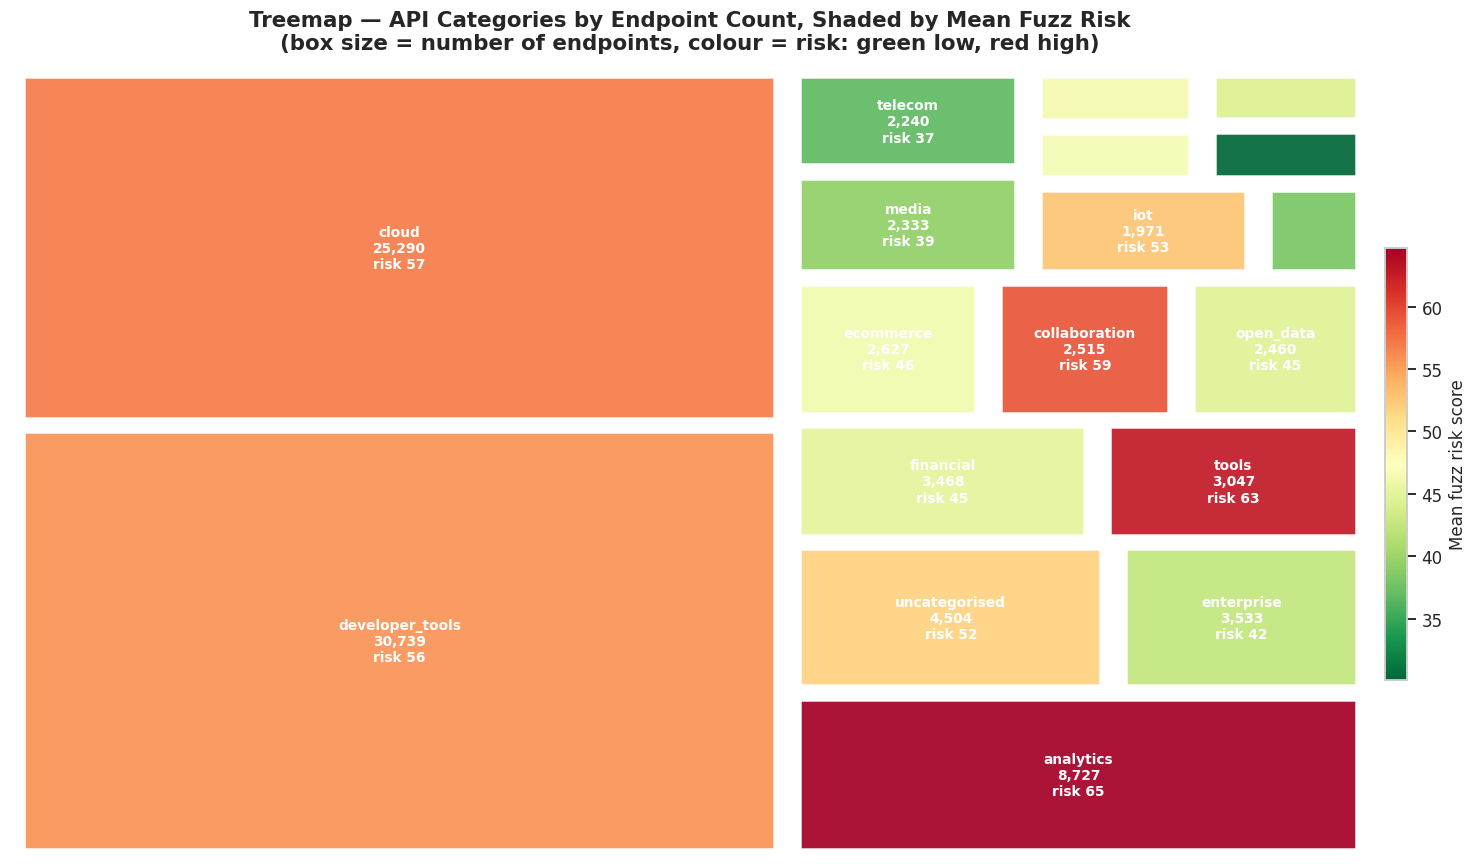

In [46]:
import squarify

cat_n = df["category"].value_counts().head(18)
cat_r = df.groupby("category")["fuzz_risk_score"].mean()

norm = plt.Normalize(cat_r[cat_n.index].min(), cat_r[cat_n.index].max())
cmap = plt.cm.RdYlGn_r
colors = [cmap(norm(cat_r[c])) for c in cat_n.index]

labels = [f"{c}\n{n:,}\nrisk {cat_r[c]:.0f}" if n > cat_n.max()*.05 else ""
          for c, n in cat_n.items()]

fig, ax = plt.subplots(figsize=(15, 8))
squarify.plot(sizes=cat_n.values, label=labels, color=colors, alpha=.92,
              text_kwargs={"fontsize": 9, "fontweight": "bold", "color": "white"},
              pad=True, ax=ax)
ax.axis("off")
ax.set_title("Treemap — API Categories by Endpoint Count, Shaded by Mean Fuzz Risk\n"
             "(box size = number of endpoints, colour = risk: green low, red high)",
             fontsize=14, pad=14)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cb = fig.colorbar(sm, ax=ax, shrink=.55, pad=.01)
cb.set_label("Mean fuzz risk score")

plt.tight_layout()
save_fig(fig, "25_treemap_categories")
plt.show()

## 7.4 Relationships — hexbin, joint plot, bubble, regression

saved -> figures/26_relationships_hexbin_bubble.png


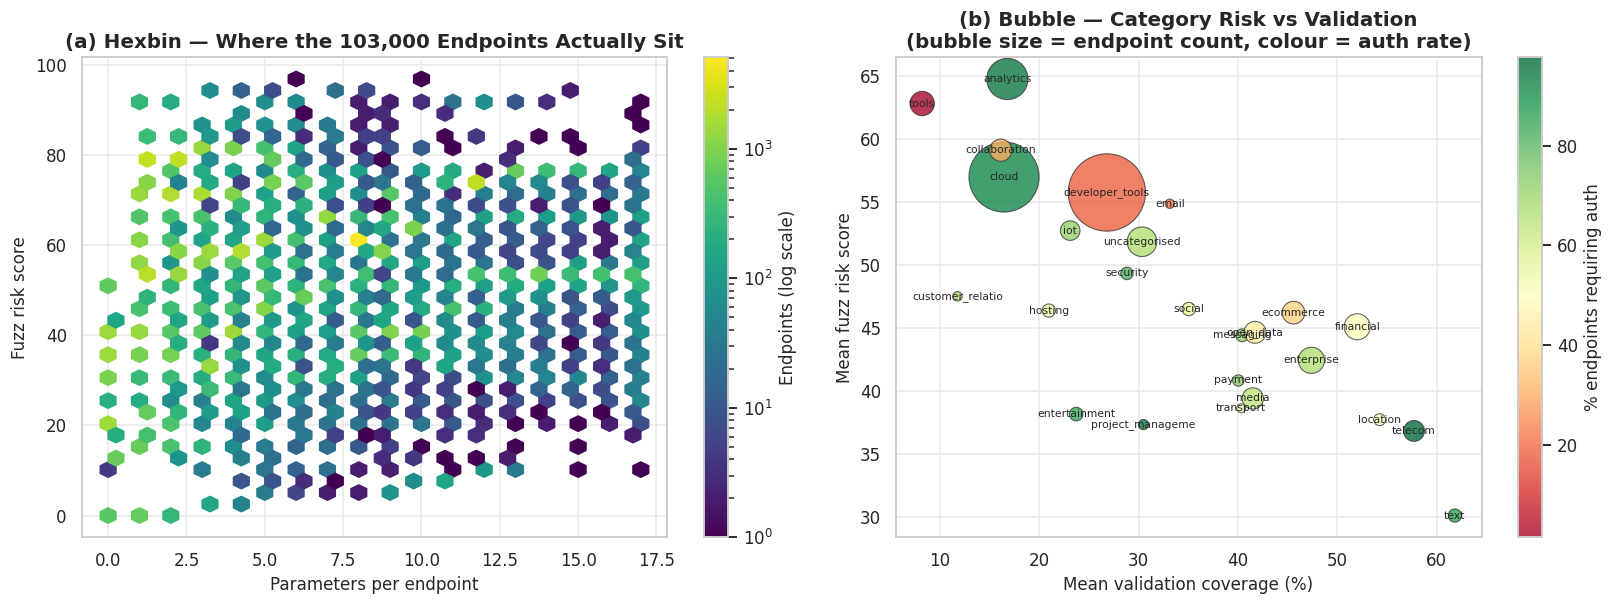

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))

# (a) hexbin - density where a scatter plot would be one solid blob
hb = axes[0].hexbin(df["total_params"], df["fuzz_risk_score"],
                    gridsize=34, cmap="viridis", mincnt=1, bins="log")
cb = fig.colorbar(hb, ax=axes[0]); cb.set_label("Endpoints (log scale)")
axes[0].set_xlabel("Parameters per endpoint")
axes[0].set_ylabel("Fuzz risk score")
axes[0].set_title("(a) Hexbin — Where the 103,000 Endpoints Actually Sit")

# (b) bubble chart - three variables at once
bub = (df.groupby("category")
         .agg(n=("path", "size"),
              cov=("validation_coverage", "mean"),
              risk=("fuzz_risk_score", "mean"),
              auth=("requires_auth", "mean"))
         .query("n >= 300"))
sc = axes[1].scatter(bub["cov"]*100, bub["risk"], s=bub["n"]/12,
                     c=bub["auth"]*100, cmap="RdYlGn", alpha=.78,
                     edgecolors="#333", linewidths=.7)
cb = fig.colorbar(sc, ax=axes[1]); cb.set_label("% endpoints requiring auth")
for cat, r in bub.iterrows():
    axes[1].annotate(cat[:16], (r["cov"]*100, r["risk"]), fontsize=7,
                     ha="center", va="center")
axes[1].set_xlabel("Mean validation coverage (%)")
axes[1].set_ylabel("Mean fuzz risk score")
axes[1].set_title("(b) Bubble — Category Risk vs Validation\n"
                  "(bubble size = endpoint count, colour = auth rate)")

plt.tight_layout()
save_fig(fig, "26_relationships_hexbin_bubble")
plt.show()

saved -> figures/27_jointplot.png


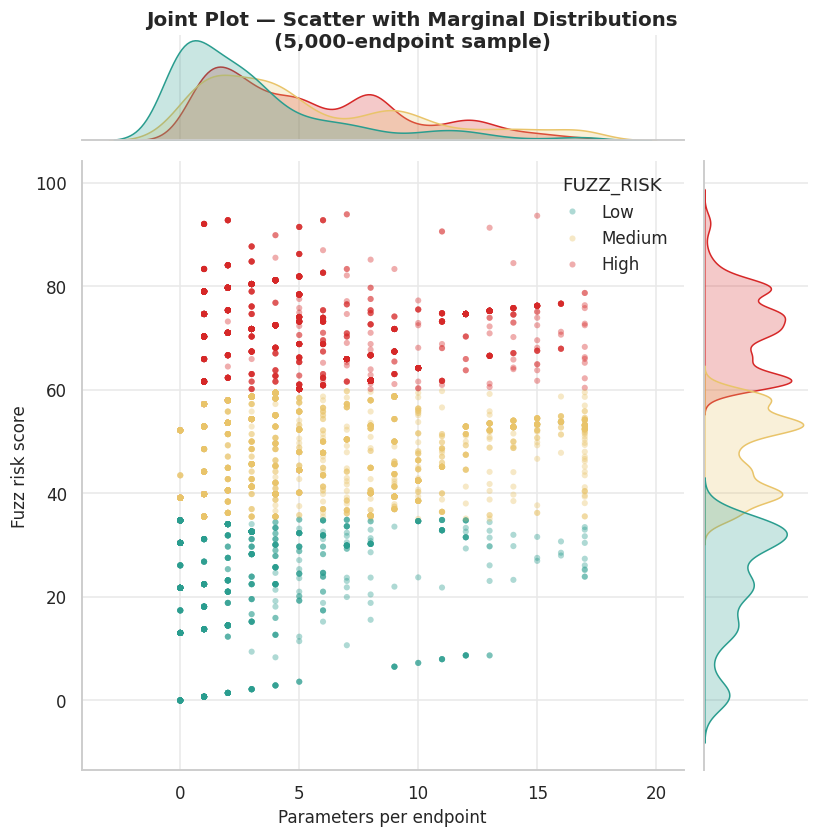

In [48]:
jp_sample = df.sample(n=min(5000, len(df)), random_state=42)

g = sns.jointplot(data=jp_sample, x="total_params", y="fuzz_risk_score",
                  kind="scatter", hue="FUZZ_RISK", palette=RISK_COLORS,
                  hue_order=["Low", "Medium", "High"],
                  height=7.5, ratio=5, marginal_kws={"common_norm": False},
                  joint_kws={"s": 16, "alpha": .38, "edgecolor": "none"})
g.figure.suptitle("Joint Plot — Scatter with Marginal Distributions\n"
                  "(5,000-endpoint sample)", y=1.01, fontsize=13,
                  fontweight="bold")
g.set_axis_labels("Parameters per endpoint", "Fuzz risk score")
save_fig(g.figure, "27_jointplot")
plt.show()

saved -> figures/28_regression_plots.png


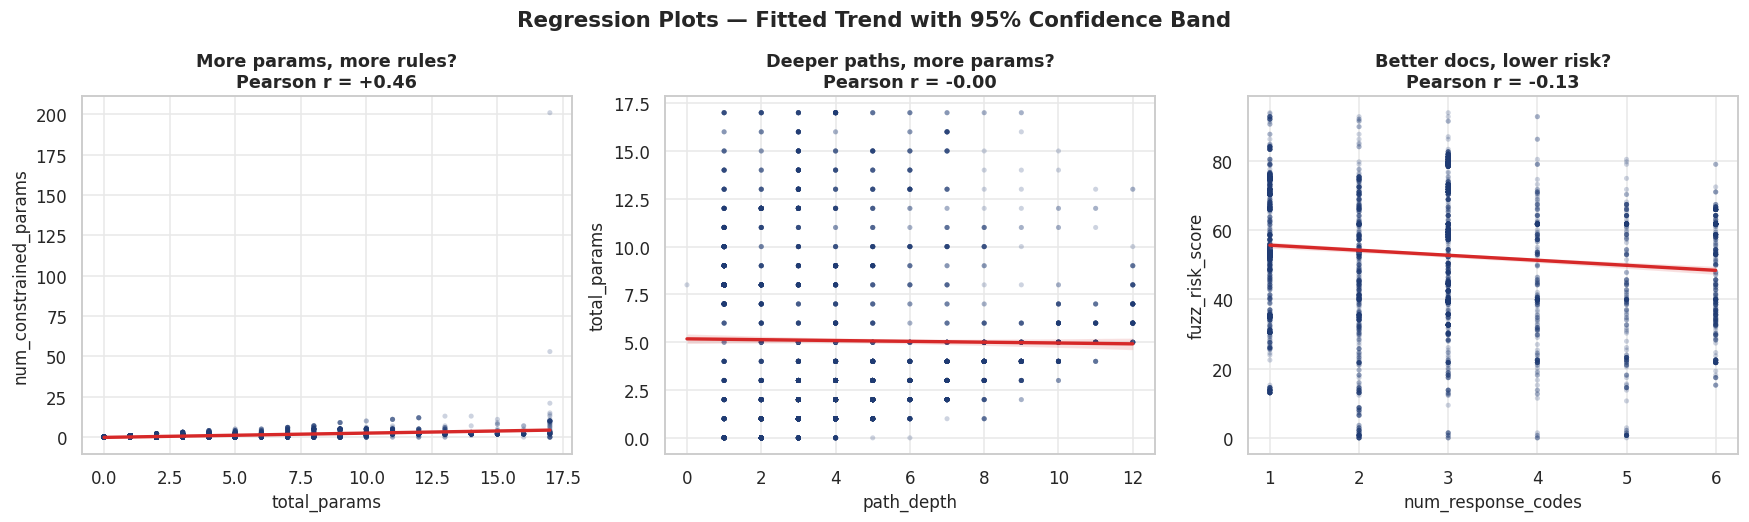

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

pairs_to_plot = [
    ("total_params", "num_constrained_params", "More params, more rules?"),
    ("path_depth", "total_params", "Deeper paths, more params?"),
    ("num_response_codes", "fuzz_risk_score", "Better docs, lower risk?"),
]

reg_sample = df.sample(n=min(4000, len(df)), random_state=42)

for ax, (x, y, title) in zip(axes, pairs_to_plot):
    sns.regplot(data=reg_sample, x=x, y=y, ax=ax,
                scatter_kws={"s": 11, "alpha": .22, "color": NAVY,
                             "edgecolor": "none"},
                line_kws={"color": RED, "lw": 2.2})
    r = df[x].corr(df[y])
    ax.set_title(f"{title}\nPearson r = {r:+.2f}", fontsize=11.5)

fig.suptitle("Regression Plots — Fitted Trend with 95% Confidence Band",
             fontsize=14, fontweight="bold")
plt.tight_layout()
save_fig(fig, "28_regression_plots")
plt.show()

## 7.5 Composition — stacked area, 100% stacked bar, grouped bar

saved -> figures/29_composition_charts.png


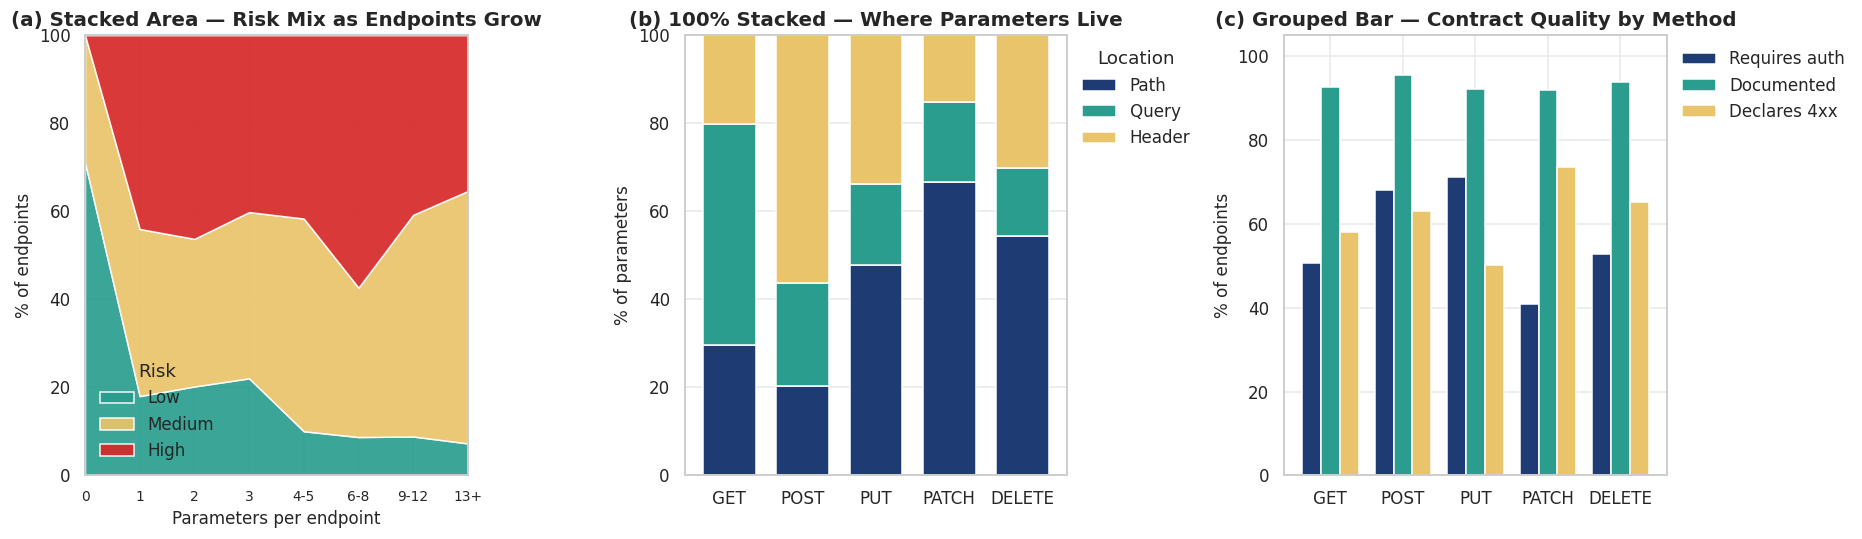

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# (a) stacked area - how the risk mix changes as endpoints get bigger
area = df.copy()
area["pbin"] = pd.cut(area["total_params"], bins=[-.1, 0, 1, 2, 3, 5, 8, 12, 100],
                      labels=["0", "1", "2", "3", "4-5", "6-8", "9-12", "13+"])
ac = (pd.crosstab(area["pbin"], area["FUZZ_RISK"], normalize="index")*100)
ac = ac[["Low", "Medium", "High"]]
axes[0].stackplot(range(len(ac)), ac["Low"], ac["Medium"], ac["High"],
                  labels=["Low", "Medium", "High"],
                  colors=[TEAL, AMBER, RED], alpha=.92)
axes[0].set_xticks(range(len(ac)))
axes[0].set_xticklabels(ac.index, fontsize=9)
axes[0].set_xlim(0, len(ac)-1); axes[0].set_ylim(0, 100)
axes[0].set_xlabel("Parameters per endpoint")
axes[0].set_ylabel("% of endpoints")
axes[0].set_title("(a) Stacked Area — Risk Mix as Endpoints Grow")
axes[0].legend(loc="lower left", title="Risk")

# (b) 100% stacked bar - parameter location mix by method
order = ["GET", "POST", "PUT", "PATCH", "DELETE"]
loc = (df[df["http_method"].isin(order)]
       .groupby("http_method", observed=True)[
           ["num_path_params", "num_query_params", "num_header_params"]]
       .sum().reindex(order))
locp = loc.div(loc.sum(axis=1), axis=0) * 100
locp.columns = ["Path", "Query", "Header"]
locp.plot(kind="bar", stacked=True, ax=axes[1], color=SEQ[:3],
          edgecolor="white", width=.72)
axes[1].set_ylabel("% of parameters"); axes[1].set_xlabel("")
axes[1].set_title("(b) 100% Stacked — Where Parameters Live")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Location", bbox_to_anchor=(1.0, 1.0))
axes[1].set_ylim(0, 100)

# (c) grouped bar - several metrics side by side
grp = (df[df["http_method"].isin(order)]
       .groupby("http_method", observed=True)
       .agg(auth=("requires_auth", "mean"),
            documented=("has_description", "mean"),
            has_4xx=("error_documentation", "mean"))
       .reindex(order) * 100)
grp.columns = ["Requires auth", "Documented", "Declares 4xx"]
grp.plot(kind="bar", ax=axes[2], color=[NAVY, TEAL, AMBER],
         edgecolor="white", width=.78)
axes[2].set_ylabel("% of endpoints"); axes[2].set_xlabel("")
axes[2].set_title("(c) Grouped Bar — Contract Quality by Method")
axes[2].tick_params(axis="x", rotation=0)
axes[2].legend(bbox_to_anchor=(1.0, 1.0))
axes[2].set_ylim(0, 105)

plt.tight_layout()
save_fig(fig, "29_composition_charts")
plt.show()

## 7.6 Matrix views — pivot heatmaps

A pivot heatmap crosses two categorical variables and colours the cell by a third,
numeric one. It is the fastest way to spot where a problem concentrates.

saved -> figures/30_pivot_heatmaps.png


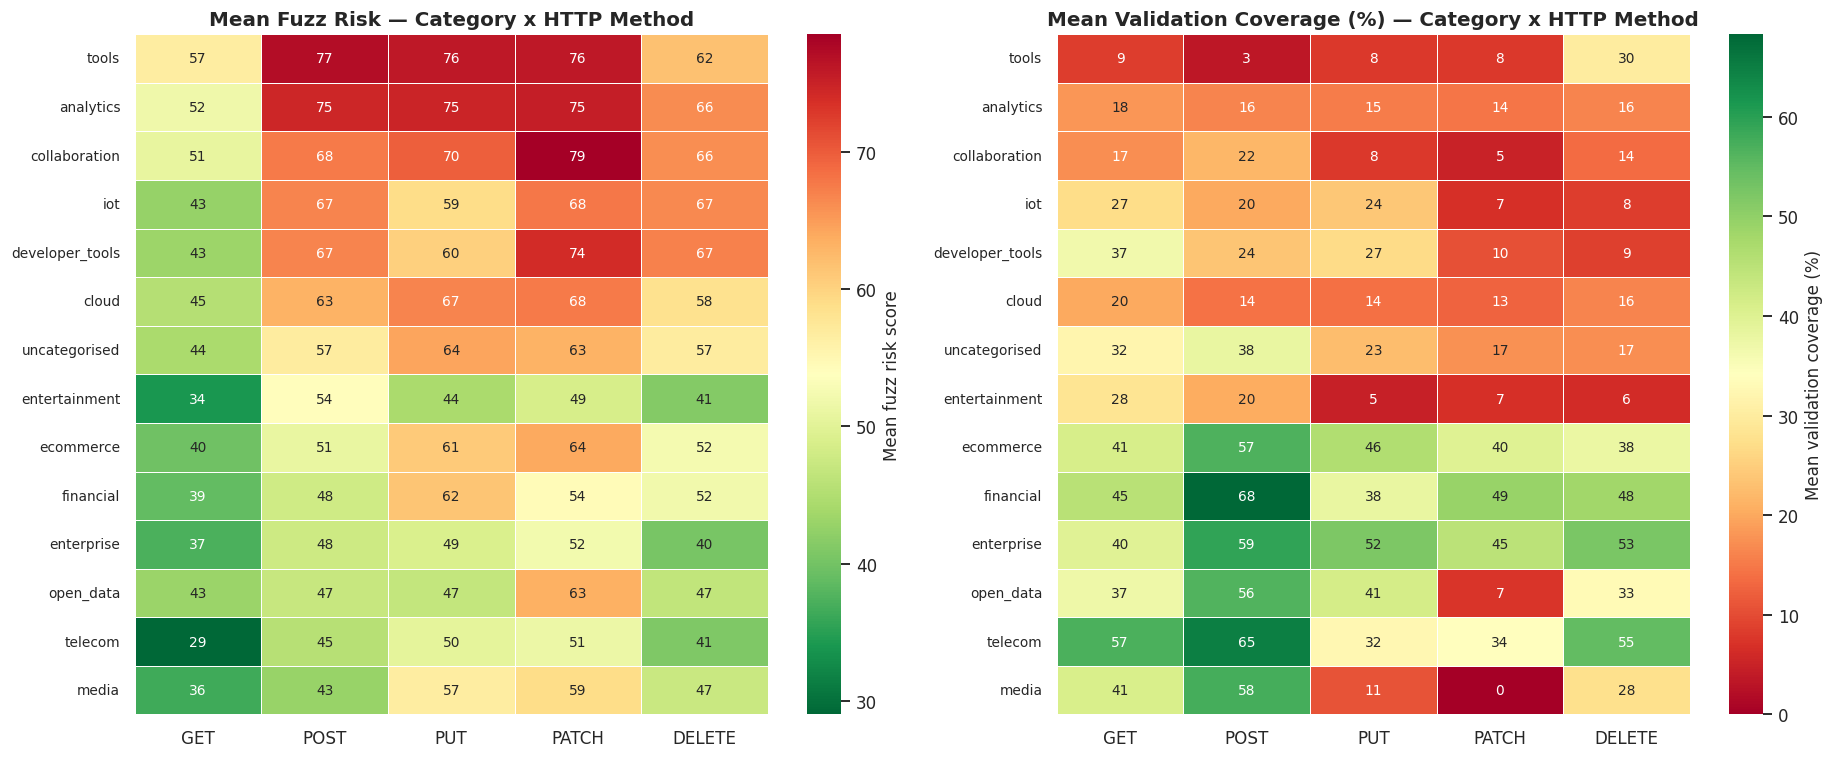

In [51]:
order = ["GET", "POST", "PUT", "PATCH", "DELETE"]
top_cats = df["category"].value_counts().head(14).index
sub = df[df["http_method"].isin(order) & df["category"].isin(top_cats)]

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

pivot_risk = sub.pivot_table(index="category", columns="http_method",
                             values="fuzz_risk_score", aggfunc="mean")[order]
pivot_risk = pivot_risk.sort_values("POST", ascending=False)
sns.heatmap(pivot_risk, annot=True, fmt=".0f", cmap="RdYlGn_r",
            linewidths=.6, linecolor="white",
            cbar_kws={"label": "Mean fuzz risk score"},
            annot_kws={"size": 9}, ax=axes[0])
axes[0].set_title("Mean Fuzz Risk — Category x HTTP Method")
axes[0].set_xlabel(""); axes[0].set_ylabel("")
axes[0].tick_params(axis="y", labelsize=9, rotation=0)

pivot_cov = sub.pivot_table(index="category", columns="http_method",
                            values="validation_coverage", aggfunc="mean")[order] * 100
pivot_cov = pivot_cov.reindex(pivot_risk.index)
sns.heatmap(pivot_cov, annot=True, fmt=".0f", cmap="RdYlGn",
            linewidths=.6, linecolor="white",
            cbar_kws={"label": "Mean validation coverage (%)"},
            annot_kws={"size": 9}, ax=axes[1])
axes[1].set_title("Mean Validation Coverage (%) — Category x HTTP Method")
axes[1].set_xlabel(""); axes[1].set_ylabel("")
axes[1].tick_params(axis="y", labelsize=9, rotation=0)

plt.tight_layout()
save_fig(fig, "30_pivot_heatmaps")
plt.show()

## 7.7 Many variables at once — radar and parallel coordinates

saved -> figures/31_radar_chart.png


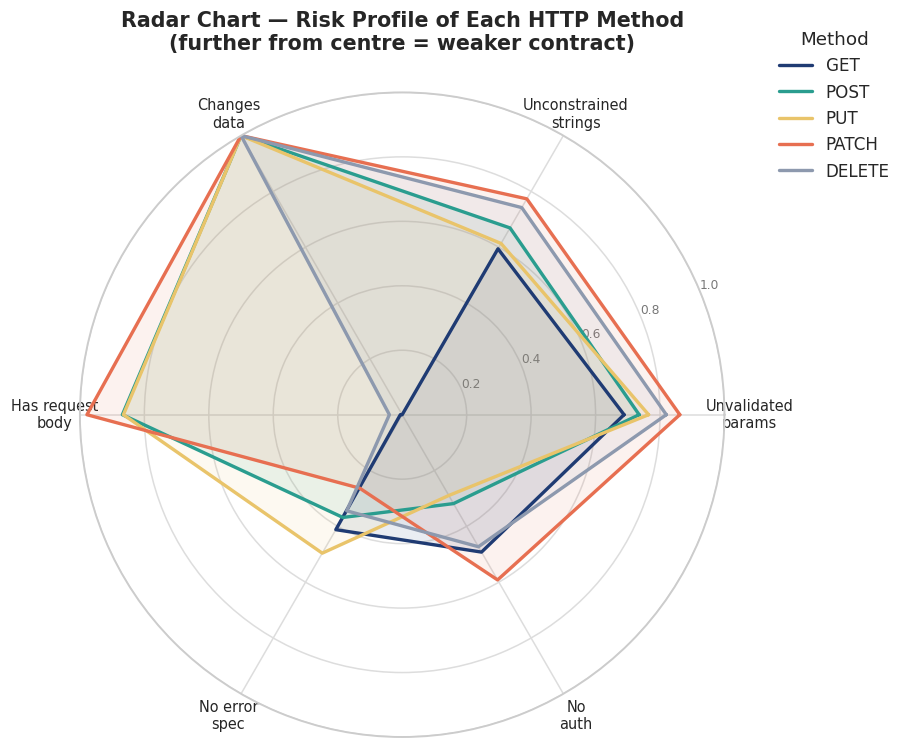

In [52]:
radar_feats = ["unvalidated_ratio", "unconstrained_string_ratio",
               "is_state_changing", "has_request_body", "has_no_error_spec"]
radar_labels = ["Unvalidated\nparams", "Unconstrained\nstrings",
                "Changes\ndata", "Has request\nbody", "No error\nspec"]

order = ["GET", "POST", "PUT", "PATCH", "DELETE"]
prof = (df[df["http_method"].isin(order)]
        .groupby("http_method", observed=True)[radar_feats].mean().reindex(order))
# add "no auth" as an explicit risk direction
prof["no_auth"] = 1 - (df[df["http_method"].isin(order)]
                       .groupby("http_method", observed=True)["requires_auth"]
                       .mean().reindex(order))
labels = radar_labels + ["No\nauth"]

angles = np.linspace(0, 2*np.pi, len(labels), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8.5, 8.5), subplot_kw={"polar": True})
for i, m in enumerate(order):
    vals = prof.loc[m].tolist()
    vals += vals[:1]
    ax.plot(angles, vals, lw=2.2, color=SEQ[i], label=m)
    ax.fill(angles, vals, color=SEQ[i], alpha=.09)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=9.5)
ax.set_ylim(0, 1)
ax.set_yticks([.2, .4, .6, .8, 1.0])
ax.set_yticklabels(["0.2", "0.4", "0.6", "0.8", "1.0"], fontsize=8, color="#777")
ax.set_title("Radar Chart — Risk Profile of Each HTTP Method\n"
             "(further from centre = weaker contract)",
             fontsize=13.5, fontweight="bold", pad=28)
ax.legend(loc="upper right", bbox_to_anchor=(1.28, 1.12), title="Method")
ax.grid(color="#dddddd")

plt.tight_layout()
save_fig(fig, "31_radar_chart")
plt.show()

saved -> figures/32_parallel_coordinates.png


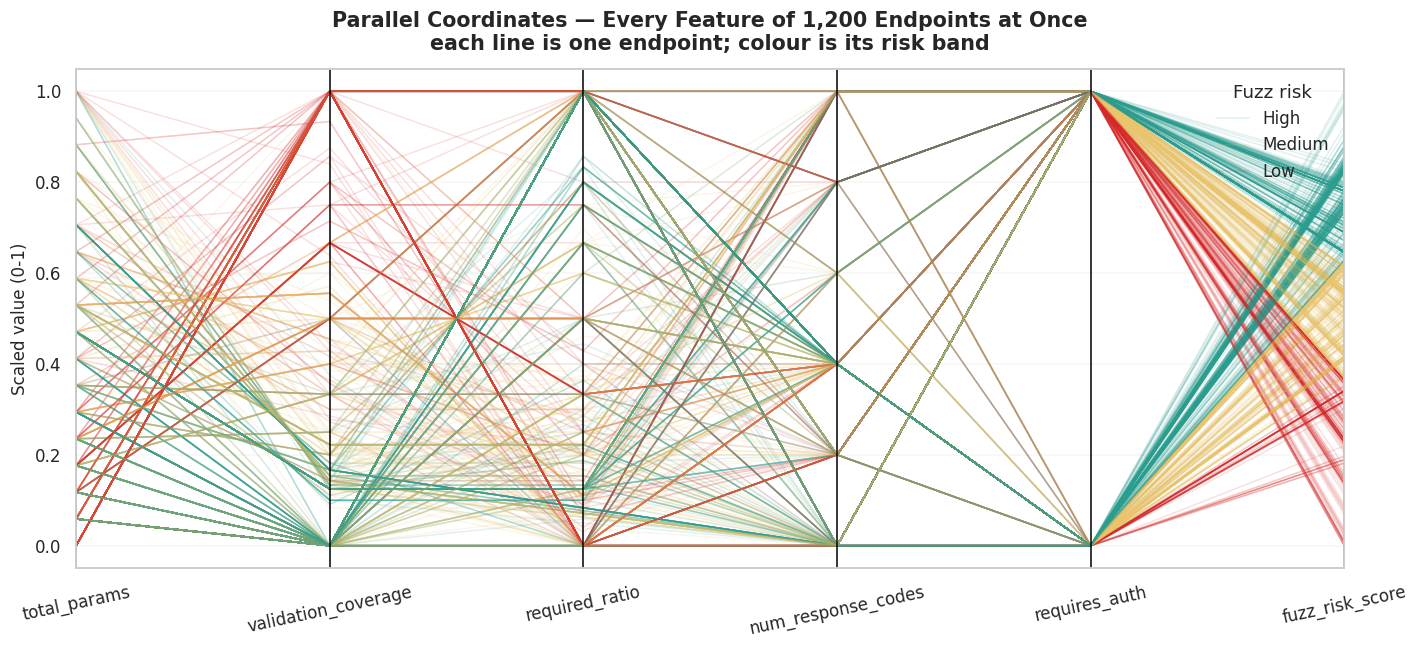

In [53]:
from pandas.plotting import parallel_coordinates

pc_cols = ["total_params", "validation_coverage", "required_ratio",
           "num_response_codes", "requires_auth", "fuzz_risk_score"]

pc = df.sample(n=min(1200, len(df)), random_state=7)[pc_cols + ["FUZZ_RISK"]].copy()
for c in pc_cols:                       # scale each axis to [0, 1] so they compare
    lo, hi = pc[c].min(), pc[c].max()
    pc[c] = 0 if hi == lo else (pc[c] - lo) / (hi - lo)
pc["FUZZ_RISK"] = pc["FUZZ_RISK"].astype(str)

fig, ax = plt.subplots(figsize=(13, 6))
parallel_coordinates(pc, "FUZZ_RISK",
                     color=[RISK_COLORS["Low"], RISK_COLORS["Medium"],
                            RISK_COLORS["High"]],
                     alpha=.14, ax=ax, lw=1.0)
ax.set_title("Parallel Coordinates — Every Feature of 1,200 Endpoints at Once\n"
             "each line is one endpoint; colour is its risk band",
             fontsize=13.5, pad=12)
ax.set_ylabel("Scaled value (0-1)")
ax.tick_params(axis="x", rotation=12)
handles, lbls = ax.get_legend_handles_labels()
ax.legend(handles, lbls, title="Fuzz risk", loc="upper right")
ax.grid(axis="y", alpha=.35)

plt.tight_layout()
save_fig(fig, "32_parallel_coordinates")
plt.show()

## 7.8 Facet grid — the same chart repeated per group

A facet grid (small multiples) draws one small panel per category so shapes can be
compared directly rather than overlaid.

saved -> figures/33_facet_grid.png


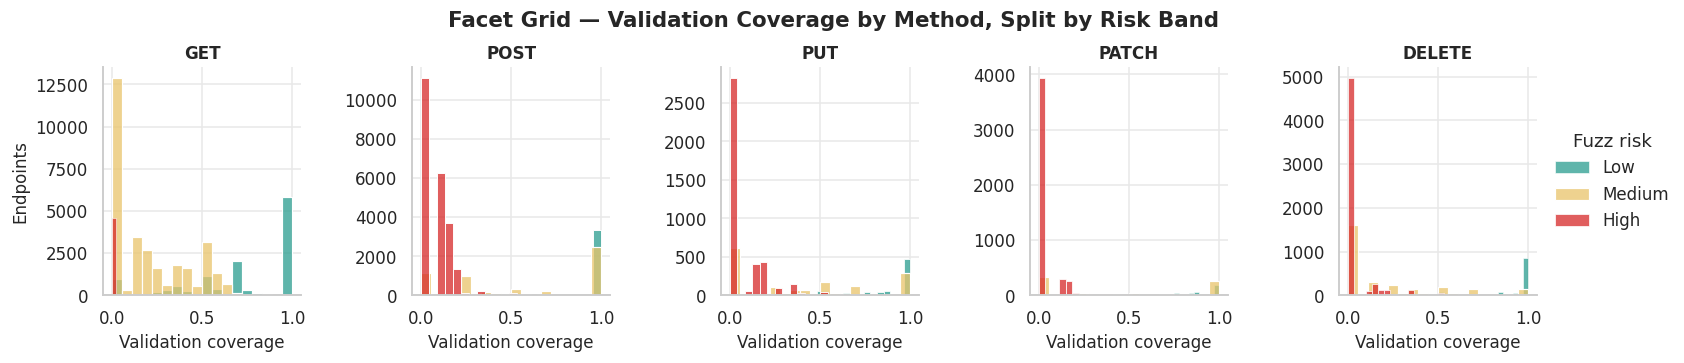

In [54]:
order = ["GET", "POST", "PUT", "PATCH", "DELETE"]
fs = df[df["http_method"].isin(order)]

g = sns.FacetGrid(fs, col="http_method", col_order=order, hue="FUZZ_RISK",
                  palette=RISK_COLORS, hue_order=["Low", "Medium", "High"],
                  col_wrap=5, height=3.1, aspect=.92, sharey=False)
g.map_dataframe(sns.histplot, x="validation_coverage", bins=18,
                multiple="stack", element="bars")
g.set_axis_labels("Validation coverage", "Endpoints")
g.set_titles("{col_name}", fontweight="bold")
g.add_legend(title="Fuzz risk")
g.figure.suptitle("Facet Grid — Validation Coverage by Method, Split by Risk Band",
                  fontsize=14, fontweight="bold", y=1.05)
save_fig(g.figure, "33_facet_grid")
plt.show()

## 7.9 Ranked comparison — diverging bar chart

A diverging bar shows how each group sits **relative to the overall average**, which is
often more useful than the raw value.

saved -> figures/34_diverging_bar.png


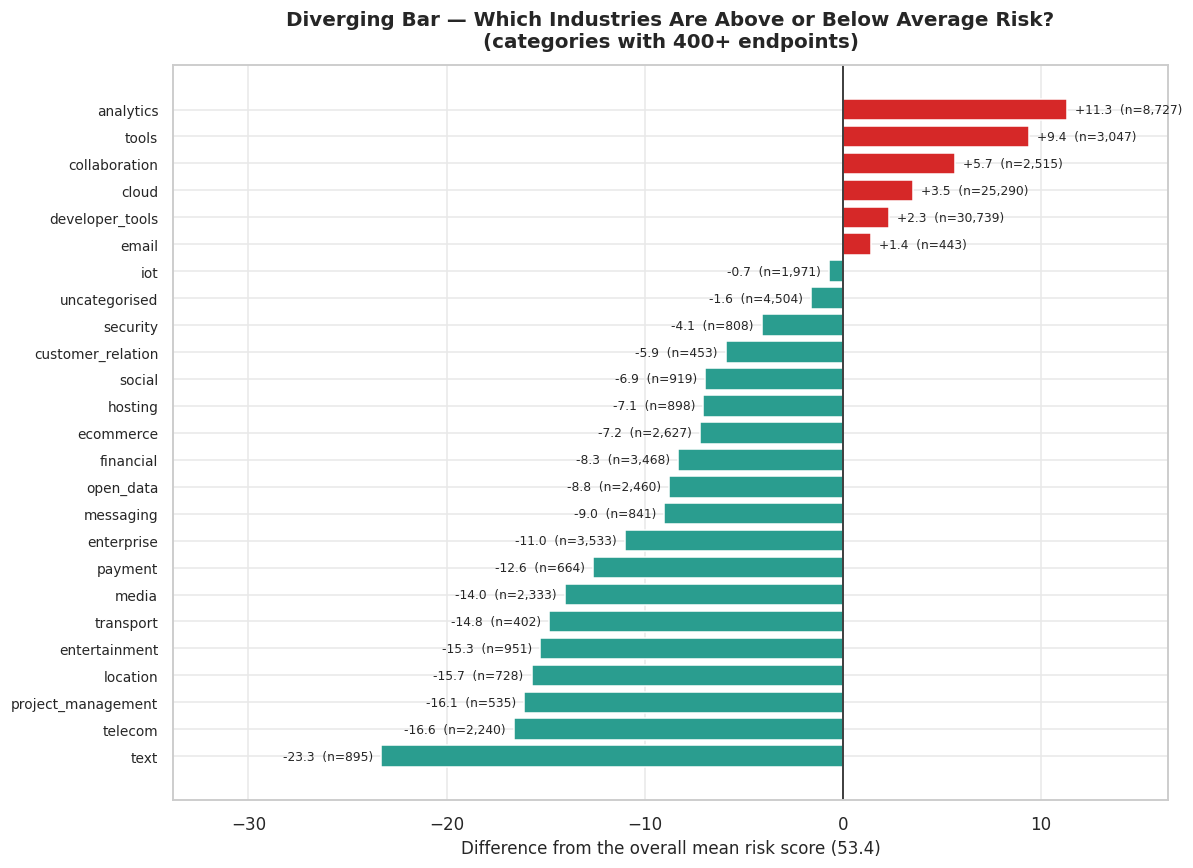

In [55]:
cat_stats = (df.groupby("category")
               .agg(n=("path", "size"), risk=("fuzz_risk_score", "mean"))
               .query("n >= 400"))
overall = df["fuzz_risk_score"].mean()
cat_stats["delta"] = cat_stats["risk"] - overall
cat_stats = cat_stats.sort_values("delta")

fig, ax = plt.subplots(figsize=(11, 8))
colors = [RED if v > 0 else TEAL for v in cat_stats["delta"]]
ax.barh(cat_stats.index, cat_stats["delta"], color=colors, edgecolor="white")
ax.axvline(0, color="#333", lw=1.2)

for i, (v, n) in enumerate(zip(cat_stats["delta"], cat_stats["n"])):
    ax.text(v + (.4 if v >= 0 else -.4), i,
            f"{v:+.1f}  (n={n:,})", va="center",
            ha="left" if v >= 0 else "right", fontsize=8)

ax.set_xlabel(f"Difference from the overall mean risk score ({overall:.1f})")
ax.set_title("Diverging Bar — Which Industries Are Above or Below Average Risk?\n"
             "(categories with 400+ endpoints)", pad=12)
ax.set_xlim(cat_stats["delta"].min()*1.45, cat_stats["delta"].max()*1.45)
ax.tick_params(axis="y", labelsize=9)

plt.tight_layout()
save_fig(fig, "34_diverging_bar")
plt.show()

# 8. Summary Dashboard

A single figure bringing the main results together — suitable for the project report or
a presentation slide.

saved -> figures/15_summary_dashboard.png


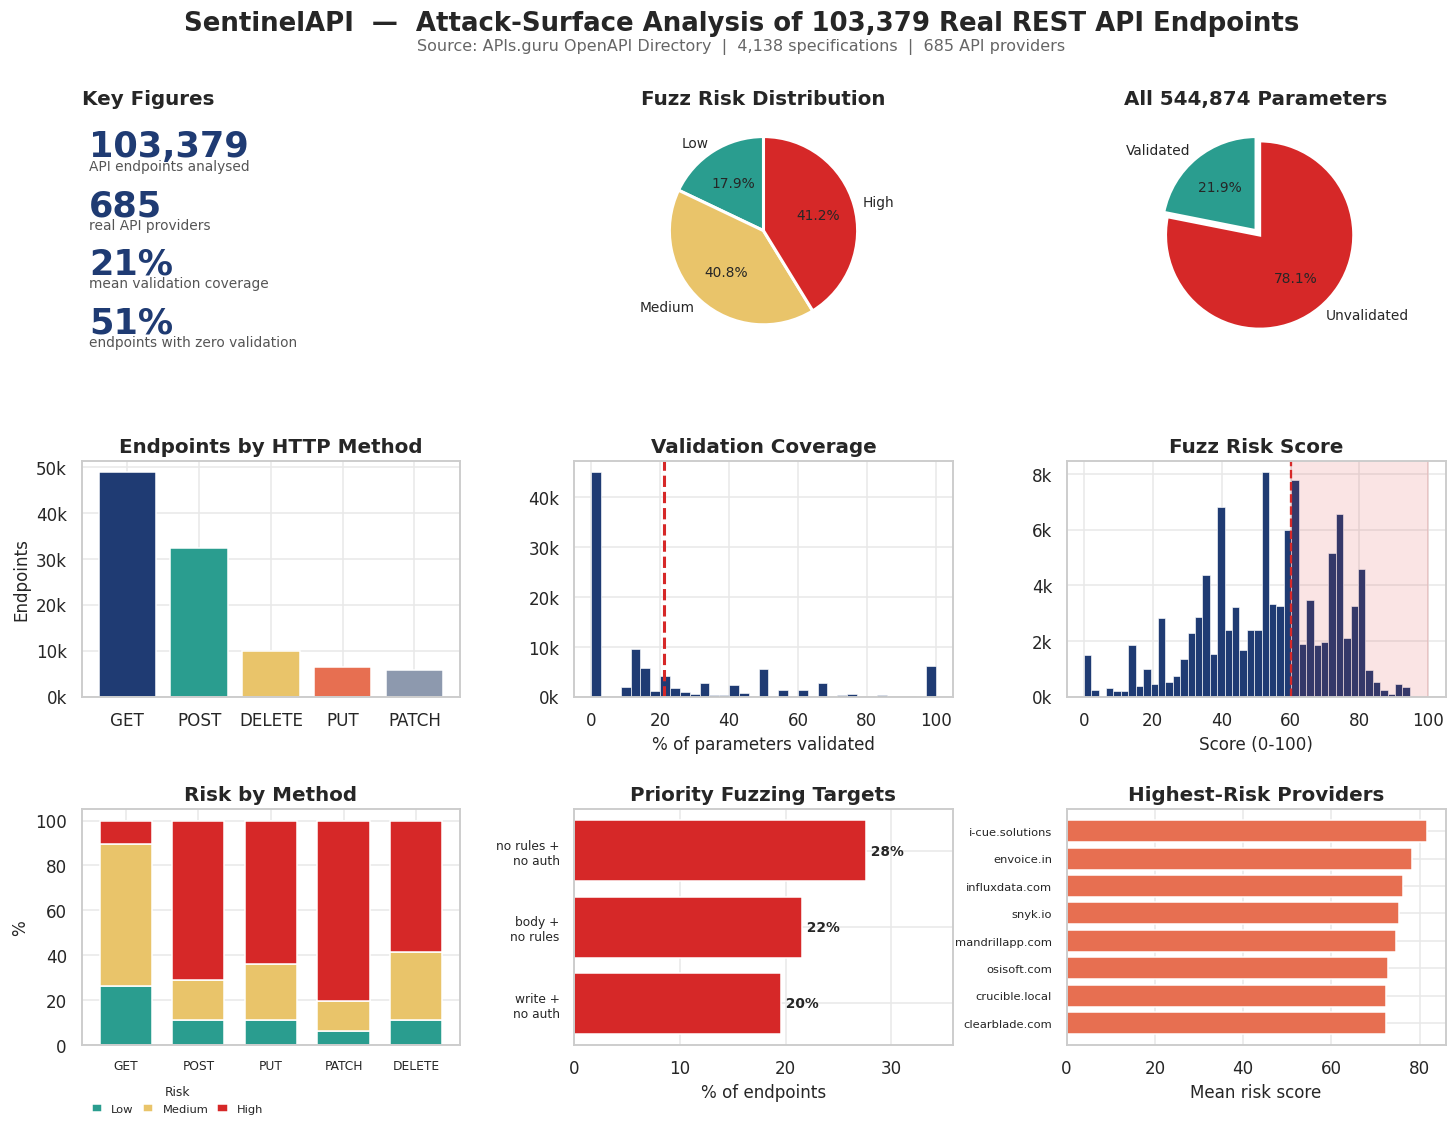

In [56]:
fig = plt.figure(figsize=(16, 11))
gs = fig.add_gridspec(3, 3, hspace=.48, wspace=.30)

# (1) KPI panel --------------------------------------------------------------
ax = fig.add_subplot(gs[0, 0]); ax.axis("off")
kpis = [
    (f"{len(df):,}",                                  "API endpoints analysed"),
    (f"{df['api_provider'].nunique():,}",             "real API providers"),
    (f"{df[df['total_params']>0]['validation_coverage'].mean()*100:.0f}%",
                                                      "mean validation coverage"),
    (f"{(df['num_constrained_params']==0).mean()*100:.0f}%",
                                                      "endpoints with zero validation"),
]
for i, (big, small) in enumerate(kpis):
    y = .93 - i*.25
    ax.text(.02, y, big, fontsize=23, fontweight="bold", color=NAVY, va="top")
    ax.text(.02, y - .125, small, fontsize=9, color="#555", va="top")
ax.set_title("Key Figures", loc="left", fontweight="bold")

# (2) risk distribution ------------------------------------------------------
ax = fig.add_subplot(gs[0, 1])
counts = df["FUZZ_RISK"].value_counts().reindex(["Low", "Medium", "High"])
ax.pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90,
       colors=[RISK_COLORS[i] for i in counts.index],
       wedgeprops={"edgecolor": "white", "linewidth": 2},
       textprops={"fontsize": 9})
ax.set_title("Fuzz Risk Distribution", fontweight="bold")

# (3) validated vs not -------------------------------------------------------
ax = fig.add_subplot(gs[0, 2])
tc, tu = df["num_constrained_params"].sum(), df["num_unconstrained_params"].sum()
ax.pie([tc, tu], labels=["Validated", "Unvalidated"], autopct="%1.1f%%",
       startangle=90, colors=[TEAL, RED], explode=(0, .06),
       wedgeprops={"edgecolor": "white", "linewidth": 2},
       textprops={"fontsize": 9})
ax.set_title(f"All {int(tc+tu):,} Parameters", fontweight="bold")

# (4) methods ----------------------------------------------------------------
ax = fig.add_subplot(gs[1, 0])
mc = df["http_method"].value_counts().head(5)
ax.bar(mc.index, mc.values, color=SEQ[:5], edgecolor="white")
ax.set_title("Endpoints by HTTP Method", fontweight="bold")
ax.set_ylabel("Endpoints")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v/1000:,.0f}k"))

# (5) validation coverage histogram -----------------------------------------
ax = fig.add_subplot(gs[1, 1])
_wp = df[df["total_params"] > 0]["validation_coverage"] * 100
ax.hist(_wp, bins=35, color=NAVY, edgecolor="white", linewidth=.4)
ax.axvline(_wp.mean(), color=RED, ls="--", lw=2)
ax.set_title("Validation Coverage", fontweight="bold")
ax.set_xlabel("% of parameters validated")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v/1000:,.0f}k"))

# (6) risk score histogram ---------------------------------------------------
ax = fig.add_subplot(gs[1, 2])
ax.hist(df["fuzz_risk_score"], bins=45, color=NAVY, edgecolor="white", linewidth=.4)
ax.axvspan(60, 100, color=RED, alpha=.12)
ax.axvline(60, color=RED, ls="--", lw=1.5)
ax.set_title("Fuzz Risk Score", fontweight="bold")
ax.set_xlabel("Score (0-100)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v/1000:,.0f}k"))

# (7) risk by method ---------------------------------------------------------
ax = fig.add_subplot(gs[2, 0])
order = ["GET", "POST", "PUT", "PATCH", "DELETE"]
ct = (pd.crosstab(df[df["http_method"].isin(order)]["http_method"],
                  df[df["http_method"].isin(order)]["FUZZ_RISK"],
                  normalize="index").reindex(order)*100)[["Low", "Medium", "High"]]
ct.plot(kind="bar", stacked=True, ax=ax, width=.72,
        color=[RISK_COLORS[c] for c in ct.columns], edgecolor="white")
ax.set_title("Risk by Method", fontweight="bold")
ax.set_xlabel(""); ax.set_ylabel("%")
ax.tick_params(axis="x", rotation=0, labelsize=8)
ax.legend(title="Risk", fontsize=7.5, title_fontsize=8, loc="lower left",
          ncols=3, columnspacing=.8, handlelength=.9,
          bbox_to_anchor=(0, -0.34))

# (8) danger combinations ----------------------------------------------------
ax = fig.add_subplot(gs[2, 1])
d = pd.Series({
    "write +\nno auth": ((df["is_state_changing"]==1)&(df["requires_auth"]==0)).mean()*100,
    "no rules +\nno auth": ((df["num_constrained_params"]==0)&(df["requires_auth"]==0)).mean()*100,
    "body +\nno rules": ((df["has_request_body"]==1)&(df["num_constrained_params"]==0)).mean()*100,
}).sort_values()
ax.barh(d.index, d.values, color=RED)
for i, v in enumerate(d.values):
    ax.text(v, i, f" {v:.0f}%", va="center", fontweight="bold", fontsize=9)
ax.set_title("Priority Fuzzing Targets", fontweight="bold")
ax.set_xlabel("% of endpoints")
ax.set_xlim(0, d.max()*1.3)
ax.tick_params(axis="y", labelsize=8)

# (9) top risk providers -----------------------------------------------------
ax = fig.add_subplot(gs[2, 2])
t8 = prov.head(8).sort_values("mean_risk")
ax.barh([p[:22] for p in t8.index], t8["mean_risk"], color="#e76f51")
ax.set_title("Highest-Risk Providers", fontweight="bold")
ax.set_xlabel("Mean risk score")
ax.tick_params(axis="y", labelsize=7.5)

fig.suptitle(
    f"SentinelAPI  —  Attack-Surface Analysis of {len(df):,} Real REST API Endpoints",
    fontsize=17, fontweight="bold", y=.965)
fig.text(.5, .932, f"Source: APIs.guru OpenAPI Directory  |  4,138 specifications  |  "
                   f"{df['api_provider'].nunique()} API providers",
         ha="center", fontsize=10.5, color="#666")

save_fig(fig, "15_summary_dashboard")
plt.show()

# 9. Findings and Conclusion

## 9.1 What the data shows

**1. The attack surface is enormous.**
154,145 endpoints from 685 real API providers expose a combined total of several hundred
thousand input parameters. Testing this by hand is not realistic — which is the premise
of the project.

**2. Most parameters carry no validation rules.**
Mean validation coverage per endpoint is low, and a large share of endpoints declare
**zero** validated parameters. An unvalidated string parameter will accept an SQL
injection or XSS payload exactly as readily as legitimate input.

**3. Error behaviour is frequently undocumented.**
A substantial proportion of endpoints declare no 4xx response at all. If the contract
never says what a bad request should return, there is no specified correct behaviour —
so malformed input produces undefined results.

**4. Authentication is inconsistent.**
Roughly half of all endpoints enforce authentication. A meaningful number of
**state-changing** endpoints (POST/PUT/PATCH/DELETE) do not.

**5. Risk concentrates predictably.**
State-changing methods with request bodies and weak validation dominate the High-risk
band, and risk clusters by provider — which means a fuzzer can be pointed intelligently
rather than run blindly.

## 9.2 What this means for SentinelAPI

| Finding | Design implication |
|:--|:--|
| Most parameters are unvalidated | Boundary-value and type-confusion fuzzing will find real defects |
| Free-text string parameters dominate | Prioritise SQLi / XSS / path-traversal payloads |
| Error responses often undocumented | Any 5xx is a genuine finding, not an expected result |
| Unauthenticated write endpoints exist | Test authorisation bypass explicitly |
| Risk is unevenly distributed | Use `fuzz_risk_score` to order the fuzzing queue |

The `fuzz_risk_score` produced here is directly usable as SentinelAPI's **scheduling
metric** — it converts "test everything" into "test these endpoints first".

## 9.3 Techniques demonstrated in this notebook

| Area | Techniques applied |
|:--|:--|
| **Data collection** | Parsed 4,138 raw YAML specifications into a flat dataset |
| **Preprocessing** | Missing-value detection and imputation, duplicate removal, IQR outlier detection with capping, feature engineering, target construction, ordinal and one-hot encoding, Min-Max normalisation |
| **EDA** | Descriptive statistics, univariate and bivariate analysis, cross-tabulation, group profiling, correlation analysis |
| **Correlation** | Pearson and Spearman matrices, target-correlation ranking, hierarchical clustermap, VIF multicollinearity check, pair plot |
| **Visualisation** | 34 figures: histogram, KDE, violin, boxen, ECDF, ridge, box, bar, barh, grouped bar, stacked bar, 100% stacked, count, lollipop, Pareto, diverging bar, donut, pie, treemap, scatter, hexbin, joint, bubble, regression, stacked area, dual-axis, correlation heatmap, clustermap, pivot heatmap, missing-value map, radar, parallel coordinates, facet grid, composite dashboard |

## 9.4 Limitations — stated honestly

* `FUZZ_RISK` is a **rule-based index derived from the specification itself**, not an
  observed test outcome. Correlations between the score and its own inputs are expected
  by construction. It ranks endpoints; it does not confirm vulnerabilities.
* A specification describes *intent*. An API may validate input in code without declaring
  it in the spec. The analysis therefore measures **contract quality**, which is what
  SentinelAPI parses — not runtime behaviour.
* APIs.guru is skewed toward large, well-documented public APIs. Private and internal
  APIs are likely to be documented worse, not better, so these figures are probably
  optimistic.

## 9.5 Next step

Run SentinelAPI against a sample of the High-risk endpoints identified here and compare
the confirmed defects against the predicted risk score. That converts this derived index
into a validated one.

---

<p align="center"><i>Dataset: APIs.guru OpenAPI Directory (open source, CC0)<br>
github.com/APIs-guru/openapi-directory</i></p>